# Retrieval Evaluation & Vector Search Internals — a working reference lab

**Companion to** `alexandre_ai_engineer_rag_with_evaluation.ipynb`. That notebook is the interview task.
This one is the *reference implementation of the two things the feedback asked for*, built so you can run it,
break it, and re-run it:

> **Retrieval evaluation** — "more depth in measuring retrieval quality (for example recall at k, MRR or NDCG
> over a labelled query set). On client projects, this is how you show that a RAG system actually works and
> that a change made it better."
>
> **Vector search internals** — "limited exposure to index types, their trade-offs and reranking. Clients
> often expect the engineer to choose and tune these on their own."

### How this notebook is organised

| Part | Section | What you walk away able to do |
|---|---|---|
| **Setup** | 1 | Run everything offline, or with Claude when a key is present |
| **Data & labels** | 2–3 | Chunk a corpus and build a *labelled query set* with graded relevance |
| **Evaluation** | 4 | Implement recall@k, MRR, MAP, NDCG@k from scratch and trust them (they are unit-tested) |
| **Comparison** | 5–6 | Compare BM25 / dense / hybrid and prove a change helped with a **paired bootstrap CI** |
| **Internals** | 7 | Build Flat, IVF, HNSW, PQ/int8/binary indexes **from scratch**, measure the trade-offs, map them onto FAISS |
| **Reranking** | 8 | Cross-encoder, LLM listwise and MMR reranking, measured as NDCG lift per millisecond |
| **End to end** | 9 | A `RAGSystem` with citations, calibrated abstention and a groundedness judge |
| **Practice** | 10 | A config sweep harness and 10 exercises to customise |

### Three rules this notebook follows

1. **Every number is measured in the notebook.** No quoted benchmarks, no "HNSW is faster" without a timing.
2. **Every metric implementation is tested** against a hand-worked example (and NDCG against scikit-learn).
3. **Every claim that a change helped comes with a confidence interval** — a single aggregate number over
   26 queries is noise, and saying so is what separates an engineer from a demo.

> **Runtime:** ~2–4 minutes end to end on CPU, fully offline. The pure-Python HNSW build (§7.5) is the slowest
> single cell (~15 s) — that is the price of readable code, and §7.8 shows the same thing in FAISS at C++ speed.

---
## 1. Setup

Run `Kernel → Restart and Run All` once; then work cell by cell.

**Kernel:** pick `Python (ragging-lab)` (top-right in VS Code). It is the `.venv` in this repo.

**Claude (optional but on by default).** Sections 3.4, 8.2, 9.3 and 9.4 use Claude for synthetic query
generation, listwise reranking, grounded generation and LLM-as-judge groundedness. The notebook looks for a
key, *probes it with one tiny call*, and if anything fails it silently switches to deterministic offline
implementations of the same interfaces. Nothing below breaks without a key — you just get the rule-based
variants, which are worth studying anyway because they are what you fall back on when latency or budget
rules out an LLM in the loop.

In [1]:
# --- 1.1 imports, configuration, plotting ------------------------------------------------------
from __future__ import annotations

import heapq
import json
import math
import os
import re
import statistics
import sys
import textwrap
import time
import warnings
from collections import Counter, defaultdict
from dataclasses import dataclass, field, asdict
from typing import Any, Callable, Iterable, Sequence

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 68)


@dataclass
class Config:
    """Every knob in one place. Changing these is the point of the notebook."""

    # ---- reproducibility
    seed: int = 42

    # ---- chunking (§2)
    chunk_sentences: int = 2        # sentences per chunk
    chunk_stride: int = 1           # sentence step between chunks -> overlap = chunk_sentences - stride

    # ---- retrieval (§5-6)
    top_k: int = 5                  # what the generator sees
    eval_ks: tuple = (1, 3, 5, 10)  # k values reported in metric tables
    candidate_depth: int = 20       # first-stage depth before reranking (§8)
    rrf_k: int = 60                 # RRF damping constant

    # ---- vector-search internals (§7)
    ann_n: int = 12_000             # synthetic vectors; pure-Python HNSW build is O(n log n)
    ann_dim: int = 128
    ann_latent_dim: int = 10        # effective dimensionality of the synthetic manifold
    ann_noise: float = 0.05
    ann_queries: int = 100
    ann_k: int = 10

    # ---- models
    embed_model: str = "sentence-transformers/all-MiniLM-L6-v2"
    cross_encoder_model: str = "cross-encoder/ms-marco-MiniLM-L6-v2"
    claude_model: str = "claude-opus-5"
    # A cheaper judge/reranker is a legitimate cost choice: "claude-sonnet-5" or "claude-haiku-4-5".
    claude_judge_model: str = "claude-opus-5"
    claude_max_tokens: int = 2048

    # ---- behaviour flags
    use_claude: bool = True         # set False to force the fully offline path
    prompt_for_key: bool = False    # True -> getpass prompt when no key is in the environment
    use_server_side_fallback: bool = True  # Claude refusal fallbacks; auto-disabled if not enabled for the org


CFG = Config()
RNG = np.random.default_rng(CFG.seed)

# --- plotting -----------------------------------------------------------------------------------
import matplotlib as mpl
import matplotlib.pyplot as plt

# Categorical palette in FIXED slot order (never cycled, never re-assigned by rank).
# Validated for colour-vision deficiency: worst adjacent pair deltaE 9.2 (deutan), normal-vision 27.6.
# The first four slots also clear the all-pairs gate, which is what scatter plots need.
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#4a3aa7", "#e34948"]  # blue, orange, aqua, violet, red
INK, INK_SOFT, GRID = "#0b0b0b", "#52514e", "#dcdbd6"
# Every chart in this notebook is printed next to its own DataFrame: that table IS the accessible
# "table view", which is what the low-contrast slots (aqua) require, and it is also how you paste
# numbers into a client report.
mpl.rcParams.update({
    "figure.figsize": (7.2, 4.0), "figure.dpi": 120, "savefig.dpi": 160,
    "axes.prop_cycle": mpl.cycler(color=SERIES),
    "axes.edgecolor": GRID, "axes.labelcolor": INK_SOFT, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelsize": 9.5,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "grid.alpha": 0.9,
    "xtick.color": INK_SOFT, "ytick.color": INK_SOFT, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "lines.linewidth": 2.0, "lines.markersize": 5.5,
    "legend.frameon": False, "legend.fontsize": 9,
    "font.size": 10,
})


def finish(ax, title=None, xlabel=None, ylabel=None, legend=True):
    """Shared chart furniture: a title that states the finding, recessive axes, a legend when >=2 series."""
    if title:
        ax.set_title(title, loc="left", pad=10)
    if xlabel:
        ax.set_xlabel(xlabel)
    if ylabel:
        ax.set_ylabel(ylabel)
    handles, _ = ax.get_legend_handles_labels()
    if legend and len(handles) >= 2:
        ax.legend(loc="best")
    ax.set_axisbelow(True)
    return ax


print(f"python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__}")
print(CFG)

python 3.12.10 | numpy 2.5.5 | pandas 3.1.1
Config(seed=42, chunk_sentences=2, chunk_stride=1, top_k=5, eval_ks=(1, 3, 5, 10), candidate_depth=20, rrf_k=60, ann_n=12000, ann_dim=128, ann_latent_dim=10, ann_noise=0.05, ann_queries=100, ann_k=10, embed_model='sentence-transformers/all-MiniLM-L6-v2', cross_encoder_model='cross-encoder/ms-marco-MiniLM-L6-v2', claude_model='claude-opus-5', claude_judge_model='claude-opus-5', claude_max_tokens=2048, use_claude=True, prompt_for_key=False, use_server_side_fallback=True)


### 1.2 The Claude client — and what "graceful degradation" actually means

Three things worth copying into client code:

1. **Probe, don't assume.** A key in the environment proves nothing: it can be revoked, out of credit, or
   scoped to the wrong workspace. One ~10-token call at startup turns a run-time surprise into a
   start-up fact. In a service you do this in a health check, not per request.
2. **Catch the specific errors.** `AuthenticationError` (401) and `PermissionDeniedError` (403) are
   permanent — stop using the client. `RateLimitError` (429) and `APIConnectionError` are transient —
   the SDK already retries those twice, so the right move is to let it, not to disable the feature.
3. **Make the fallback an implementation of the same interface.** `LLM.json()` either returns a validated
   object or `None`. Callers branch once, at the boundary — not in ten places.

Two API details that regularly get written wrong, and are written correctly here:

- **Structured output** uses `client.messages.parse(..., output_format=PydanticModel)`, which validates the
  response against the schema. Hand-rolled "respond only with JSON" prompting plus `json.loads` is the thing
  it replaces — no fence-stripping, no repair loop.
- **Always check `stop_reason` before reading `content`.** On a `refusal` the call returns HTTP 200 with
  no usable text. Server-side `fallbacks` re-route such a request to another model automatically; we enable
  it when the organisation has the beta, and detect-and-disable when it does not.

In [2]:
# --- 1.2 Claude client with probe + graceful offline fallback -----------------------------------
try:
    import anthropic
    from pydantic import BaseModel, Field
    _ANTHROPIC_IMPORTED = True
except Exception as exc:  # pragma: no cover - only if the package is missing
    _ANTHROPIC_IMPORTED = False
    _IMPORT_ERR = exc


def _load_dotenv_key() -> str | None:
    """Minimal .env reader so a key can live next to the notebook instead of in the shell."""
    for path in (".env", os.path.join("..", ".env")):
        if not os.path.exists(path):
            continue
        for line in open(path, encoding="utf-8"):
            line = line.strip()
            if line.startswith("ANTHROPIC_API_KEY") and "=" in line:
                return line.split("=", 1)[1].strip().strip('"').strip("'")
    return None


class LLM:
    """Claude wrapper that degrades to `available=False` instead of raising.

    `text()` and `json()` return `None` when the model is unavailable; callers fall back deterministically.
    Usage and call counts are tracked because "what will this cost in production" is always the next question.
    """

    def __init__(self, cfg: Config):
        self.cfg = cfg
        self.available = False
        self.model = cfg.claude_model
        self.notes: list[str] = []
        self.calls = 0
        self.input_tokens = 0
        self.output_tokens = 0
        self._betas: list[str] = []
        self._fallbacks: Any = None
        self.client = None
        if not cfg.use_claude:
            self.notes.append("disabled by Config.use_claude=False")
            return
        if not _ANTHROPIC_IMPORTED:
            self.notes.append(f"anthropic import failed: {_IMPORT_ERR}")
            return
        key = os.environ.get("ANTHROPIC_API_KEY") or _load_dotenv_key()
        if not key and cfg.prompt_for_key:
            import getpass
            key = getpass.getpass("ANTHROPIC_API_KEY (blank to stay offline): ").strip() or None
        try:
            # With no explicit key the SDK still resolves ANTHROPIC_AUTH_TOKEN or an `ant auth login`
            # profile, so a bare constructor is the right default rather than an error.
            self.client = anthropic.Anthropic(api_key=key) if key else anthropic.Anthropic()
        except Exception as exc:
            self.notes.append(f"client construction failed: {type(exc).__name__}: {exc}")
            return
        self._probe()

    # -- capability probe -------------------------------------------------------------------
    def _classify(self, exc) -> str:
        """Turn an exception into a reason a human can act on.

        The distinction that matters operationally: 401/403 and missing credentials are PERMANENT, so
        stop using the client; 429 and connection errors are TRANSIENT and the SDK already retries them
        twice, so they should not disable a feature.
        """
        msg = str(exc)
        if isinstance(exc, (anthropic.AuthenticationError, anthropic.PermissionDeniedError)):
            return f"credentials rejected ({type(exc).__name__})"
        if isinstance(exc, TypeError) and re.search(r"authentication|api_key|auth_token", msg, re.I):
            return "no credentials found (set ANTHROPIC_API_KEY, or run `ant auth login`)"
        if isinstance(exc, anthropic.NotFoundError):
            return f"model {self.model} not available to this organisation"
        if isinstance(exc, (anthropic.PaymentRequiredError, anthropic.CredentialsError)):
            return f"billing/credentials problem ({type(exc).__name__})"
        if isinstance(exc, anthropic.APIConnectionError):
            return "network unreachable"
        if isinstance(exc, anthropic.RateLimitError):
            return "rate limited even on a 16-token probe"
        if isinstance(exc, (anthropic.BadRequestError, TypeError)):
            return f"beta-unavailable:{type(exc).__name__}"
        return f"unexpected {type(exc).__name__}: {msg[:90]}"

    def _probe(self) -> None:
        """One ~10-token call at start-up, so a run-time surprise becomes a start-up fact.

        Tries the server-side refusal fallbacks first and silently drops them if this organisation (or
        this SDK version) does not have them, rather than failing the whole feature over an extra flag.
        """
        plans = []
        if self.cfg.use_server_side_fallback:
            plans.append((["server-side-fallback-2026-07-01"], "default"))
        plans.append(([], None))
        for betas, fallbacks in plans:
            self._betas, self._fallbacks = betas, fallbacks
            try:
                self._raw(messages=[{"role": "user", "content": "Reply with the single word: ok"}],
                          max_tokens=16)
                self.available = True
                self.notes.append(f"online: {self.model}"
                                  + (" + server-side refusal fallbacks" if fallbacks else ""))
                return
            except Exception as exc:
                reason = self._classify(exc)
                if reason.startswith("beta-unavailable") and betas:
                    self.notes.append("server-side fallbacks not available here; retrying without them")
                    continue
                self.notes.append("offline: " + reason.replace("beta-unavailable:", "bad request, "))
                break
        self._betas, self._fallbacks = [], None

    # -- low-level call ---------------------------------------------------------------------
    def _raw(self, *, messages, max_tokens, system=None, model=None, output_format=None):
        kwargs: dict[str, Any] = {
            "model": model or self.model,
            "max_tokens": max_tokens,
            "messages": messages,
        }
        if system:
            kwargs["system"] = system
        if self._betas:
            kwargs["betas"] = self._betas
            kwargs["fallbacks"] = self._fallbacks
        # `betas`/`fallbacks` are only accepted on the beta namespace; the stable one raises TypeError.
        api = self.client.beta.messages if self._betas else self.client.messages
        if output_format is not None:
            resp = api.parse(output_format=output_format, **kwargs)
        else:
            resp = api.create(**kwargs)
        self.calls += 1
        usage = getattr(resp, "usage", None)
        if usage:
            self.input_tokens += getattr(usage, "input_tokens", 0) or 0
            self.output_tokens += getattr(usage, "output_tokens", 0) or 0
        return resp

    # -- public helpers ---------------------------------------------------------------------
    def text(self, prompt: str, system: str | None = None, model: str | None = None,
             max_tokens: int | None = None) -> str | None:
        if not self.available:
            return None
        try:
            resp = self._raw(messages=[{"role": "user", "content": prompt}], system=system,
                             model=model, max_tokens=max_tokens or self.cfg.claude_max_tokens)
            if resp.stop_reason == "refusal":  # HTTP 200 but no usable content
                return None
            return "".join(b.text for b in resp.content if b.type == "text").strip() or None
        except Exception as exc:
            self.notes.append(f"text() failed: {type(exc).__name__}: {str(exc)[:100]}")
            return None

    def json(self, prompt: str, output_format, system: str | None = None, model: str | None = None,
             max_tokens: int | None = None):
        """Schema-validated structured output, or None. `output_format` is a pydantic model class."""
        if not self.available:
            return None
        try:
            resp = self._raw(messages=[{"role": "user", "content": prompt}], system=system,
                             model=model or self.cfg.claude_judge_model,
                             max_tokens=max_tokens or self.cfg.claude_max_tokens,
                             output_format=output_format)
            if resp.stop_reason == "refusal":
                return None
            return resp.parsed_output
        except Exception as exc:
            self.notes.append(f"json() failed: {type(exc).__name__}: {str(exc)[:100]}")
            return None

    # Rough cost estimate at Claude Opus 5 list prices ($5/MTok in, $25/MTok out).
    def cost_usd(self, in_per_mtok: float = 5.0, out_per_mtok: float = 25.0) -> float:
        return self.input_tokens / 1e6 * in_per_mtok + self.output_tokens / 1e6 * out_per_mtok

    def report(self) -> str:
        head = "ONLINE" if self.available else "OFFLINE"
        return f"[{head}] calls={self.calls} in={self.input_tokens} out={self.output_tokens} " \
               f"~${self.cost_usd():.4f} | " + " ; ".join(self.notes[-3:])


LLM_CLIENT = LLM(CFG)
print(LLM_CLIENT.report())
if not LLM_CLIENT.available:
    print("\n-> Offline mode. Everything runs; LLM cells use deterministic fallbacks.")
    print("   To go online: set ANTHROPIC_API_KEY (shell or a .env next to this notebook) and re-run,")
    print("   or set CFG.prompt_for_key = True and re-run this cell.")

[OFFLINE] calls=0 in=0 out=0 ~$0.0000 | offline: no credentials found (set ANTHROPIC_API_KEY, or run `ant auth login`)

-> Offline mode. Everything runs; LLM cells use deterministic fallbacks.
   To go online: set ANTHROPIC_API_KEY (shell or a .env next to this notebook) and re-run,
   or set CFG.prompt_for_key = True and re-run this cell.


### 1.3 Embeddings

Anthropic does not serve an embeddings endpoint — Claude is the reasoning/judging layer here, not the vector
layer. So embeddings come from one of three backends, in order of preference:

| Backend | Dim | When it is used | Realistic client analogue |
|---|---|---|---|
| `sentence-transformers/all-MiniLM-L6-v2` | 384 | Default; runs on CPU, no network after first download | A self-hosted open model — no per-token cost, no data egress |
| TF-IDF + truncated SVD (LSA) | 256 | Automatic fallback | A legacy baseline; still a surprisingly hard one to beat on small in-domain corpora |
| Hash-token random projection | 256 | Last resort | Nothing — it exists so this notebook never fails to run |

The wrapper caches vectors by text hash. That matters more than it looks: re-embedding a corpus on every
experiment is the single most common reason a RAG evaluation loop is too slow to iterate on.

**If a client asks "which embedding model?"** the answer is a measurement, not a brand. The evaluation
harness in §4–6 is exactly the apparatus for answering it: swap the backend, re-run, read the paired
bootstrap CI. §10 has it as exercise 1.

In [3]:
# --- 1.3 embedding backends with cache ----------------------------------------------------------
class Embedder:
    """Resolve the best available embedding backend. One `.encode()` for the whole notebook."""

    def __init__(self, cfg: Config):
        self.cfg = cfg
        self.backend = "none"
        self.dim = 0
        self._cache: dict[str, np.ndarray] = {}
        self._st = None
        self._svd = None
        self._tfidf = None
        self.note = ""
        try:
            from sentence_transformers import SentenceTransformer
            self._st = SentenceTransformer(cfg.embed_model)
            getter = getattr(self._st, "get_embedding_dimension", None) or                      self._st.get_sentence_embedding_dimension      # renamed in sentence-transformers 6
            self.dim = int(getter())
            self.backend = "sentence-transformers"
            self.note = cfg.embed_model
        except Exception as exc:
            self.note = f"sentence-transformers unavailable ({type(exc).__name__}); using TF-IDF+SVD"
            self.backend = "tfidf-svd"
            self.dim = 256

    # -- fitting is only needed by the fallback backends ------------------------------------
    def fit(self, corpus: Sequence[str]) -> "Embedder":
        if self.backend != "tfidf-svd":
            return self
        try:
            from sklearn.decomposition import TruncatedSVD
            from sklearn.feature_extraction.text import TfidfVectorizer
            self._tfidf = TfidfVectorizer(sublinear_tf=True, ngram_range=(1, 2), min_df=1)
            X = self._tfidf.fit_transform(corpus)
            self.dim = int(min(self.dim, max(2, min(X.shape) - 1)))
            self._svd = TruncatedSVD(n_components=self.dim, random_state=self.cfg.seed).fit(X)
        except Exception as exc:
            self.backend = "hash-projection"
            self.note = f"sklearn unavailable ({type(exc).__name__}); using hashed random projection"
        return self

    # -- last-resort backend: hashed bag of words through a fixed random projection ---------
    def _hash_encode(self, texts: Sequence[str]) -> np.ndarray:
        import zlib  # crc32, not hash(): str hashing is salted per process, so hash() is not reproducible
        buckets = 4096
        out = np.zeros((len(texts), buckets), dtype=np.float32)
        for i, t in enumerate(texts):
            for tok in re.findall(r"[a-z0-9]+", t.lower()):
                out[i, zlib.crc32(tok.encode()) % buckets] += 1.0
        proj = np.random.default_rng(self.cfg.seed).normal(size=(buckets, self.dim)).astype(np.float32)
        return out @ proj

    def encode(self, texts: Sequence[str] | str, normalize: bool = True) -> np.ndarray:
        single = isinstance(texts, str)
        items = [texts] if single else list(texts)
        missing = [t for t in items if t not in self._cache]
        if missing:
            if self.backend == "sentence-transformers":
                vecs = self._st.encode(missing, normalize_embeddings=False, show_progress_bar=False)
            elif self.backend == "tfidf-svd":
                if self._svd is None:
                    self.fit(items)
                vecs = self._svd.transform(self._tfidf.transform(missing))
            else:
                vecs = self._hash_encode(missing)
            vecs = np.asarray(vecs, dtype=np.float32)
            for t, v in zip(missing, vecs):
                self._cache[t] = v
        out = np.stack([self._cache[t] for t in items]).astype(np.float32)
        if normalize:
            out = out / (np.linalg.norm(out, axis=1, keepdims=True) + 1e-12)
        self.dim = out.shape[1]
        return out[0] if single else out


EMB = Embedder(CFG)
print(f"embedding backend : {EMB.backend}  ({EMB.note})")
_probe_vec = EMB.fit(["a warm-up corpus sentence", "another sentence"]).encode("warm up")
print(f"vector dimension  : {_probe_vec.shape[0]}")
print(f"unit norm         : {np.linalg.norm(_probe_vec):.6f}")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

embedding backend : sentence-transformers  (sentence-transformers/all-MiniLM-L6-v2)
vector dimension  : 384
unit norm         : 1.000000


---
## 2. Corpus and chunking

Same 10 policy documents as the interview task, copied here so this notebook stands alone.

### Why chunking is an *evaluation* decision, not just an ingestion one

Chunk size trades two failure modes against each other:

| | Small chunks (1–2 sentences) | Large chunks (whole document) |
|---|---|---|
| Embedding quality | One topic per vector → sharp similarity | Topic mixture → vector drifts to the average, nothing matches strongly |
| Precision | High: the retrieved span is mostly answer | Low: the generator reads 150 irrelevant words per hit |
| Recall of multi-sentence answers | Low: "16 weeks" and "within 12 months" land in different chunks | High: everything is in one blob |
| Citation usefulness | A citation points at a sentence | A citation points at a page |
| Cost | More vectors, more index memory | Fewer vectors, more prompt tokens per hit |

The reason this belongs in the evaluation section: **changing the chunker changes what a "correct retrieval"
even means.** If your gold labels are document ids but you retrieve chunks, you are measuring something
looser than what the generator actually sees. This notebook handles that explicitly — §3.3 projects
document-level labels down to chunk-level labels with a stated, reproducible rule.

**Choice here:** 2-sentence windows with 1 sentence of overlap, plus the document title prefixed to each
chunk. Overlap is cheap insurance against the "answer straddles a boundary" failure; the title prefix gives
the embedder topical context that a bare sentence loses (a sentence reading "Secondary caregivers receive
eight weeks." is ambiguous on its own). Both are measurable — exercise 2 in §10 asks you to re-run the eval
with `chunk_sentences=1` and with whole-document chunks and report the delta with a CI.

In [4]:
# --- 2.1 the provided corpus --------------------------------------------------------------------
DOCUMENTS = [
    {"id": "POL-001", "title": "Remote Work Policy", "text": (
        "Employees may work remotely up to three days per week by default. "
        "Engineering and design roles may request fully remote status with "
        "manager approval and at least six months of tenure. All remote "
        "workers are required to attend the company-wide on-site meetings "
        "held twice per year, in March and October. Travel costs for these "
        "on-sites are fully reimbursed up to an economy fare cap of 800 USD "
        "per round trip. Seat upgrades are not reimbursed.")},
    {"id": "POL-002", "title": "Expense Reimbursement", "text": (
        "Business-related expenses are reimbursed when submitted within "
        "thirty days of purchase. Meals during business travel are capped "
        "at 75 USD per day. Alcohol is not reimbursable. Client dinners "
        "require pre-approval from a department head when the per-person "
        "cost exceeds 100 USD. All receipts must be uploaded to the Expenses "
        "portal; screenshots of credit card statements are not sufficient.")},
    {"id": "POL-003", "title": "Parental Leave", "text": (
        "Primary caregivers are entitled to sixteen weeks of paid parental "
        "leave. Secondary caregivers receive eight weeks. Leave must be "
        "taken within the first twelve months following the birth or "
        "adoption of a child. Employees must notify HR at least sixty days "
        "in advance when possible. Leave may be taken continuously or split "
        "into at most two separate blocks.")},
    {"id": "POL-004", "title": "Laptop and Equipment", "text": (
        "New hires receive a standard laptop within their first week. "
        "Engineers may request an upgraded configuration with manager "
        "approval. Equipment refresh happens on a three-year cycle. "
        "Employees are responsible for returning all equipment on their "
        "last day of employment. Lost or damaged equipment may be charged "
        "to the employee up to a maximum of 500 USD.")},
    {"id": "POL-005", "title": "Security and VPN", "text": (
        "All employees must connect to the corporate VPN when accessing "
        "internal systems from outside the office. Two-factor authentication "
        "is mandatory for all company accounts. Passwords must be at least "
        "fourteen characters, rotated every ninety days, and never reused "
        "across services. Security incidents must be reported to the "
        "security team within four hours of discovery.")},
    {"id": "POL-006", "title": "Conference and Training Budget", "text": (
        "Each employee has an annual learning budget of 2000 USD. This may "
        "be used for conferences, courses, books, or certifications. "
        "Budget does not roll over between calendar years. Conference "
        "travel falls under the standard travel policy. Certifications "
        "required by the employee's role are funded separately and do not "
        "count against the learning budget.")},
    {"id": "POL-007", "title": "Performance Reviews", "text": (
        "Formal performance reviews occur twice per year, in June and "
        "December. Reviews include a self-assessment, peer feedback from "
        "at least three colleagues, and a manager evaluation. Promotions "
        "are announced in the first week of July and January. Compensation "
        "adjustments take effect in the following pay cycle.")},
    {"id": "POL-008", "title": "Data Handling and Privacy", "text": (
        "Customer data must never be copied to personal devices. Any "
        "export of data from production systems requires approval from "
        "the Data Protection Officer and must be logged. Employees who "
        "handle personally identifiable information complete mandatory "
        "annual privacy training. Violations are treated as a serious "
        "disciplinary matter.")},
    {"id": "POL-009", "title": "Office Hours and Core Collaboration Windows", "text": (
        "Employees are expected to be available for synchronous "
        "collaboration between 10:00 and 16:00 in their local time zone. "
        "Meetings scheduled outside these hours require explicit opt-in "
        "from attendees. Cross-continent meetings should rotate times "
        "fairly between regions and not consistently inconvenience the "
        "same team.")},
    {"id": "POL-010", "title": "Sick Leave", "text": (
        "Employees accrue sick leave at a rate of one day per month, up to "
        "a maximum carryover of twenty days. Sick leave can also be used "
        "to care for an immediate family member. A doctor's note is "
        "required for absences exceeding three consecutive days. Unused "
        "sick leave is not paid out upon termination.")},
]
DOC_BY_ID = {d["id"]: d for d in DOCUMENTS}
print(f"{len(DOCUMENTS)} documents, {sum(len(d['text'].split()) for d in DOCUMENTS)} words total")

10 documents, 542 words total


In [5]:
# --- 2.2 chunkers --------------------------------------------------------------------------------
SENT_SPLIT = re.compile(r"(?<=[.!?])\s+")


def split_sentences(text: str) -> list[str]:
    return [s.strip() for s in SENT_SPLIT.split(text.strip()) if s.strip()]


def chunk_documents(documents, n_sentences: int = 2, stride: int = 1, prefix_title: bool = True):
    """Sliding sentence-window chunker.

    Chunk ids are `<DOC>::c<i>` so a chunk always carries its provenance: citations, metadata filters and
    the label projection in 3.3 all depend on being able to recover the parent document from a chunk id.
    """
    chunks = []
    for doc in documents:
        sents = split_sentences(doc["text"])
        starts = list(range(0, max(1, len(sents) - n_sentences + 1), max(1, stride)))
        # make sure the tail is covered when (len - n) is not a multiple of the stride
        if starts and starts[-1] + n_sentences < len(sents):
            starts.append(len(sents) - n_sentences)
        for i, s in enumerate(starts):
            body = " ".join(sents[s:s + n_sentences])
            text = f"{doc['title']}: {body}" if prefix_title else body
            chunks.append({
                "chunk_id": f"{doc['id']}::c{i}",
                "doc_id": doc["id"],
                "title": doc["title"],
                "text": text,
                "body": body,                 # body without the title prefix, for span matching
                "n_tokens": len(text.split()),
                "sentence_range": (s, s + n_sentences - 1),
            })
    return chunks


def whole_doc_chunks(documents):
    """Baseline chunker: one chunk per document (what the interview scaffold implies)."""
    return [{"chunk_id": f"{d['id']}::c0", "doc_id": d["id"], "title": d["title"],
             "text": f"{d['title']}: {d['text']}", "body": d["text"],
             "n_tokens": len(d["text"].split()), "sentence_range": (0, -1)} for d in documents]


CHUNKS = chunk_documents(DOCUMENTS, CFG.chunk_sentences, CFG.chunk_stride)
CHUNK_BY_ID = {c["chunk_id"]: c for c in CHUNKS}
CHUNK_IDS = [c["chunk_id"] for c in CHUNKS]

_sizes = [c["n_tokens"] for c in CHUNKS]
print(f"{len(CHUNKS)} chunks from {len(DOCUMENTS)} documents "
      f"({CFG.chunk_sentences} sentences/chunk, stride {CFG.chunk_stride}, "
      f"overlap {CFG.chunk_sentences - CFG.chunk_stride} sentence(s))")
print(f"tokens per chunk: min {min(_sizes)}  median {int(np.median(_sizes))}  max {max(_sizes)}")
print(f"whole-document baseline would give {len(whole_doc_chunks(DOCUMENTS))} chunks "
      f"of median {int(np.median([c['n_tokens'] for c in whole_doc_chunks(DOCUMENTS)]))} tokens\n")
pd.DataFrame(CHUNKS)[["chunk_id", "n_tokens", "text"]].head(6)

34 chunks from 10 documents (2 sentences/chunk, stride 1, overlap 1 sentence(s))
tokens per chunk: min 17  median 27  max 42
whole-document baseline would give 10 chunks of median 53 tokens



,chunk_id,n_tokens,text
0,POL-001::c0,34,Remote Work Policy: Employees may work remotely up to three days...
1,POL-001::c1,41,Remote Work Policy: Engineering and design roles may request ful...
2,POL-001::c2,42,Remote Work Policy: All remote workers are required to attend th...
3,POL-001::c3,28,Remote Work Policy: Travel costs for these on-sites are fully re...
4,POL-002::c0,24,Expense Reimbursement: Business-related expenses are reimbursed ...
5,POL-002::c1,17,Expense Reimbursement: Meals during business travel are capped a...


---
## 3. The labelled query set

This is the part that was missing. **Metrics are easy; labels are the work.** Recall@k is six lines of code —
the reason most teams cannot tell you their retrieval quality is that nobody built the labelled set.

### Where labels come from on a real project

| Source | Cost | Bias you inherit | Use it for |
|---|---|---|---|
| **Domain experts label a sample** | High (minutes per query) | Annotator disagreement; experts write cleaner queries than users | The gold set you report to the client |
| **Production logs + click/thumbs feedback** | Low once instrumented | Position bias (users click what you ranked first), survivorship | Continuous tracking, regression alarms |
| **LLM-generated queries from chunks** (§3.4) | Very low | Queries echo the chunk's wording → **inflates lexical retrieval** | Bootstrapping on day 1, smoke tests, hard-negative mining |
| **Existing support tickets / FAQ** | Low | Skewed to problems people escalate | Realistic phrasing, intent coverage |

The honest play on a client project is **LLM-generated for breadth, expert-reviewed for the subset you report
on**. Say that out loud in an interview — it shows you know a silver set is not a gold set.

### Graded relevance, not binary

| Grade | Meaning | Why it exists |
|---|---|---|
| **3** | Contains the answer | What binary metrics call "relevant" |
| **2** | Required to answer fully, but doesn't contain the fact alone | Multi-hop questions: the budget doc *and* the travel doc |
| **1** | Same topic, useful context, not needed | Lets NDCG reward "near-miss" ordering instead of scoring it zero |
| **0** | Irrelevant | Everything unlabelled |

Binary metrics here use the threshold **grade ≥ 2**, so "recall" means *we retrieved something that actually
answers the question* — not *we retrieved something from roughly the right document*. The threshold is a
reporting choice; state it, because recall@5 at threshold 1 can be 20 points higher than at threshold 2 and
both are "recall@5".

### What is deliberately in this set

- **3 unanswerable queries** (`vacation days`, `dental`, `401k`) — two of them are *lexically adjacent* to real
  documents, which is what makes abstention hard. A retriever cannot score well here; the *system* must
  (§9 calibrates an abstention threshold).
- **4 multi-hop queries** that need two documents. These are where recall@1 lies to you.
- **Paraphrase queries with no shared vocabulary** ("I just had a baby — how long can I be off work and still
  get paid?") — where dense beats BM25.
- **Exact-token queries** ("2FA", "VPN", "800 USD") — where BM25 beats dense.

That mix is not decoration: it is what makes the hybrid-vs-single comparison in §6 produce a real finding
instead of a tie.

In [6]:
# --- 3.1 the interview task's own eval set (kept verbatim for §9) --------------------------------
TASK_EVAL_SET = [
    {"qid": "Q1", "question": "How many weeks of paid parental leave does a primary caregiver get?",
     "gold_chunk_ids": ["POL-003"], "expected_contains": ["16", "sixteen"]},
    {"qid": "Q2", "question": "What is the daily meal cap during business travel?",
     "gold_chunk_ids": ["POL-002"], "expected_contains": ["75"]},
    {"qid": "Q3", "question": "How often are performance reviews held and when are promotions announced?",
     "gold_chunk_ids": ["POL-007"], "expected_contains": ["June", "December", "July", "January"]},
    {"qid": "Q4", "question": ("I'm an engineer attending the March on-site. My round-trip flight is 1100 USD. "
                               "How much of it will the company reimburse?"),
     "gold_chunk_ids": ["POL-001"], "expected_contains": ["800"]},
    {"qid": "Q5", "question": "What is the company dental insurance coverage?",
     "gold_chunk_ids": [], "expected_contains": [],
     "note": "No answer in the corpus. A good system should say so."},
    {"qid": "Q6", "question": ("I have a conference in May that costs 1500 USD for the ticket plus a 900 USD "
                               "flight. Do both fit in my learning budget?"),
     "gold_chunk_ids": ["POL-006", "POL-001"], "expected_contains": ["2000", "travel"],
     "note": "Requires combining two documents."},
    {"qid": "Q7", "question": "What are the password requirements?",
     "gold_chunk_ids": ["POL-005"], "expected_contains": ["14", "fourteen", "90", "ninety"]},
    {"qid": "Q8", "question": "If I lose my company laptop, how much could I be charged?",
     "gold_chunk_ids": ["POL-004"], "expected_contains": ["500"]},
]
print(f"task eval set: {len(TASK_EVAL_SET)} questions")

task eval set: 8 questions


In [7]:
# --- 3.2 the extended, graded query set ---------------------------------------------------------
# `gold`         : {doc_id: grade} with 3 = contains the answer, 2 = needed for a complete answer,
#                  1 = same topic / useful context.
# `answer_spans` : verbatim substrings of the corpus that answer the question. These are what make
#                  chunk-level labels reproducible (3.3) instead of hand-waved.
# `category`     : so §6 can break metrics down by query type - an aggregate that hides "all paraphrase
#                  queries fail" is worse than no aggregate.
GRADED_QUERIES = [
    # ---- literal factoid lookups -------------------------------------------------------------
    {"qid": "G01", "question": "How many weeks of paid parental leave does a primary caregiver get?",
     "gold": {"POL-003": 3}, "answer_spans": ["sixteen weeks of paid parental"], "category": "factoid"},
    {"qid": "G02", "question": "What is the daily meal cap during business travel?",
     "gold": {"POL-002": 3}, "answer_spans": ["capped at 75 USD per day"], "category": "factoid"},
    {"qid": "G03", "question": "How often are performance reviews held and when are promotions announced?",
     "gold": {"POL-007": 3},
     "answer_spans": ["twice per year, in June and December", "first week of July and January"],
     "category": "multi-fact"},
    {"qid": "G04", "question": "How many days per week can I work from home by default?",
     "gold": {"POL-001": 3}, "answer_spans": ["three days per week"], "category": "factoid"},
    {"qid": "G05", "question": "How long do I have to submit a business expense?",
     "gold": {"POL-002": 3}, "answer_spans": ["within thirty days of purchase"], "category": "factoid"},
    {"qid": "G06", "question": "How much sick leave can I carry over?",
     "gold": {"POL-010": 3}, "answer_spans": ["maximum carryover of twenty days"], "category": "factoid"},
    {"qid": "G07", "question": "How many colleagues have to give peer feedback in a performance review?",
     "gold": {"POL-007": 3}, "answer_spans": ["at least three colleagues"], "category": "factoid"},
    {"qid": "G08", "question": "If I lose my company laptop, how much could I be charged?",
     "gold": {"POL-004": 3}, "answer_spans": ["maximum of 500 USD"], "category": "factoid"},

    # ---- exact-token / acronym queries: BM25 territory ---------------------------------------
    {"qid": "G09", "question": "Is 2FA mandatory?",
     "gold": {"POL-005": 3}, "answer_spans": ["Two-factor authentication"], "category": "acronym"},
    {"qid": "G10", "question": "When do I have to use the VPN?",
     "gold": {"POL-005": 3}, "answer_spans": ["connect to the corporate VPN"], "category": "acronym"},
    {"qid": "G11", "question": "Who approves a data export from production systems?",
     "gold": {"POL-008": 3}, "answer_spans": ["approval from the Data Protection Officer"],
     "category": "acronym"},
    {"qid": "G12", "question": "What are the password requirements?",
     "gold": {"POL-005": 3},
     "answer_spans": ["at least fourteen characters", "rotated every ninety days"],
     "category": "multi-fact"},

    # ---- paraphrase / vocabulary mismatch: dense territory -----------------------------------
    {"qid": "G13", "question": "I just had a baby. How long can I stop working and still be paid?",
     "gold": {"POL-003": 3}, "answer_spans": ["sixteen weeks of paid parental"], "category": "paraphrase"},
    {"qid": "G14", "question": "Can I open internal dashboards while sitting in a coffee shop?",
     "gold": {"POL-005": 3, "POL-008": 1}, "answer_spans": ["connect to the corporate VPN"],
     "category": "paraphrase"},
    {"qid": "G15", "question": "My kid is ill and I need to look after them. Is that covered?",
     "gold": {"POL-010": 3}, "answer_spans": ["care for an immediate family member"],
     "category": "paraphrase"},
    {"qid": "G16", "question": "When am I expected to be reachable for meetings?",
     "gold": {"POL-009": 3}, "answer_spans": ["between 10:00 and 16:00"], "category": "paraphrase"},
    {"qid": "G17", "question": "I clicked a link that looks like phishing. How quickly must I tell someone?",
     "gold": {"POL-005": 3}, "answer_spans": ["within four hours of discovery"], "category": "paraphrase"},
    {"qid": "G18", "question": "Can I put a customer list on my own computer?",
     "gold": {"POL-008": 3, "POL-004": 1}, "answer_spans": ["never be copied to personal devices"],
     "category": "paraphrase"},

    # ---- conditional / policy-reasoning ------------------------------------------------------
    {"qid": "G19", "question": "What do I need in order to go fully remote as a designer?",
     "gold": {"POL-001": 3}, "answer_spans": ["manager approval and at least six months of tenure"],
     "category": "conditional"},
    {"qid": "G20", "question": "Can I expense a bottle of wine at a client dinner?",
     "gold": {"POL-002": 3}, "answer_spans": ["Alcohol is not reimbursable"], "category": "conditional"},
    {"qid": "G21", "question": "Do I need approval for a client dinner that costs 150 USD per person?",
     "gold": {"POL-002": 3}, "answer_spans": ["pre-approval from a department head"],
     "category": "conditional"},
    {"qid": "G22", "question": "Do I need a doctor's note for being ill two days?",
     "gold": {"POL-010": 3}, "answer_spans": ["exceeding three consecutive days"], "category": "conditional"},
    {"qid": "G23", "question": "When are the on-sites and is attendance optional?",
     "gold": {"POL-001": 3},
     "answer_spans": ["twice per year, in March and October", "required to attend"],
     "category": "multi-fact"},

    # ---- multi-hop: needs two documents ------------------------------------------------------
    {"qid": "G24", "question": ("I have a conference that costs 1500 USD for the ticket plus a 900 USD "
                                "flight. Do both come out of my learning budget?"),
     "gold": {"POL-006": 3, "POL-001": 2},
     "answer_spans": ["annual learning budget of 2000 USD",
                      "Conference travel falls under the standard travel policy"],
     "category": "multi-hop"},
    {"qid": "G25", "question": ("I'm an engineer flying to the March on-site and the round trip costs "
                                "1100 USD. How much do I get back?"),
     "gold": {"POL-001": 3, "POL-002": 1}, "answer_spans": ["economy fare cap of 800 USD"],
     "category": "multi-hop"},
    {"qid": "G26", "question": ("At a conference, are my dinners paid from the learning budget or the "
                                "travel rules?"),
     "gold": {"POL-002": 3, "POL-006": 2},
     "answer_spans": ["capped at 75 USD per day", "Conference travel falls under the standard travel policy"],
     "category": "multi-hop"},
    {"qid": "G27", "question": "My role requires a certification that costs 1200 USD. Does it use up my learning budget?",
     "gold": {"POL-006": 3},
     "answer_spans": ["funded separately and do not count against the learning budget"],
     "category": "multi-hop"},

    # ---- unanswerable: the corpus does not cover these ---------------------------------------
    {"qid": "G28", "question": "What is the company dental insurance coverage?",
     "gold": {}, "answer_spans": [], "category": "unanswerable"},
    {"qid": "G29", "question": "How many vacation days do I get per year?",
     "gold": {}, "answer_spans": [], "category": "unanswerable",
     "note": "Lexically adjacent to the sick-leave policy, which is what makes abstention hard."},
    {"qid": "G30", "question": "What is the employer 401k match?",
     "gold": {}, "answer_spans": [], "category": "unanswerable"},
]

ANSWERABLE = [q for q in GRADED_QUERIES if q["gold"]]
UNANSWERABLE = [q for q in GRADED_QUERIES if not q["gold"]]
print(f"{len(GRADED_QUERIES)} queries: {len(ANSWERABLE)} answerable, {len(UNANSWERABLE)} unanswerable")
print(pd.Series([q["category"] for q in GRADED_QUERIES]).value_counts().to_string())

30 queries: 27 answerable, 3 unanswerable
factoid         7
paraphrase      6
conditional     4
multi-hop       4
multi-fact      3
acronym         3
unanswerable    3


### 3.3 Projecting document labels onto chunks

Labels were written against documents; retrieval returns chunks. Closing that gap with a *stated rule* is
the difference between an evaluation you can defend and one you can't:

```
chunk grade = 3  if the chunk's text contains one of the query's answer spans
            = 1  else if the chunk belongs to a document graded >= 2 for this query
            = 0  otherwise
```

Consequences, stated up front because a client will ask:

- **Span-bearing chunks are the only binary-relevant ones** (threshold ≥ 2). "We retrieved the right
  document" does not count as a hit. This is a *strict* choice and makes every number in this notebook
  lower than a document-level evaluation would report.
- **A query with two answer spans has two relevant chunks**, so recall@1 is capped below 1.0 for those
  queries — visible in the per-category breakdown, and the reason you never report recall@1 alone.
- **Grade-1 chunks only move NDCG**, slightly rewarding a system that surrounds the answer with context
  from the right policy rather than noise from the wrong one.

The cell below also **verifies every answer span actually occurs in its gold document** — a label set that
references text which isn't in the corpus is the most common silent bug in retrieval evaluation, and it
always inflates your scores.

In [8]:
# --- 3.3 label projection + verification --------------------------------------------------------
def _norm(s: str) -> str:
    """Whitespace/case-insensitive comparison; keeps punctuation because numbers and units matter."""
    return re.sub(r"\s+", " ", s).strip().lower()


def verify_labels(queries, documents, chunks) -> pd.DataFrame:
    """Fail loudly on: spans missing from the corpus, spans outside the gold docs, unknown doc ids."""
    doc_norm = {d["id"]: _norm(d["text"]) for d in documents}
    problems = []
    for q in queries:
        for doc_id in q["gold"]:
            if doc_id not in doc_norm:
                problems.append((q["qid"], doc_id, "unknown doc id"))
        for span in q["answer_spans"]:
            hosts = [d for d, t in doc_norm.items() if _norm(span) in t]
            if not hosts:
                problems.append((q["qid"], span, "span not found anywhere in the corpus"))
            elif not any(h in q["gold"] for h in hosts):
                problems.append((q["qid"], span, f"span only occurs in non-gold docs {hosts}"))
        if q["gold"] and not q["answer_spans"]:
            problems.append((q["qid"], "", "answerable query with no answer span"))
        if not q["gold"] and q["answer_spans"]:
            problems.append((q["qid"], "", "unanswerable query with answer spans"))
    return pd.DataFrame(problems, columns=["qid", "item", "problem"])


_bad = verify_labels(GRADED_QUERIES, DOCUMENTS, CHUNKS)
assert _bad.empty, f"label set is inconsistent:\n{_bad.to_string(index=False)}"
print("label verification: all answer spans occur verbatim inside their gold documents")


def build_chunk_qrels(queries, chunks) -> dict[str, dict[str, int]]:
    """{qid: {chunk_id: grade}} using the documented projection rule."""
    qrels: dict[str, dict[str, int]] = {}
    for q in queries:
        rel: dict[str, int] = {}
        for ch in chunks:
            grade = 0
            body = _norm(ch["body"])
            if any(_norm(s) in body for s in q["answer_spans"]):
                grade = 3
            elif q["gold"].get(ch["doc_id"], 0) >= 2:
                grade = 1
            if grade:
                rel[ch["chunk_id"]] = grade
        qrels[q["qid"]] = rel
    return qrels


def build_doc_qrels(queries) -> dict[str, dict[str, int]]:
    """Document-granularity labels, for the looser evaluation most teams actually report."""
    return {q["qid"]: dict(q["gold"]) for q in queries}


QRELS = build_chunk_qrels(GRADED_QUERIES, CHUNKS)
DOC_QRELS = build_doc_qrels(GRADED_QUERIES)
REL_THRESHOLD = 2  # binary relevance = grade >= 2. State this in every report.

_rows = []
for q in GRADED_QUERIES:
    rel = QRELS[q["qid"]]
    _rows.append({
        "qid": q["qid"], "category": q["category"],
        "gold_docs": ",".join(f"{d}:{g}" for d, g in q["gold"].items()) or "-",
        "relevant_chunks": sum(1 for g in rel.values() if g >= REL_THRESHOLD),
        "context_chunks": sum(1 for g in rel.values() if g == 1),
        "question": q["question"][:58] + ("..." if len(q["question"]) > 58 else ""),
    })
LABEL_TABLE = pd.DataFrame(_rows)
_n_rel = LABEL_TABLE.relevant_chunks
print(f"\nrelevant chunks per answerable query: min {_n_rel[_n_rel > 0].min()} "
      f"median {int(_n_rel[_n_rel > 0].median())} max {_n_rel.max()}")
print(f"recall@1 is therefore capped at {np.mean([1 / n for n in _n_rel if n > 0]):.2f} on this set "
      f"-> never report recall@1 alone\n")
LABEL_TABLE

label verification: all answer spans occur verbatim inside their gold documents

relevant chunks per answerable query: min 1 median 2 max 4
recall@1 is therefore capped at 0.70 on this set -> never report recall@1 alone



,qid,category,gold_docs,relevant_chunks,context_chunks,question
0,G01,factoid,POL-003:3,1,3,How many weeks of paid parental leave does a primary careg...
1,G02,factoid,POL-002:3,2,2,What is the daily meal cap during business travel?
2,G03,multi-fact,POL-007:3,3,0,How often are performance reviews held and when are promot...
3,G04,factoid,POL-001:3,1,3,How many days per week can I work from home by default?
4,G05,factoid,POL-002:3,1,3,How long do I have to submit a business expense?
5,G06,factoid,POL-010:3,1,2,How much sick leave can I carry over?
6,G07,factoid,POL-007:3,2,1,How many colleagues have to give peer feedback in a perfor...
7,G08,factoid,POL-004:3,1,3,"If I lose my company laptop, how much could I be charged?"
8,G09,acronym,POL-005:3,2,1,Is 2FA mandatory?
9,G10,acronym,POL-005:3,1,2,When do I have to use the VPN?


### 3.4 Bootstrapping labels with Claude (and why the result is a *silver* set)

Day 1 on a client project: a corpus, no labelled queries, and someone wants a number by Friday.
The move is to generate candidate queries from chunks, then have a domain expert keep or kill each one.

The known bias is important enough to be the point of this section: **a query generated from a chunk tends
to reuse that chunk's vocabulary, which flatters lexical retrieval.** Generated-query evaluations routinely
show BM25 beating dense retrieval — and then production traffic, which paraphrases, shows the opposite. The
mitigation written into the prompt below is an explicit instruction to paraphrase and avoid rare terms from
the chunk; the real mitigation is expert review plus a held-out set of *real* user queries.

Offline, the same cell runs a template generator so the downstream code path is exercised either way.

In [9]:
# --- 3.4 synthetic query generation (Claude, with offline fallback) -----------------------------
if LLM_CLIENT.available:
    class _SynthQuery(BaseModel):
        question: str = Field(description="A question a real employee would type, in their own words")
        answer_span: str = Field(description="Verbatim substring of the chunk that answers it")
        paraphrased: bool = Field(description="True if the question avoids the chunk's distinctive wording")

    class _SynthBatch(BaseModel):
        queries: list[_SynthQuery]

GEN_SYSTEM = (
    "You write evaluation queries for a retrieval system over internal HR/IT policy documents. "
    "Write questions an employee would actually type: short, often imprecise, in their own words. "
    "Deliberately AVOID reusing distinctive nouns from the passage - paraphrase instead - because queries "
    "that echo the passage inflate keyword-matching scores and make the evaluation useless. "
    "The answer_span must be copied verbatim from the passage."
)


def generate_queries_llm(chunk: dict, n: int = 2):
    if not LLM_CLIENT.available:
        return None
    prompt = (f"Passage (id {chunk['chunk_id']}):\n\"\"\"\n{chunk['text']}\n\"\"\"\n\n"
              f"Write {n} distinct evaluation questions answerable from this passage alone.")
    out = LLM_CLIENT.json(prompt, _SynthBatch, system=GEN_SYSTEM, max_tokens=1200)
    if out is None:
        return None
    return [{"question": q.question, "answer_span": q.answer_span,
             "gold": {chunk["doc_id"]: 3}, "source_chunk": chunk["chunk_id"],
             "paraphrased": q.paraphrased} for q in out.queries]


def generate_queries_offline(chunk: dict, n: int = 2):
    """Deterministic stand-in: turn each numeric/entity fact in the chunk into a question.

    This is intentionally crude. It exists so the pipeline below runs offline, and so you can see what a
    template generator produces compared with an LLM: templates give you coverage of *facts*, never
    coverage of *phrasings*, which is the half that matters.
    """
    sents = split_sentences(chunk["body"])
    out = []
    for s in sents:
        m = re.search(r"\b(\w+(?:\s+\w+)?)\s+(weeks|days|months|hours|USD|characters|colleagues)\b", s)
        if m:
            out.append({"question": f"What does the policy say about {m.group(2)} in "
                                    f"\"{chunk['title']}\"?",
                        "answer_span": m.group(0), "gold": {chunk["doc_id"]: 3},
                        "source_chunk": chunk["chunk_id"], "paraphrased": False})
        if len(out) >= n:
            break
    return out


_sample_chunks = [CHUNK_BY_ID["POL-003::c0"], CHUNK_BY_ID["POL-005::c1"]]
SILVER = []
for _ch in _sample_chunks:
    got = generate_queries_llm(_ch, n=2) or generate_queries_offline(_ch, n=2)
    SILVER.extend(got)

print(f"generator: {'Claude' if LLM_CLIENT.available else 'offline templates'} "
      f"-> {len(SILVER)} silver queries from {len(_sample_chunks)} chunks\n")
_silver_df = pd.DataFrame(SILVER)
# Leakage check: how much of the query's vocabulary came straight out of the source chunk?
def _overlap(q: str, chunk_id: str) -> float:
    qt = set(re.findall(r"[a-z]{4,}", q.lower()))
    ct = set(re.findall(r"[a-z]{4,}", CHUNK_BY_ID[chunk_id]["body"].lower()))
    return round(len(qt & ct) / max(1, len(qt)), 2)

_silver_df["vocab_overlap_with_chunk"] = [_overlap(r.question, r.source_chunk)
                                          for r in _silver_df.itertuples()]
print("Vocabulary overlap is the leakage metric to watch: the hand-written paraphrase queries above")
print(f"average {np.mean([_overlap(q['question'], list(QRELS[q['qid']])[0]) for q in GRADED_QUERIES if q['category'] == 'paraphrase' and QRELS[q['qid']]]):.2f},")
print(f"these generated ones average {_silver_df.vocab_overlap_with_chunk.mean():.2f}.")
print("Higher overlap => the eval set flatters BM25. Review before trusting it.\n")
_silver_df[["question", "answer_span", "paraphrased", "vocab_overlap_with_chunk"]]

generator: offline templates -> 3 silver queries from 2 chunks

Vocabulary overlap is the leakage metric to watch: the hand-written paraphrase queries above
average 0.20,
these generated ones average 0.34.
Higher overlap => the eval set flatters BM25. Review before trusting it.



,question,answer_span,paraphrased,vocab_overlap_with_chunk
0,"What does the policy say about weeks in ""Parental Leave""?",to sixteen weeks,False,0.43
1,"What does the policy say about weeks in ""Parental Leave""?",receive eight weeks,False,0.43
2,"What does the policy say about characters in ""Security and VPN""?",least fourteen characters,False,0.17


---
## 4. Retrieval metrics, from scratch

Every metric below takes a **ranked list of ids** and a **`{id: grade}`** dictionary. That is the whole
interface. Write them once, test them once, and never argue about them again.

### What each metric measures — and what it is blind to

| Metric | Question it answers | Blind to | Use it when |
|---|---|---|---|
| **Recall@k** | Did the answer make it into the window the generator sees? | Order inside the window; precision | **The headline for RAG.** It is the ceiling on answer quality: what isn't retrieved cannot be cited |
| **Precision@k** | What fraction of the window is useful? | Whether anything was missed | Prompt-cost and distraction analysis; with 1–2 relevant chunks, precision@10 ≤ 0.2 *by construction* — never report it alone |
| **Success@k** (hit rate) | Did *at least one* relevant item appear? | How many, and where | Single-answer lookups; the metric the interview task calls "retrieval hit rate" |
| **MRR@k** | How high is the *first* relevant item? | Everything after the first hit | Navigational/known-item queries; reranker sanity |
| **MAP@k** | Are *all* relevant items ranked high? | Graded relevance (binary only) | Multi-hop questions, where the 2nd and 3rd hit matter |
| **NDCG@k** | Are the *most* relevant items highest, on a graded scale? | Nothing much — which is why it is the default in IR | Comparing rankers, especially after reranking |
| **R-Precision** | Precision at the number of relevant items | Fixed-k comparability | Query sets with wildly varying numbers of relevant items |

### The two things people get wrong

1. **NDCG's gain function.** `2^grade − 1` (exponential) is the standard, and it is not interchangeable with
   using the grade directly (linear): exponential gain makes a grade-3 item worth 7× a grade-1 item instead
   of 3×. Both are "NDCG". Say which you used.
2. **The ideal DCG.** Normalising against the *best achievable* ordering of the *labelled* items is what
   makes NDCG comparable across queries with different numbers of relevant items. Getting this wrong (e.g.
   normalising by a constant) produces a metric that silently penalises queries with few labels.

Below: implementations, then a hand-worked example with asserts, then a cross-check of NDCG against
scikit-learn's independent implementation. **If you only copy one cell from this notebook into a client
project, copy the next two.**

In [10]:
# --- 4.1 metric implementations ------------------------------------------------------------------
def _gains(ranked: Sequence[str], qrels: dict[str, int], k: int) -> list[int]:
    """Graded gain of each of the top-k retrieved ids (0 for unlabelled)."""
    return [qrels.get(i, 0) for i in ranked[:k]]


def n_relevant(qrels: dict[str, int], threshold: int = 2) -> int:
    return sum(1 for g in qrels.values() if g >= threshold)


def recall_at_k(ranked, qrels, k, threshold: int = 2) -> float:
    """Fraction of all relevant items that appear in the top k. The ceiling on RAG answer quality."""
    total = n_relevant(qrels, threshold)
    if total == 0:
        return float("nan")        # undefined, NOT zero: an unanswerable query has no recall
    hits = sum(1 for g in _gains(ranked, qrels, k) if g >= threshold)
    return hits / total


def precision_at_k(ranked, qrels, k, threshold: int = 2) -> float:
    if k == 0:
        return float("nan")
    return sum(1 for g in _gains(ranked, qrels, k) if g >= threshold) / k


def success_at_k(ranked, qrels, k, threshold: int = 2) -> float:
    """1.0 if any relevant item is in the top k. 'Retrieval hit rate' in the interview task's wording."""
    if n_relevant(qrels, threshold) == 0:
        return float("nan")
    return float(any(g >= threshold for g in _gains(ranked, qrels, k)))


def mrr_at_k(ranked, qrels, k, threshold: int = 2) -> float:
    """Reciprocal rank of the FIRST relevant item (0 if none in the top k)."""
    if n_relevant(qrels, threshold) == 0:
        return float("nan")
    for rank, g in enumerate(_gains(ranked, qrels, k), start=1):
        if g >= threshold:
            return 1.0 / rank
    return 0.0


def average_precision_at_k(ranked, qrels, k, threshold: int = 2) -> float:
    """Mean of precision@i over every rank i that holds a relevant item.

    Denominator is min(#relevant, k): otherwise a query with 5 relevant items can never reach AP@3 = 1.0
    and the metric conflates 'ranked badly' with 'k too small'.
    """
    total = n_relevant(qrels, threshold)
    if total == 0:
        return float("nan")
    hits, acc = 0, 0.0
    for rank, g in enumerate(_gains(ranked, qrels, k), start=1):
        if g >= threshold:
            hits += 1
            acc += hits / rank
    return acc / min(total, k)


def dcg(gain_list: Sequence[float], exponential: bool = True) -> float:
    """Discounted cumulative gain with the standard log2(rank+1) discount."""
    out = 0.0
    for rank, g in enumerate(gain_list, start=1):
        num = (2.0 ** g - 1.0) if exponential else float(g)
        out += num / math.log2(rank + 1)
    return out


def ndcg_at_k(ranked, qrels, k, exponential: bool = True) -> float:
    """DCG@k divided by the DCG of the best achievable ordering of the labelled items.

    Uses graded relevance, so it is the only metric here that distinguishes 'answer first, context second'
    from 'context first, answer second'.
    """
    if not qrels:
        return float("nan")
    actual = dcg(_gains(ranked, qrels, k), exponential)
    ideal = dcg(sorted(qrels.values(), reverse=True)[:k], exponential)
    return actual / ideal if ideal > 0 else float("nan")


def r_precision(ranked, qrels, threshold: int = 2) -> float:
    """Precision at k = number of relevant items. Self-normalising across queries."""
    r = n_relevant(qrels, threshold)
    if r == 0:
        return float("nan")
    return sum(1 for g in _gains(ranked, qrels, r) if g >= threshold) / r


METRIC_FNS = {
    "recall": recall_at_k, "precision": precision_at_k, "success": success_at_k,
    "mrr": mrr_at_k, "map": average_precision_at_k, "ndcg": ndcg_at_k,
}
print("metrics defined:", ", ".join(METRIC_FNS))

metrics defined: recall, precision, success, mrr, map, ndcg


In [11]:
# --- 4.2 tests: hand-worked example, then a cross-check against scikit-learn ---------------------
# Ranked list of 6 ids; labels say d1 and d4 contain the answer (grade 3), d2 is context (grade 1).
_ranked = ["d9", "d1", "d7", "d4", "d8", "d2"]
_qrels = {"d1": 3, "d4": 3, "d2": 1}

# Worked by hand, threshold >= 2 so only d1 and d4 count as relevant:
#   positions (1-indexed):      d9=1  d1=2  d7=3  d4=4  d8=5  d2=6
#   recall@3    = 1 of 2 relevant found                      = 0.5
#   recall@5    = 2 of 2                                     = 1.0
#   precision@5 = 2 relevant in 5 slots                      = 0.4
#   MRR@5       = first relevant at rank 2 -> 1/2            = 0.5
#   AP@5        = (1/2 at rank 2 + 2/4 at rank 4) / 2        = 0.5
#   R-Precision = relevant count is 2 -> precision@2 = 1/2   = 0.5
assert recall_at_k(_ranked, _qrels, 3) == 0.5
assert recall_at_k(_ranked, _qrels, 5) == 1.0
assert precision_at_k(_ranked, _qrels, 5) == 0.4
assert mrr_at_k(_ranked, _qrels, 5) == 0.5
assert abs(average_precision_at_k(_ranked, _qrels, 5) - 0.5) < 1e-12
assert r_precision(_ranked, _qrels) == 0.5
assert success_at_k(_ranked, _qrels, 1) == 0.0 and success_at_k(_ranked, _qrels, 2) == 1.0

#   NDCG@5, exponential gains (2^g - 1): gains along the ranking are [0, 7, 0, 7, 0]
#     DCG  = 7/log2(3) + 7/log2(5)                        = 4.4165 + 3.0150 = 7.4315
#     ideal ordering of the labels is [3, 3, 1] -> [7, 7, 1]
#     IDCG = 7/log2(2) + 7/log2(3) + 1/log2(4)            = 7 + 4.4165 + 0.5 = 11.9165
#     NDCG = 7.4315 / 11.9165                             = 0.6236
_expected_ndcg = (7 / math.log2(3) + 7 / math.log2(5)) / (7 / math.log2(2) + 7 / math.log2(3) + 1 / math.log2(4))
assert abs(ndcg_at_k(_ranked, _qrels, 5) - _expected_ndcg) < 1e-12, ndcg_at_k(_ranked, _qrels, 5)

# Degenerate cases that break naive implementations
assert math.isnan(recall_at_k(_ranked, {}, 5)), "unanswerable query must be NaN, not 0.0"
assert mrr_at_k(["x", "y"], _qrels, 2) == 0.0, "no hit in top-k is 0.0, not NaN"
assert ndcg_at_k(["d1", "d4"], _qrels, 2) == 1.0, "perfect ranking must be exactly 1.0"
assert recall_at_k(_ranked, _qrels, 100) == 1.0, "k larger than the list must not crash"

# Independent cross-check of NDCG against scikit-learn.
try:
    from sklearn.metrics import ndcg_score
    _universe = sorted(set(_ranked) | set(_qrels))
    _true = np.array([[_qrels.get(i, 0) for i in _universe]], dtype=float)
    # sklearn ranks by score, so convert our ranking into descending scores
    _score = np.array([[(len(_ranked) - _ranked.index(i)) if i in _ranked else -1.0 for i in _universe]],
                      dtype=float)
    _sk = ndcg_score(_true, _score, k=5)                       # sklearn uses LINEAR gains
    _ours_linear = ndcg_at_k(_ranked, _qrels, 5, exponential=False)
    assert abs(_sk - _ours_linear) < 1e-9, f"sklearn {_sk:.6f} vs ours {_ours_linear:.6f}"
    print(f"sklearn cross-check  : linear-gain NDCG@5 matches to 1e-9 ({_sk:.6f})")
    print(f"gain function matters: exponential {ndcg_at_k(_ranked, _qrels, 5):.4f} "
          f"vs linear {_ours_linear:.4f} on the same ranking -> always state which one you report")
except ImportError:
    print("sklearn unavailable; skipped the independent NDCG cross-check")

print("all metric tests passed")

sklearn cross-check  : linear-gain NDCG@5 matches to 1e-9 (0.590570)


gain function matters: exponential 0.6236 vs linear 0.5906 on the same ranking -> always state which one you report
all metric tests passed


### 4.3 The evaluation harness

Three design choices in the harness worth defending in an interview:

- **Per-query rows are the output; aggregates are a view over them.** You cannot do error analysis, a paired
  significance test, or a per-category breakdown from a mean. Keep the rows.
- **Unanswerable queries are `NaN`, not `0`.** Averaging zeros for queries that *have no correct retrieval*
  silently punishes a retriever for something only the abstention layer can fix. They are evaluated
  separately, in §9, as "did the system correctly refuse".
- **Latency is a first-class metric, reported as p50 and p95.** A mean latency hides the tail, and the tail
  is what a client's users experience. Measured here per query on a warm index.

In [12]:
# --- 4.3 evaluation harness ----------------------------------------------------------------------
def evaluate_retriever(retriever, queries, qrels, ks=None, depth=None, threshold=REL_THRESHOLD,
                       name=None) -> tuple[pd.DataFrame, dict]:
    """Run a retriever over a labelled query set.

    Returns (per_query_df, aggregate_dict). `retriever` only needs `.search(query, k) -> [(id, score)]`.
    """
    ks = ks or CFG.eval_ks
    depth = depth or max(ks)
    name = name or getattr(retriever, "name", retriever.__class__.__name__)
    rows = []
    for q in queries:
        rel = qrels[q["qid"]]
        t0 = time.perf_counter()
        hits = retriever.search(q["question"], depth)
        latency_ms = (time.perf_counter() - t0) * 1000
        ranked = [h[0] for h in hits]
        row = {"qid": q["qid"], "category": q["category"], "answerable": bool(q["gold"]),
               "latency_ms": latency_ms, "top1": ranked[0] if ranked else None,
               "top1_score": hits[0][1] if hits else float("nan"),
               "n_relevant": n_relevant(rel, threshold)}
        for k in ks:
            row[f"recall@{k}"] = recall_at_k(ranked, rel, k, threshold)
            row[f"success@{k}"] = success_at_k(ranked, rel, k, threshold)
            row[f"precision@{k}"] = precision_at_k(ranked, rel, k, threshold)
            row[f"ndcg@{k}"] = ndcg_at_k(ranked, rel, k)
        row[f"mrr@{depth}"] = mrr_at_k(ranked, rel, depth, threshold)
        row[f"map@{depth}"] = average_precision_at_k(ranked, rel, depth, threshold)
        row["r_precision"] = r_precision(ranked, rel, threshold)
        row["ranked"] = ranked
        rows.append(row)
    df = pd.DataFrame(rows)
    df.attrs["name"] = name

    metric_cols = [c for c in df.columns if any(c.startswith(p) for p in
                   ("recall@", "success@", "precision@", "ndcg@", "mrr@", "map@")) or c == "r_precision"]
    agg = {"retriever": name, "n_queries": len(df), "n_answerable": int(df.answerable.sum())}
    agg.update({c: float(df[c].mean(skipna=True)) for c in metric_cols})   # NaN rows drop out
    agg["latency_p50_ms"] = float(np.percentile(df.latency_ms, 50))
    agg["latency_p95_ms"] = float(np.percentile(df.latency_ms, 95))
    return df, agg


def summarise(aggs: list[dict], cols=None) -> pd.DataFrame:
    """Aggregate table across retrievers, in the order they were evaluated."""
    cols = cols or ["retriever", "recall@1", "recall@3", "recall@5", "recall@10",
                    "success@5", "ndcg@5", "ndcg@10", f"mrr@{max(CFG.eval_ks)}",
                    f"map@{max(CFG.eval_ks)}", "latency_p50_ms", "latency_p95_ms"]
    df = pd.DataFrame(aggs)
    cols = [c for c in cols if c in df.columns]
    return df[cols].round(4)


def by_category(df: pd.DataFrame, metric="recall@5") -> pd.Series:
    """Per-category breakdown. An aggregate that hides 'every paraphrase query fails' is worse than none."""
    return df.groupby("category")[metric].mean(numeric_only=True).round(3).sort_values()


print("harness ready: evaluate_retriever(), summarise(), by_category()")

harness ready: evaluate_retriever(), summarise(), by_category()


---
## 5. Retrievers: sparse, dense, and two ways to combine them

All four expose the same two-line interface, which is the only reason the evaluation harness, the reranking
funnel in §8 and the `RAGSystem` in §9 can treat them interchangeably:

```python
retriever.search(query: str, k: int) -> list[tuple[chunk_id, score]]
retriever.name: str
```

### The trade-off, concretely

| | BM25 (sparse) | Embeddings (dense) |
|---|---|---|
| Matches | Exact tokens, weighted by rarity | Meaning in a learned space |
| Wins on | IDs, numbers, acronyms, rare nouns — `2FA`, `800 USD`, `POL-004` | Paraphrase — "had a baby" → "parental leave" |
| Fails on | Vocabulary mismatch (zero shared tokens → zero score) | Exact-token precision; "sixteen" vs "sixty" are close in embedding space |
| Index cost | Inverted index, small, CPU-only | n×d floats, needs an ANN index past ~10⁵ |
| Updates | Trivial, incremental | Re-embed; graph indexes dislike deletes (§7.10) |
| Explainability | "matched these terms" — a client can read it | A number; needs the reranker or an LLM to explain |
| Cold start | Works day 1, no model | Needs a model that fits the domain |

**Hybrid is the default for a reason**: the two failure modes are nearly disjoint. §6 measures whether that
is true *on this corpus* rather than asserting it.

### Fusing: RRF vs weighted scores

Raw score addition is the classic bug. BM25 scores are unbounded (0 → 20+, corpus-dependent); cosine
similarities live in [−1, 1]. Adding them makes BM25 the only thing that matters.

- **Reciprocal Rank Fusion** throws the scores away and uses only ranks: `Σ 1/(k + rank)`, with `k ≈ 60`
  damping the top ranks. No tuning, no normalisation, robust. This is what you ship first.
- **Weighted score fusion** keeps score magnitude (so "both retrievers are confident" beats "both ranked it
  2nd") but needs per-query normalisation — z-score over the candidate pool here — and an `alpha` you have
  to tune on a labelled set. Worth it only once you have one, which is the point of §3.

In [13]:
# --- 5.1 BM25 (sparse) ---------------------------------------------------------------------------
TOKEN_RE = re.compile(r"[a-z0-9]+")

# A deliberately short stopword list. Aggressive stopword removal hurts policy corpora, where
# "not", "within" and "per" carry the actual rule ("Alcohol is NOT reimbursable").
STOPWORDS = {"the", "a", "an", "of", "and", "or", "to", "in", "is", "are", "for", "on", "at", "by",
             "be", "was", "were", "it", "this", "that", "with", "as", "from", "my", "i", "do", "does"}


def tokenize(text: str, drop_stopwords: bool = True) -> list[str]:
    toks = TOKEN_RE.findall(text.lower())
    return [t for t in toks if t not in STOPWORDS] if drop_stopwords else toks


class BM25Retriever:
    """Okapi BM25 over the chunk texts.

    k1 controls term-frequency saturation, b controls length normalisation. The library defaults
    (k1=1.5, b=0.75) are the right starting point; on very short chunks a lower b is often better
    because length normalisation has little left to normalise (exercise 4 in §10).
    """

    name = "BM25"

    def __init__(self, chunks, k1: float = 1.5, b: float = 0.75):
        from rank_bm25 import BM25Okapi
        self.chunks = chunks
        self.ids = [c["chunk_id"] for c in chunks]
        self.bm25 = BM25Okapi([tokenize(c["text"]) for c in chunks], k1=k1, b=b)

    def search(self, query: str, k: int = 5):
        scores = np.asarray(self.bm25.get_scores(tokenize(query)), dtype=np.float32)
        order = np.argsort(-scores)[:k]
        return [(self.ids[i], float(scores[i])) for i in order]


# --- 5.2 dense (exact / flat) --------------------------------------------------------------------
class DenseRetriever:
    """Embeddings + exact inner-product search over unit-normalised vectors (= cosine).

    At 10-50 chunks an exhaustive scan is the correct engineering choice; §7 is about what changes when
    this matrix no longer fits the latency budget.
    """

    def __init__(self, chunks, embedder: Embedder, name: str = "Dense"):
        self.name = name
        self.chunks = chunks
        self.ids = [c["chunk_id"] for c in chunks]
        self.embedder = embedder
        self.matrix = embedder.encode([c["text"] for c in chunks])      # (n, d), unit norm

    def search(self, query: str, k: int = 5):
        q = self.embedder.encode(query)
        sims = self.matrix @ q
        order = np.argsort(-sims)[:k]
        return [(self.ids[i], float(sims[i])) for i in order]


# --- 5.3 hybrids ---------------------------------------------------------------------------------
def reciprocal_rank_fusion(rankings: Sequence[Sequence[str]], k: int = 60,
                           weights: Sequence[float] | None = None) -> list[tuple[str, float]]:
    """RRF: score(d) = sum_i w_i / (k + rank_i(d)). Rank-based, so scale-free across retrievers."""
    weights = weights or [1.0] * len(rankings)
    fused: dict[str, float] = defaultdict(float)
    for w, ranking in zip(weights, rankings):
        for rank, doc in enumerate(ranking, start=1):
            fused[doc] += w / (k + rank)
    return sorted(fused.items(), key=lambda kv: -kv[1])


def zscore(values: np.ndarray) -> np.ndarray:
    """Per-query standardisation. Min-max is the other common choice; z-score is less sensitive to a
    single runaway top score, which BM25 produces whenever a rare token matches exactly."""
    sd = values.std()
    return (values - values.mean()) / sd if sd > 1e-9 else np.zeros_like(values)


class HybridRRF:
    def __init__(self, retrievers, depth: int = 50, rrf_k: int | None = None, name: str = "Hybrid-RRF"):
        self.name = name
        self.retrievers = list(retrievers)
        self.depth = depth
        self.rrf_k = rrf_k if rrf_k is not None else CFG.rrf_k

    def search(self, query: str, k: int = 5):
        rankings = [[cid for cid, _ in r.search(query, self.depth)] for r in self.retrievers]
        return reciprocal_rank_fusion(rankings, k=self.rrf_k)[:k]


class HybridWeighted:
    """alpha * z(dense) + (1 - alpha) * z(sparse) over the union of both candidate pools."""

    def __init__(self, dense, sparse, alpha: float = 0.5, depth: int = 50, name: str | None = None):
        self.dense, self.sparse, self.alpha, self.depth = dense, sparse, alpha, depth
        self.name = name or f"Hybrid-weighted(a={alpha})"

    def search(self, query: str, k: int = 5):
        pools = {}
        for retr, key in ((self.dense, "d"), (self.sparse, "s")):
            hits = retr.search(query, self.depth)
            ids = [h[0] for h in hits]
            z = zscore(np.array([h[1] for h in hits], dtype=np.float64))
            pools[key] = dict(zip(ids, z))
        union = set(pools["d"]) | set(pools["s"])
        # A document missing from one pool gets that pool's floor, not 0: 0 is an *average* z-score,
        # which would reward documents that one retriever never returned at all.
        floors = {key: (min(p.values()) if p else 0.0) for key, p in pools.items()}
        scored = [(cid, self.alpha * pools["d"].get(cid, floors["d"])
                   + (1 - self.alpha) * pools["s"].get(cid, floors["s"])) for cid in union]
        return sorted(scored, key=lambda kv: -kv[1])[:k]


EMB.fit([c["text"] for c in CHUNKS])
bm25 = BM25Retriever(CHUNKS)
dense = DenseRetriever(CHUNKS, EMB)
hybrid_rrf = HybridRRF([dense, bm25])
hybrid_w = HybridWeighted(dense, bm25, alpha=0.5)
RETRIEVERS = [bm25, dense, hybrid_rrf, hybrid_w]
print("retrievers:", ", ".join(r.name for r in RETRIEVERS))

retrievers:

 BM25, Dense, Hybrid-RRF, Hybrid-weighted(a=0.5)


In [14]:
# --- 5.4 side-by-side on two queries that expose each retriever's failure mode -------------------
def show_rankings(query: str, retrievers=RETRIEVERS, k: int = 4, qid: str | None = None):
    rel = QRELS.get(qid, {}) if qid else {}
    print(f"QUERY: {query}")
    if rel:
        print("relevant chunks (grade>=2):", [c for c, g in rel.items() if g >= REL_THRESHOLD])
    rows = []
    for r in retrievers:
        for rank, (cid, score) in enumerate(r.search(query, k), start=1):
            rows.append({"retriever": r.name, "rank": rank, "chunk": cid,
                         "grade": rel.get(cid, 0) if rel else None,
                         "score": round(score, 4),
                         "text": CHUNK_BY_ID[cid]["body"][:60] + "..."})
    return pd.DataFrame(rows).pivot(index="rank", columns="retriever",
                                    values=["chunk", "grade"]).swaplevel(axis=1).sort_index(axis=1)


_q_paraphrase = next(q for q in GRADED_QUERIES if q["qid"] == "G13")   # "I just had a baby..."
_q_acronym = next(q for q in GRADED_QUERIES if q["qid"] == "G09")      # "Is 2FA mandatory?"
print("=== A paraphrase query: no shared vocabulary with the answer ===")
display(show_rankings(_q_paraphrase["question"], k=3, qid="G13"))
print("\n=== An exact-token query: the acronym is the whole signal ===")
display(show_rankings(_q_acronym["question"], k=3, qid="G09"))
print("\ngrade 3 = chunk contains the answer span, 1 = same document, 0 = irrelevant")

=== A paraphrase query: no shared vocabulary with the answer ===
QUERY: I just had a baby. How long can I stop working and still be paid?
relevant chunks (grade>=2): ['POL-003::c0']


retriever         BM25              Dense         Hybrid-RRF       Hybrid-weighted(a=0.5)      
                 chunk grade        chunk grade        chunk grade                  chunk grade
rank                                                                                           
1          POL-003::c0     3  POL-003::c2     1  POL-003::c0     3            POL-003::c0     3
2          POL-010::c2     0  POL-003::c0     3  POL-010::c2     0            POL-010::c2     0
3          POL-010::c1     0  POL-003::c3     1  POL-010::c1     0            POL-010::c1     0


=== An exact-token query: the acronym is the whole signal ===
QUERY: Is 2FA mandatory?
relevant chunks (grade>=2): ['POL-005::c0', 'POL-005::c1']


retriever         BM25              Dense         Hybrid-RRF       Hybrid-weighted(a=0.5)      
                 chunk grade        chunk grade        chunk grade                  chunk grade
rank                                                                                           
1          POL-008::c2     0  POL-005::c1     3  POL-005::c1     3            POL-005::c1     3
2          POL-005::c0     3  POL-005::c0     3  POL-008::c2     0            POL-005::c0     3
3          POL-005::c1     3  POL-008::c2     0  POL-005::c0     3            POL-008::c2     0


grade 3 = chunk contains the answer span, 1 = same document, 0 = irrelevant


---
## 6. Comparing retrievers, and proving a change helped

This is the section the feedback was really about. Three deliverables:

1. A **metric table** across retrievers at several k.
2. A **recall@k curve**, which is the single most useful retrieval chart there is: it tells you the ceiling
   on your generator and where to set `top_k`.
3. A **paired bootstrap confidence interval** on the difference between two retrievers — because with 26
   queries, "recall@5 went from 0.71 to 0.78" is not yet evidence of anything.

In [15]:
# --- 6.1 evaluate every retriever on the answerable queries -------------------------------------
# Warm the embedding cache FIRST. Without this the retriever evaluated first pays the query-embedding
# cost and every later one reads a cached vector - the latency column would then rank retrievers by
# evaluation order instead of by speed. Measurement hygiene, and a real bug in plenty of RAG benchmarks.
_t0 = time.perf_counter()
EMB.encode([q["question"] for q in GRADED_QUERIES])
QUERY_EMBED_MS = (time.perf_counter() - _t0) / len(GRADED_QUERIES) * 1000
print(f"query embedding costs {QUERY_EMBED_MS:.1f} ms/query with the {EMB.backend} backend; the cache is")
print("now warm, so the latency column below is index time only. Add that figure back for any dense or")
print("hybrid row when you quote an end-to-end number.\n")

PER_QUERY: dict[str, pd.DataFrame] = {}
AGGS: list[dict] = []
for r in RETRIEVERS:
    df, agg = evaluate_retriever(r, ANSWERABLE, QRELS, ks=CFG.eval_ks, depth=max(CFG.eval_ks))
    PER_QUERY[r.name] = df
    AGGS.append(agg)

COMPARISON = summarise(AGGS)
print(f"{len(ANSWERABLE)} answerable queries | relevance threshold grade >= {REL_THRESHOLD} "
      f"(chunk contains an answer span) | chunk-level labels\n")
COMPARISON

query embedding costs 2.0 ms/query with the sentence-transformers backend; the cache is
now warm, so the latency column below is index time only. Add that figure back for any dense or
hybrid row when you quote an end-to-end number.

27 answerable queries | relevance threshold grade >= 2 (chunk contains an answer span) | chunk-level labels



,retriever,recall@1,recall@3,recall@5,recall@10,success@5,ndcg@5,ndcg@10,mrr@10,map@10,latency_p50_ms,latency_p95_ms
0,BM25,0.5895,0.8704,0.8889,0.9074,0.9259,0.8249,0.8421,0.8642,0.8352,0.2516,0.4663
1,Dense,0.6080,0.9444,0.9444,1.0000,1.0000,0.9053,0.9337,0.9383,0.9072,0.0741,0.1015
2,Hybrid-RRF,0.6265,0.8889,0.9259,0.9630,0.9630,0.8763,0.8992,0.9167,0.8848,0.3154,0.4471
3,Hybrid-weighted(a=0.5),0.7006,0.9444,0.9444,1.0000,1.0000,0.9321,0.9639,1.0000,0.9563,0.4611,0.6081


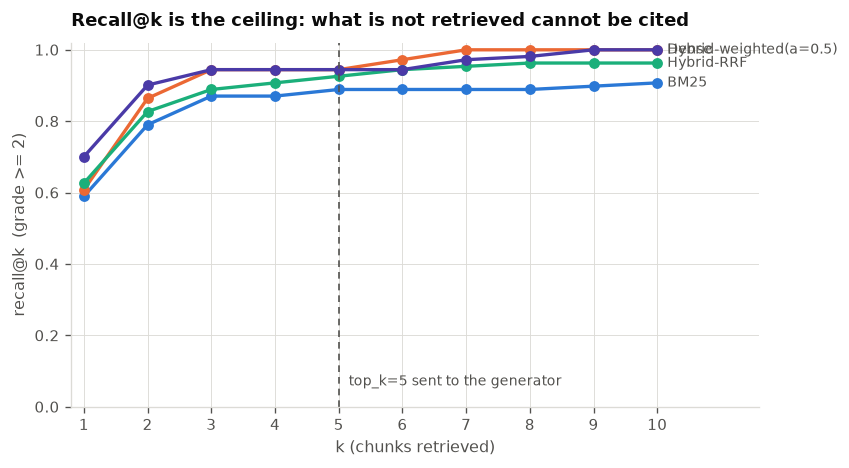

Table view (also the accessible form of the chart above):


,BM25,Dense,Hybrid-RRF,Hybrid-weighted(a=0.5)
k,,,,
1,0.590,0.608,0.627,0.701
2,0.790,0.864,0.827,0.901
3,0.870,0.944,0.889,0.944
4,0.870,0.944,0.907,0.944
5,0.889,0.944,0.926,0.944
6,0.889,0.972,0.944,0.944
7,0.889,1.000,0.954,0.972
8,0.889,1.000,0.963,0.981
9,0.898,1.000,0.963,1.000



Reading it: at k=5 the best retriever (Dense) retrieves 94% of all answer-bearing chunks.
That number is the hard ceiling on answer quality - a perfect generator cannot exceed it.
The curve flattening is the signal that raising top_k only buys prompt tokens, not answers.


In [16]:
# --- 6.2 recall@k curve: the ceiling on everything downstream ------------------------------------
_ks = list(range(1, 11))
_curves = {}
for r in RETRIEVERS:
    df, _ = evaluate_retriever(r, ANSWERABLE, QRELS, ks=_ks, depth=10)
    _curves[r.name] = [df[f"recall@{k}"].mean() for k in _ks]

CURVE_TABLE = pd.DataFrame(_curves, index=pd.Index(_ks, name="k")).round(3)

fig, ax = plt.subplots()
for i, (nm, ys) in enumerate(_curves.items()):
    ax.plot(_ks, ys, marker="o", color=SERIES[i], label=nm)
    ax.annotate(nm, (_ks[-1], ys[-1]), textcoords="offset points", xytext=(6, 0),
                color=INK_SOFT, fontsize=8.5, va="center")   # direct labels, not colour alone
ax.axvline(CFG.top_k, color=INK_SOFT, linewidth=1, linestyle=(0, (4, 3)))
ax.annotate(f"top_k={CFG.top_k} sent to the generator", (CFG.top_k, 0.06), xytext=(6, 0),
            textcoords="offset points", color=INK_SOFT, fontsize=8.5)
ax.set_ylim(0, 1.02)
ax.set_xticks(_ks)
ax.set_xlim(0.8, 11.6)
finish(ax, title="Recall@k is the ceiling: what is not retrieved cannot be cited",
       xlabel="k (chunks retrieved)", ylabel=f"recall@k  (grade >= {REL_THRESHOLD})", legend=False)
plt.tight_layout(); plt.show()

print("Table view (also the accessible form of the chart above):")
display(CURVE_TABLE)
_best = COMPARISON.sort_values("recall@5", ascending=False).iloc[0]
print(f"\nReading it: at k={CFG.top_k} the best retriever ({_best.retriever}) retrieves "
      f"{_best['recall@5']:.0%} of all answer-bearing chunks.")
print("That number is the hard ceiling on answer quality - a perfect generator cannot exceed it.")
print("The curve flattening is the signal that raising top_k only buys prompt tokens, not answers.")

### 6.3 "Did my change make it better?" — the paired bootstrap

Two retrievers scored 0.71 and 0.78 on 26 queries. Is that real?

**Pair the queries.** Both systems ran the *same* queries, so the right unit of analysis is the per-query
*difference*. Pairing removes query difficulty — by far the largest source of variance — from the comparison.
An unpaired comparison of two means on 26 queries has almost no power; the paired version has a usable
amount.

**Then bootstrap the differences.** Resample the 26 per-query deltas with replacement 10 000 times, take the
mean each time, and read the 2.5th and 97.5th percentiles. That interval is the honest answer, and it is
usually wide enough to be uncomfortable — which is the finding, not a flaw in the method.

Three rules this implements:

- **Report the CI, not just the point estimate.** "+0.07 recall@5, 95% CI [−0.02, +0.16]" is a defensible
  sentence. "7% better" is not.
- **Report the win/loss split.** "+0.07 on average" can mean "helped 20 queries a little" or "helped 3
  queries enormously and broke 5". Those call for different decisions.
- **Correct for multiple comparisons when you test many variants.** Sweeping 10 configs and reporting the
  best p-value finds noise. A Bonferroni-style division of alpha is crude but honest; the better habit is a
  held-out set you only touch once (exercise 7 in §10).

In [17]:
# --- 6.3 paired bootstrap + win/loss ------------------------------------------------------------
def paired_bootstrap(a: pd.DataFrame, b: pd.DataFrame, metric: str, n_boot: int = 10_000,
                     seed: int = 0, alpha: float = 0.05) -> dict:
    """Bootstrap CI for mean(b) - mean(a) over paired queries. `a` is the baseline.

    Also returns a two-sided bootstrap p-value: the fraction of resamples whose mean delta falls on the
    other side of zero, doubled. Approximate, but the CI is what you should quote anyway.
    """
    merged = a[["qid", metric]].merge(b[["qid", metric]], on="qid", suffixes=("_a", "_b")).dropna()
    d = (merged[f"{metric}_b"] - merged[f"{metric}_a"]).to_numpy(dtype=float)
    n = len(d)
    if n == 0:
        return {"metric": metric, "n": 0}
    rng = np.random.default_rng(seed)
    means = d[rng.integers(0, n, size=(n_boot, n))].mean(axis=1)
    lo, hi = np.percentile(means, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    p = 2 * min((means <= 0).mean(), (means >= 0).mean())
    sd = d.std(ddof=1) if n > 1 else 0.0
    return {
        "metric": metric, "n": n,
        "baseline": float(merged[f"{metric}_a"].mean()), "variant": float(merged[f"{metric}_b"].mean()),
        "delta": float(d.mean()), "ci_low": float(lo), "ci_high": float(hi),
        "p_boot": float(min(1.0, p)),
        "wins": int((d > 0).sum()), "losses": int((d < 0).sum()), "ties": int((d == 0).sum()),
        "cohens_d": float(d.mean() / sd) if sd > 1e-12 else float("nan"),
        # Queries needed for a +/-0.05 margin at 95% confidence, given the observed spread of deltas.
        "n_for_0.05_margin": int(np.ceil((1.96 * sd / 0.05) ** 2)) if sd > 1e-12 else 0,
    }


def verdict(res: dict, label: str = "") -> str:
    if not res.get("n"):
        return "no paired data"
    sig = "" if (res["ci_low"] <= 0 <= res["ci_high"]) else " **significant**"
    return (f"{label}{res['metric']}: {res['baseline']:.3f} -> {res['variant']:.3f} "
            f"(delta {res['delta']:+.3f}, 95% CI [{res['ci_low']:+.3f}, {res['ci_high']:+.3f}], "
            f"p~{res['p_boot']:.3f}, {res['wins']}W/{res['losses']}L/{res['ties']}T on n={res['n']})" + sig)


# Two separate questions, two separate tests: (a) does hybrid beat the sparse baseline, and
# (b) is the tuned weighted fusion actually better than parameter-free RRF?
_base, _variant = "BM25", "Hybrid-RRF"
print(f"Baseline: {_base}   Variant: {_variant}\n")
_tests = []
for m in ("recall@5", "ndcg@5", f"mrr@{max(CFG.eval_ks)}", "recall@10"):
    res = paired_bootstrap(PER_QUERY[_base], PER_QUERY[_variant], m)
    _tests.append(res)
    print(verdict(res))

SIGNIFICANCE = pd.DataFrame(_tests).round(4)
print()
display(SIGNIFICANCE[["metric", "n", "baseline", "variant", "delta", "ci_low", "ci_high",
                      "p_boot", "wins", "losses", "ties", "cohens_d", "n_for_0.05_margin"]])

# Independent cross-check with a standard non-parametric paired test.
try:
    from scipy.stats import wilcoxon
    _m = "recall@5"
    _p = PER_QUERY[_base][["qid", _m]].merge(PER_QUERY[_variant][["qid", _m]], on="qid",
                                             suffixes=("_a", "_b")).dropna()
    _d = _p[f"{_m}_b"] - _p[f"{_m}_a"]
    if (_d != 0).any():
        print(f"\nWilcoxon signed-rank cross-check on {_m}: p={wilcoxon(_d).pvalue:.4f}")
    else:
        print(f"\nWilcoxon skipped: the two retrievers are tied on every query for {_m}")
except ImportError:
    pass

print("\n--- RRF vs tuned weighted fusion: is the extra parameter earning anything? ---")
for m in ("ndcg@5", "recall@5"):
    print(verdict(paired_bootstrap(PER_QUERY["Hybrid-RRF"], PER_QUERY["Hybrid-weighted(a=0.5)"], m)))
print("If that CI straddles zero, the parameter-free fusion is the better engineering choice: one fewer")
print("thing tuned on 27 queries, and nothing to re-tune when the corpus changes.")

print(f"\nNote the last column: to resolve a +/-0.05 difference in recall@5 on this corpus you would need")
print(f"~{SIGNIFICANCE.iloc[0]['n_for_0.05_margin']:.0f} labelled queries. We have {len(ANSWERABLE)}.")
print("That is the single most useful sentence to say to a client who asks for a 1% improvement claim.")

Baseline: BM25   Variant: Hybrid-RRF

recall@5: 0.889 -> 0.926 (delta +0.037, 95% CI [+0.000, +0.093], p~0.249, 2W/0L/25T on n=27)
ndcg@5: 0.825 -> 0.876 (delta +0.051, 95% CI [+0.005, +0.107], p~0.029, 11W/2L/14T on n=27) **significant**
mrr@10: 0.864 -> 0.917 (delta +0.052, 95% CI [-0.019, +0.133], p~0.215, 4W/1L/22T on n=27)
recall@10: 0.907 -> 0.963 (delta +0.056, 95% CI [+0.000, +0.148], p~0.249, 2W/0L/25T on n=27)



,metric,n,baseline,variant,delta,ci_low,ci_high,p_boot,wins,losses,ties,cohens_d,n_for_0.05_margin
0,recall@5,27,0.8889,0.9259,0.0370,0.0000,0.0926,0.2486,2,0,25,0.2776,28
1,ndcg@5,27,0.8249,0.8763,0.0514,0.0046,0.1071,0.0290,11,2,14,0.3648,31
2,mrr@10,27,0.8642,0.9167,0.0525,-0.0185,0.1327,0.2146,4,1,22,0.2460,70
3,recall@10,27,0.9074,0.9630,0.0556,0.0000,0.1481,0.2486,2,0,25,0.2623,69



Wilcoxon signed-rank cross-check on recall@5: p=0.1573

--- RRF vs tuned weighted fusion: is the extra parameter earning anything? ---
ndcg@5: 0.876 -> 0.932 (delta +0.056, 95% CI [-0.005, +0.134], p~0.081, 6W/3L/18T on n=27)
recall@5: 0.926 -> 0.944 (delta +0.019, 95% CI [-0.037, +0.074], p~0.771, 2W/1L/24T on n=27)
If that CI straddles zero, the parameter-free fusion is the better engineering choice: one fewer
thing tuned on 27 queries, and nothing to re-tune when the corpus changes.

Note the last column: to resolve a +/-0.05 difference in recall@5 on this corpus you would need
~28 labelled queries. We have 27.
That is the single most useful sentence to say to a client who asks for a 1% improvement claim.


In [18]:
# --- 6.4 error analysis: where the best retriever fails ------------------------------------------
BEST_NAME = COMPARISON.sort_values(["recall@5", "ndcg@5"], ascending=False).iloc[0]["retriever"]
BEST = {r.name: r for r in RETRIEVERS}[BEST_NAME]
_df = PER_QUERY[BEST_NAME]
print(f"Best by recall@5: {BEST_NAME}\n")

print("Per-category recall@5 (the aggregate hides this):")
display(by_category(_df, "recall@5").to_frame("recall@5"))

_fails = _df[_df["recall@5"] < 1.0].sort_values("recall@5")
print(f"\n{len(_fails)} of {len(_df)} queries do not retrieve every answer chunk by k=5:")
_rows = []
for _, row in _fails.iterrows():   # iterrows, not itertuples: "recall@5" is not a valid identifier
    rel = {c: g for c, g in QRELS[row["qid"]].items() if g >= REL_THRESHOLD}
    missed = [c for c in rel if c not in row["ranked"][:5]]
    _rows.append({"qid": row["qid"], "category": row["category"],
                  "recall@5": round(row["recall@5"], 2), "n_relevant": row["n_relevant"],
                  "missed": ",".join(missed),
                  "got_instead": ",".join(c for c in row["ranked"][:3] if c not in rel),
                  "question": next(q["question"] for q in GRADED_QUERIES
                                   if q["qid"] == row["qid"])[:50]})
display(pd.DataFrame(_rows))
print("Read the 'missed' vs 'got_instead' columns: multi-fact queries with two answer spans cannot reach")
print("recall@5=1.0 unless BOTH spans rank in the top 5. That is a labelling consequence, not a bug -")
print("and exactly the kind of thing to explain rather than hide behind an average.")

Best by recall@5: Hybrid-weighted(a=0.5)

Per-category recall@5 (the aggregate hides this):


,recall@5
category,
multi-fact,0.833
multi-hop,0.875
paraphrase,0.917
acronym,1.000
factoid,1.000
conditional,1.000



3 of 27 queries do not retrieve every answer chunk by k=5:


,qid,category,recall@5,n_relevant,missed,got_instead,question
0,G15,paraphrase,0.5,2,POL-010::c0,"POL-010::c2,POL-003::c0",My kid is ill and I need to look after them. Is th
1,G23,multi-fact,0.5,2,POL-001::c1,"POL-003::c3,POL-001::c3",When are the on-sites and is attendance optional?
2,G26,multi-hop,0.5,4,"POL-002::c0,POL-002::c1",POL-006::c0,"At a conference, are my dinners paid from the lear"


Read the 'missed' vs 'got_instead' columns: multi-fact queries with two answer spans cannot reach
recall@5=1.0 unless BOTH spans rank in the top 5. That is a labelling consequence, not a bug -
and exactly the kind of thing to explain rather than hide behind an average.


---
# 7. Vector search internals

Everything so far ran an exhaustive scan over 40 chunks, which is correct at that size. This section is
about what you do when it isn't, and — just as important — **how to tell when it still is**.

### The only four axes that matter

Every index is a point in this space. You cannot improve one without paying in another:

1. **Recall** — fraction of the true nearest neighbours actually returned. The approximation error.
2. **Latency** — per query, at the p95, under your real concurrency.
3. **Memory** — bytes per vector, times n. This is usually what decides the architecture.
4. **Build & update cost** — minutes to index, and whether a single insert/delete is cheap.

### The index families

| Family | Idea | Recall knob | Strength | Weakness |
|---|---|---|---|---|
| **Flat** (brute force) | Compare against everything | none — exact | Exact, trivial, instant updates, no training | O(n·d) per query |
| **IVF** | k-means partition; scan only the nearest cells | `nprobe` | Cheap build, tunable, good with filters | Needs training; boundary misses; recall drops hard at low `nprobe` |
| **HNSW** | Multi-layer proximity graph, greedy descent | `efSearch` | Best recall/latency at mid scale; no training | 1.5–2× memory for the graph; deletes are tombstones; slow build |
| **PQ / OPQ** | Split the vector, k-means each subspace, store codes | code size, `nprobe` | 8–64× compression; billions of vectors in RAM | Lossy — recall caps out; **needs a rescoring pass** |
| **Scalar (int8) quantization** | 1 byte per dimension | none | 4× smaller, ~no recall loss | Only 4× |
| **Binary quantization** | 1 bit per dimension, Hamming distance | rescore depth | 32× smaller, extremely fast | Big recall loss without rescoring |
| **Disk-based** (DiskANN) | Graph on SSD, compressed vectors in RAM | beam width | Scale beyond RAM | Latency bound by SSD IOPS |

### The honest headline, measured below

> At 12 000 vectors × 128 dims, **a flat index answers in ~0.04 ms and an ANN index saves you nothing.**

Knowing *where the crossover is* is what makes you useful on this topic — so §7.3 measures flat scan cost as
n grows, and every index below is measured on the same data with the same ground truth, so the numbers are
comparable rather than quoted from a blog post.

Each index is written from scratch in NumPy first (§7.2–7.6) and then mapped onto FAISS (§7.8), because the
parameter names only make sense once you have built the thing they control.

In [19]:
# --- 7.1 distance metrics: three names for one ranking -------------------------------------------
# Clients and candidates mix these up constantly. The relationships are worth being able to derive:
#   cosine(a,b)      = (a.b) / (|a||b|)
#   if |a| = |b| = 1 : cosine = dot product
#   L2^2(a,b)        = |a|^2 + |b|^2 - 2(a.b) = 2 - 2(a.b)  for unit vectors
#     -> ranking by *descending* dot product == ranking by *ascending* L2 on normalised vectors.
_a = RNG.normal(size=(6, 32)).astype(np.float32)
_a_unit = _a / np.linalg.norm(_a, axis=1, keepdims=True)
_q = RNG.normal(size=32).astype(np.float32)
_q_unit = _q / np.linalg.norm(_q)

_cos = (_a @ _q) / (np.linalg.norm(_a, axis=1) * np.linalg.norm(_q))
_dot_unit = _a_unit @ _q_unit
_l2_unit = np.linalg.norm(_a_unit - _q_unit, axis=1)

assert np.allclose(_cos, _dot_unit, atol=1e-5), "cosine == dot product on unit vectors"
assert np.allclose(_l2_unit ** 2, 2 - 2 * _dot_unit, atol=1e-4), "L2^2 == 2 - 2*dot on unit vectors"
assert list(np.argsort(-_dot_unit)) == list(np.argsort(_l2_unit)), "same ranking, opposite direction"
print("verified: on unit-normalised vectors, cosine / inner product / L2 give the SAME ranking")

# And the trap: WITHOUT normalisation, inner product is not cosine - it rewards long vectors.
_dot_raw = _a @ _q
print(f"\nunnormalised: dot ranking {np.argsort(-_dot_raw).tolist()} "
      f"vs cosine ranking {np.argsort(-_cos).tolist()}")
print("-> different. Dot-product search on unnormalised embeddings ranks by length as much as by angle.")
print("   Normalise at ingestion AND at query time, or use a cosine-metric index. This is the single")
print("   most common silent bug in a vector pipeline: nothing errors, results are just quietly worse.")

verified: on unit-normalised vectors, cosine / inner product / L2 give the SAME ranking

unnormalised: dot ranking [2, 5, 4, 1, 3, 0] vs cosine ranking [2, 5, 4, 3, 1, 0]
-> different. Dot-product search on unnormalised embeddings ranks by length as much as by angle.
   Normalise at ingestion AND at query time, or use a cosine-metric index. This is the single
   most common silent bug in a vector pipeline: nothing errors, results are just quietly worse.


### 7.2 A corpus big enough for the question

40 chunks cannot show an index trade-off, so §7.2–7.8 use synthetic vectors with **deliberately realistic
geometry**:

- **Low effective dimensionality** — 128 ambient dims generated from a 10-dimensional latent space. Real
  embeddings behave like this; they do not fill the sphere uniformly. If you benchmark ANN on
  `np.random.normal`, every index looks terrible and the sweeps teach you nothing (uniformly random
  high-dimensional data has no exploitable neighbourhood structure — that *is* the curse of dimensionality).
- **Topical clusters** — 30 of them, like a real document collection.
- **Queries that are near but not identical to corpus points**, which is what a real query embedding is.

Ground truth is computed by brute force, so "recall" here means *recall against exact search*, not against
human labels. Keep the two ideas separate: §4–6 measured whether the *right chunk* is found; this section
measures whether the index finds *what exact search would have found*. An ANN index with 0.9 recall against
exact search caps your retrieval quality at roughly 0.9× whatever §6 measured.

In [20]:
# --- 7.2 synthetic corpus + ground truth ---------------------------------------------------------
def make_corpus(n: int, dim: int, latent_dim: int = 10, n_clusters: int = 30,
                noise: float = 0.05, seed: int = 0) -> np.ndarray:
    """Vectors on a low-dimensional manifold with topical clusters, unit-normalised."""
    rng = np.random.default_rng(seed)
    basis = rng.normal(size=(latent_dim, dim)) / np.sqrt(latent_dim)
    centres = rng.normal(size=(n_clusters, latent_dim))
    assign = rng.integers(0, n_clusters, size=n)
    latent = centres[assign] + 0.6 * rng.normal(size=(n, latent_dim))
    X = latent @ basis + noise * rng.normal(size=(n, dim))
    X /= np.linalg.norm(X, axis=1, keepdims=True)
    return X.astype(np.float32)


def make_queries(X: np.ndarray, n_queries: int, jitter: float = 0.08, seed: int = 1) -> np.ndarray:
    """Queries near, but not equal to, corpus points - like a real query embedding."""
    rng = np.random.default_rng(seed)
    base = X[rng.choice(len(X), size=n_queries, replace=False)]
    Q = base + jitter * rng.normal(size=base.shape)
    Q /= np.linalg.norm(Q, axis=1, keepdims=True)
    return Q.astype(np.float32)


def exact_topk(X: np.ndarray, Q: np.ndarray, k: int) -> np.ndarray:
    """Ground truth by brute force. argpartition is O(n) per query vs O(n log n) for a full sort."""
    sims = Q @ X.T
    idx = np.argpartition(-sims, kth=k - 1, axis=1)[:, :k]
    rows = np.arange(Q.shape[0])[:, None]
    return idx[rows, np.argsort(-sims[rows, idx], axis=1)]


def ann_recall(approx: Sequence[Sequence[int]], truth: np.ndarray) -> float:
    """Recall against exact search: |approx ∩ exact| / k, averaged over queries."""
    return float(np.mean([len(set(a) & set(t)) / len(t) for a, t in zip(approx, truth)]))


X_ANN = make_corpus(CFG.ann_n, CFG.ann_dim, CFG.ann_latent_dim, noise=CFG.ann_noise, seed=CFG.seed)
Q_ANN = make_queries(X_ANN, CFG.ann_queries, seed=CFG.seed + 1)
t0 = time.perf_counter()
TRUTH = exact_topk(X_ANN, Q_ANN, CFG.ann_k)
_gt_ms = (time.perf_counter() - t0) / len(Q_ANN) * 1000

print(f"corpus {X_ANN.shape}  queries {Q_ANN.shape}  k={CFG.ann_k}")
print(f"raw float32 size: {X_ANN.nbytes / 1e6:.1f} MB  ({X_ANN.shape[1] * 4} bytes/vector)")
print(f"ground truth by exact search: {_gt_ms:.3f} ms/query (batched)")

# Sanity: the data must have exploitable structure, or the sweeps below are meaningless.
_sims = Q_ANN[:20] @ X_ANN.T
print(f"\nsimilarity to the true 1st / 10th / 100th neighbour: "
      f"{np.sort(_sims, axis=1)[:, -1].mean():.3f} / {np.sort(_sims, axis=1)[:, -10].mean():.3f} / "
      f"{np.sort(_sims, axis=1)[:, -100].mean():.3f}")
print("A visible gap between the 10th and 100th neighbour is what makes approximate search possible.")
print("On uniformly random high-dimensional vectors that gap vanishes and every ANN index fails.")

corpus (12000, 128)  queries (100, 128)  k=10
raw float32 size: 6.1 MB  (512 bytes/vector)
ground truth by exact search: 0.163 ms/query (batched)

similarity to the true 1st / 10th / 100th neighbour: 0.754 / 0.703 / 0.634
A visible gap between the 10th and 100th neighbour is what makes approximate search possible.
On uniformly random high-dimensional vectors that gap vanishes and every ANN index fails.


In [21]:
# --- 7.3 flat index, and where the crossover actually is -----------------------------------------
class FlatIndex:
    """Exact inner-product search. The baseline every other index is measured against.

    The implementation detail that matters in production: do it as ONE matrix multiply, not a Python loop.
    BLAS gives you multiple cores and cache blocking for free, which is often a 50-100x difference and is
    why a flat index stays viable far longer than people expect.
    """

    name = "Flat (exact)"
    needs_training = False

    def __init__(self, X: np.ndarray):
        t0 = time.perf_counter()
        self.X = np.ascontiguousarray(X, dtype=np.float32)
        self.build_s = time.perf_counter() - t0
        self.bytes_per_vector = X.shape[1] * 4

    def search(self, q: np.ndarray, k: int) -> np.ndarray:
        sims = self.X @ q
        top = np.argpartition(-sims, kth=k - 1)[:k]
        return top[np.argsort(-sims[top])]

    def search_batch(self, Q: np.ndarray, k: int) -> np.ndarray:
        return exact_topk(self.X, Q, k)


def bench_index(index, Q, truth, k, label=None, repeats=1, **search_kwargs) -> dict:
    """One query at a time (the realistic online pattern), p50/p95 reported."""
    index.search(Q[0], k, **search_kwargs)      # warm-up: first call pays page faults and BLAS setup
    lat = []
    results = []
    for _ in range(repeats):
        results = []
        for q in Q:
            t0 = time.perf_counter()
            res = index.search(q, k, **search_kwargs)
            lat.append((time.perf_counter() - t0) * 1000)
            results.append(res)
    return {"index": label or index.name, **{f"param_{a}": b for a, b in search_kwargs.items()},
            "recall": round(ann_recall(results, truth), 4),
            "p50_ms": round(float(np.percentile(lat, 50)), 4),
            "p95_ms": round(float(np.percentile(lat, 95)), 4),
            "build_s": round(getattr(index, "build_s", float("nan")), 3),
            "bytes_per_vec": getattr(index, "bytes_per_vector", float("nan"))}


flat = FlatIndex(X_ANN)
FLAT_RESULT = bench_index(flat, Q_ANN, TRUTH, CFG.ann_k)
print(pd.DataFrame([FLAT_RESULT]).to_string(index=False))

# How flat scan cost grows with n - the measurement that tells you when to bother with ANN.
_rows = []
for n in (1_000, 5_000, 20_000, 100_000, 500_000):
    Xn = make_corpus(n, CFG.ann_dim, CFG.ann_latent_dim, noise=CFG.ann_noise, seed=7)
    qn = make_queries(Xn, 20, seed=8)
    idx = FlatIndex(Xn)
    idx.search(qn[0], CFG.ann_k)                # warm-up, as above
    lat = []
    for q in qn:
        t0 = time.perf_counter(); idx.search(q, CFG.ann_k); lat.append((time.perf_counter() - t0) * 1000)
    _rows.append({"n_vectors": n, "ram_MB": round(Xn.nbytes / 1e6, 1),
                  "flat_p50_ms": round(float(np.percentile(lat, 50)), 3),
                  "flat_p95_ms": round(float(np.percentile(lat, 95)), 3),
                  "qps_1_core": int(1000 / max(np.percentile(lat, 50), 1e-6))})
    del Xn
FLAT_SCALING = pd.DataFrame(_rows)
print()
display(FLAT_SCALING)
print("Latency is linear in n (it is one matmul). Read the table as a budget:")
print("  * a 50 ms retrieval budget and 1 core -> flat search is fine into the low millions;")
print("  * 100x that traffic, or a 5 ms budget, or 20x the dimensions -> now you need an index.")
print("Saying 'we measured it and flat is fine until ~2M vectors' is a better answer than naming an index.")

       index  recall  p50_ms  p95_ms  build_s  bytes_per_vec
Flat (exact)     1.0  0.3544   0.603      0.0            512


,n_vectors,ram_MB,flat_p50_ms,flat_p95_ms,qps_1_core
0,1000,0.5,0.047,0.053,21321
1,5000,2.6,0.201,0.238,4971
2,20000,10.2,0.182,0.219,5508
3,100000,51.2,2.298,2.928,435
4,500000,256.0,11.216,12.477,89


Latency is linear in n (it is one matmul). Read the table as a budget:
  * a 50 ms retrieval budget and 1 core -> flat search is fine into the low millions;
  * 100x that traffic, or a 5 ms budget, or 20x the dimensions -> now you need an index.
Saying 'we measured it and flat is fine until ~2M vectors' is a better answer than naming an index.


### 7.4 IVF — invert the problem with k-means

**Build:** cluster the corpus into `nlist` cells with k-means; store each vector's id in its cell's list.
**Search:** score the query against the `nlist` centroids, pick the `nprobe` nearest cells, scan only those.

So you scan roughly `n · nprobe / nlist` vectors instead of `n`. Two parameters, and the standard starting
points are worth memorising because interviewers ask:

- **`nlist ≈ √n`** (here √12000 ≈ 110; FAISS guidance is 4·√n to 16·√n for large n). Too few cells → each
  scan is huge. Too many → centroid scoring itself dominates and cells get too small to train well.
- **`nprobe`**: start at 1–5% of `nlist`, then *tune it against a recall target*, which is exactly the sweep
  below. This is the knob you expose in production — it is a per-query dial on the recall/latency trade-off,
  which is unusual and valuable: a "fast path" and an "accurate path" can share one index.

**The characteristic failure** is the cell-boundary miss: a true neighbour sitting just across a Voronoi
boundary in an unprobed cell is invisible, no matter how similar it is. That is why IVF recall at
`nprobe=1` is mediocre on clustered data and why you never ship `nprobe=1`.

**Training matters.** The k-means needs enough points per centroid (FAISS warns below ~39×`nlist`). An IVF
index trained on an unrepresentative sample — the first 10 000 documents of a corpus sorted by date, say —
has badly placed cells and silently loses recall forever.

In [22]:
# --- 7.4 IVF from scratch ------------------------------------------------------------------------
def kmeans(X: np.ndarray, k: int, iters: int = 12, seed: int = 0) -> tuple[np.ndarray, np.ndarray]:
    """Lloyd's algorithm with k-means++ style spread init. Enough to show the mechanics."""
    rng = np.random.default_rng(seed)
    centroids = X[rng.choice(len(X), size=k, replace=False)].copy()
    assign = np.zeros(len(X), dtype=np.int32)
    for _ in range(iters):
        # ||x - c||^2 = ||x||^2 - 2 x.c + ||c||^2 ; the ||x||^2 term is constant per row for argmin
        d = -2 * X @ centroids.T + (centroids ** 2).sum(1)[None, :]
        assign = np.argmin(d, axis=1).astype(np.int32)
        for j in range(k):
            members = assign == j
            if members.any():
                centroids[j] = X[members].mean(0)
            else:                      # empty cell: re-seed it on a random point rather than leave it dead
                centroids[j] = X[rng.integers(len(X))]
    return centroids, assign


class IVFIndex:
    """Inverted file index. `nprobe` is the recall/latency dial, settable per query."""

    needs_training = True

    def __init__(self, X: np.ndarray, nlist: int | None = None, iters: int = 10, seed: int = 0):
        n, d = X.shape
        self.nlist = nlist or max(4, int(round(math.sqrt(n))))
        self.name = f"IVF (nlist={self.nlist})"
        t0 = time.perf_counter()
        self.X = X
        centroids, assign = kmeans(X, self.nlist, iters=iters, seed=seed)
        # Normalising the centroids keeps the coarse scoring an inner product like the fine scoring.
        self.centroids = centroids / (np.linalg.norm(centroids, axis=1, keepdims=True) + 1e-12)
        self.lists = [np.where(assign == j)[0] for j in range(self.nlist)]
        self.build_s = time.perf_counter() - t0
        self.bytes_per_vector = d * 4 + 8        # vector + its id in a posting list
        self.list_sizes = np.array([len(l) for l in self.lists])

    def search(self, q: np.ndarray, k: int, nprobe: int = 8) -> np.ndarray:
        nprobe = min(nprobe, self.nlist)
        cent_sims = self.centroids @ q
        probe = np.argpartition(-cent_sims, kth=nprobe - 1)[:nprobe] if nprobe < self.nlist \
            else np.arange(self.nlist)
        cand = np.concatenate([self.lists[p] for p in probe]) if len(probe) else np.empty(0, int)
        if cand.size == 0:
            return np.empty(0, dtype=int)
        sims = self.X[cand] @ q
        kk = min(k, cand.size)
        top = np.argpartition(-sims, kth=kk - 1)[:kk]
        return cand[top[np.argsort(-sims[top])]]


ivf = IVFIndex(X_ANN, seed=CFG.seed)
print(f"{ivf.name}: build {ivf.build_s:.2f}s | cell sizes "
      f"min {ivf.list_sizes.min()} median {int(np.median(ivf.list_sizes))} max {ivf.list_sizes.max()}")
print(f"(k-means cells are uneven - the max cell is {ivf.list_sizes.max() / np.median(ivf.list_sizes):.1f}x "
      f"the median, so p95 latency is worse than p50 by construction)\n")

IVF_SWEEP = pd.DataFrame([bench_index(ivf, Q_ANN, TRUTH, CFG.ann_k, nprobe=p)
                          for p in (1, 2, 4, 8, 16, 32, ivf.nlist)])
IVF_SWEEP["scanned_%"] = (IVF_SWEEP.param_nprobe / ivf.nlist * 100).round(1)
display(IVF_SWEEP[["index", "param_nprobe", "scanned_%", "recall", "p50_ms", "p95_ms"]])
_target = IVF_SWEEP[IVF_SWEEP.recall >= 0.95].head(1)
if not _target.empty:
    print(f"To hit 95% recall: nprobe={int(_target.iloc[0].param_nprobe)} "
          f"(~{_target.iloc[0]['scanned_%']}% of the corpus scanned, "
          f"{_target.iloc[0].p50_ms:.3f} ms/query).")
print("nprobe=nlist is an exhaustive scan through an IVF index: recall 1.0, and SLOWER than flat")
print("because of the extra centroid pass and the gather. An ANN index is never free.")

IVF (nlist=110): build 0.12s | cell sizes min 41 median 102 max 381
(k-means cells are uneven - the max cell is 3.7x the median, so p95 latency is worse than p50 by construction)



,index,param_nprobe,scanned_%,recall,p50_ms,p95_ms
0,IVF (nlist=110),1,0.9,0.661,0.0675,0.0927
1,IVF (nlist=110),2,1.8,0.868,0.0393,0.1178
2,IVF (nlist=110),4,3.6,0.975,0.0420,0.0551
3,IVF (nlist=110),8,7.3,0.992,0.0603,0.0939
4,IVF (nlist=110),16,14.5,0.997,0.0883,0.1094
5,IVF (nlist=110),32,29.1,1.000,0.2115,0.4974
6,IVF (nlist=110),110,100.0,1.000,1.2617,1.8346


To hit 95% recall: nprobe=4 (~3.6% of the corpus scanned, 0.042 ms/query).
nprobe=nlist is an exhaustive scan through an IVF index: recall 1.0, and SLOWER than flat
because of the extra centroid pass and the gather. An ANN index is never free.


### 7.5 HNSW — a navigable small-world graph

The structure that most vector databases (Qdrant, Weaviate, Milvus, pgvector's `hnsw`, Elasticsearch,
Lucene) use by default.

**The idea.** Build a proximity graph where each node links to its ~`M` nearest neighbours, stacked in
layers: the top layer is sparse and long-range, layer 0 holds every node. Search enters at the top, greedily
walks toward the query, drops a layer, repeats. The upper layers are an express network — a few hops cross
the whole space — and layer 0 does the local refinement. It is a skip list in metric space.

**Parameters, and what each one actually buys:**

| Parameter | Controls | Raise it to | Cost |
|---|---|---|---|
| `M` | links per node (layer 0 gets `2M`) | improve the recall *ceiling* | memory: `M·2·4` bytes/vector, and build time |
| `efConstruction` | candidate pool while inserting | build a better graph (permanent effect) | build time only — **free at query time** |
| `efSearch` | candidate pool while searching | trade latency for recall, per query | latency |

`efSearch` is the production dial; `M` and `efConstruction` are decided at build time and changing them
means a rebuild. If recall plateaus below target as you raise `efSearch`, the *graph* is the limit — raise
`M`, not `efSearch`.

**Neighbour selection is the subtle part, and it is implemented both ways below.** Keeping a node's `M`
*closest* candidates seems obvious, but it creates clusters of mutually-close nodes with no links out —
the graph loses navigability and greedy search gets stuck in local minima. The paper's heuristic keeps a
candidate only if it is closer to the new node than to any already-kept neighbour, which preserves
long-range "bridge" edges. The sweep measures the difference.

**Weaknesses to name in an interview:** deletes are tombstones (a removed node stays in the graph as an
unreturnable hop until you rebuild — this is why "GDPR delete" on a vector store is a real engineering
topic); build is slow and hard to parallelise; memory is 1.5–2× the raw vectors; and the graph is a poor
fit for heavily *filtered* search, because a filter that excludes 99% of nodes disconnects the graph you
are walking (see §7.9).

In [23]:
# --- 7.5 HNSW from scratch -----------------------------------------------------------------------
class HNSWIndex:
    """Hierarchical Navigable Small World graph, inner-product variant.

    Readable rather than fast: ~10-20 s to build 12k nodes in pure Python, where FAISS takes ~0.1 s (§7.8).
    The structure is the same; only the constant factor differs.
    """

    needs_training = False

    def __init__(self, X: np.ndarray, M: int = 12, ef_construction: int = 60,
                 selection: str = "heuristic", seed: int = 0):
        self.X = X
        self.M = M
        self.M0 = 2 * M                       # layer 0 gets twice the connectivity
        self.efc = ef_construction
        self.selection = selection
        self.ml = 1.0 / math.log(max(M, 2))   # level-assignment decay from the paper
        self.name = f"HNSW (M={M}, efC={ef_construction}, {selection})"
        rng = np.random.default_rng(seed)
        n = len(X)
        t0 = time.perf_counter()
        # Geometric level distribution: most nodes live only on layer 0.
        self.levels = np.floor(-np.log(rng.random(n) + 1e-12) * self.ml).astype(int)
        self.graph: list[dict[int, list[int]]] = [dict() for _ in range(n)]
        order = np.argsort(-self.levels)      # tallest nodes first -> the express layers exist early
        self.entry = int(order[0])
        self.max_level = int(self.levels[self.entry])
        for pos, node in enumerate(order):
            if pos:
                self._insert(int(node))
        self.build_s = time.perf_counter() - t0
        self.bytes_per_vector = X.shape[1] * 4 + (self.M0 + self.M * max(1, self.max_level)) * 4
        self.n_edges = sum(len(v) for g in self.graph for v in g.values())

    # -- core graph search -------------------------------------------------------------------
    def _search_layer(self, q: np.ndarray, entries: Sequence[int], ef: int, level: int):
        """Best-first search of one layer. Returns up to `ef` candidates, best first."""
        visited = set(entries)
        cand = [(-float(self.X[e] @ q), e) for e in entries]      # max-heap on similarity
        heapq.heapify(cand)
        best = [(float(self.X[e] @ q), e) for e in entries]       # min-heap -> worst of the kept set on top
        heapq.heapify(best)
        while cand:
            neg_sim, node = heapq.heappop(cand)
            # Stop when the best remaining candidate is worse than the worst kept result.
            if len(best) >= ef and -neg_sim < best[0][0]:
                break
            for nb in self.graph[node].get(level, ()):
                if nb in visited:
                    continue
                visited.add(nb)
                s = float(self.X[nb] @ q)
                if len(best) < ef or s > best[0][0]:
                    heapq.heappush(cand, (-s, nb))
                    heapq.heappush(best, (s, nb))
                    if len(best) > ef:
                        heapq.heappop(best)
        return sorted(best, key=lambda t: -t[0])

    def _select_neighbours(self, candidates, m: int) -> list[int]:
        """`simple` = the m closest. `heuristic` = the paper's diversity rule (keeps bridge edges)."""
        if self.selection == "simple" or len(candidates) <= m:
            return [n for _, n in candidates[:m]]
        kept: list[int] = []
        for sim_to_q, c in candidates:                     # candidates are sorted best-first
            if len(kept) >= m:
                break
            # Keep c only if it is closer to the query node than to anything already kept.
            if all(float(self.X[c] @ self.X[k]) < sim_to_q for k in kept):
                kept.append(c)
        for _, c in candidates:                            # top up if the rule was very selective
            if len(kept) >= m:
                break
            if c not in kept:
                kept.append(c)
        return kept

    def _insert(self, node: int) -> None:
        q = self.X[node]
        level = int(self.levels[node])
        entry = [self.entry]
        for l in range(self.max_level, level, -1):         # zoom in: greedy, ef=1
            res = self._search_layer(q, entry, 1, l)
            entry = [res[0][1]] if res else entry
        for l in range(min(level, self.max_level), -1, -1):
            res = self._search_layer(q, entry, self.efc, l)
            m = self.M0 if l == 0 else self.M
            neighbours = self._select_neighbours(res, m)
            self.graph[node][l] = list(neighbours)
            for nb in neighbours:                           # links are bidirectional
                lst = self.graph[nb].setdefault(l, [])
                if node not in lst:
                    lst.append(node)
                    cap = self.M0 if l == 0 else self.M
                    if len(lst) > cap:                      # prune the over-full neighbour
                        sims = self.X[lst] @ self.X[nb]
                        order = np.argsort(-sims)[:cap]
                        self.graph[nb][l] = [lst[i] for i in order]
            entry = [n for _, n in res] or entry
        if level > self.max_level:
            self.max_level = level
            self.entry = node

    def search(self, q: np.ndarray, k: int, ef_search: int = 50) -> np.ndarray:
        entry = [self.entry]
        for l in range(self.max_level, 0, -1):
            res = self._search_layer(q, entry, 1, l)
            entry = [res[0][1]] if res else entry
        res = self._search_layer(q, entry, max(ef_search, k), 0)
        return np.array([n for _, n in res[:k]], dtype=int)


_hnsw_rows = []
HNSW_INDEXES = {}
for _sel in ("simple", "heuristic"):
    h = HNSWIndex(X_ANN, M=12, ef_construction=60, selection=_sel, seed=CFG.seed)
    HNSW_INDEXES[_sel] = h
    print(f"{h.name}: build {h.build_s:.1f}s | levels 0..{h.max_level} | {h.n_edges:,} directed edges "
          f"| {h.bytes_per_vector} bytes/vector")
    for ef in (10, 20, 50, 100, 200):
        _hnsw_rows.append({**bench_index(h, Q_ANN, TRUTH, CFG.ann_k, label=f"HNSW-{_sel}", ef_search=ef),
                           "selection": _sel})

HNSW_SWEEP = pd.DataFrame(_hnsw_rows)
print()
display(HNSW_SWEEP.pivot(index="param_ef_search", columns="selection",
                         values=["recall", "p50_ms"]).round(4))
_s = HNSW_SWEEP[HNSW_SWEEP.selection == "simple"].recall.max()
_h = HNSW_SWEEP[HNSW_SWEEP.selection == "heuristic"].recall.max()
print(f"Best recall: simple selection {_s:.3f} vs heuristic {_h:.3f} on an identical corpus and M.")
print("The heuristic costs build time and buys recall - it keeps long-range bridge edges that the")
print("'just take the M closest' rule throws away, so greedy search gets stuck in fewer local minima.")

HNSW (M=12, efC=60, simple): build 10.1s | levels 0..4 | 300,978 directed edges | 800 bytes/vector


HNSW (M=12, efC=60, heuristic): build 13.0s | levels 0..4 | 300,978 directed edges | 800 bytes/vector


recall           p50_ms        
selection       heuristic simple heuristic  simple
param_ef_search                                   
10                  0.936  0.924    0.2193  0.2105
20                  0.972  0.956    0.3371  0.2721
50                  0.990  0.989    0.5959  0.4437
100                 0.991  0.990    0.6608  0.7277
200                 0.991  0.990    1.1023  1.3506

Best recall: simple selection 0.990 vs heuristic 0.991 on an identical corpus and M.
The heuristic costs build time and buys recall - it keeps long-range bridge edges that the
'just take the M closest' rule throws away, so greedy search gets stuck in fewer local minima.


### 7.6 Quantization — when memory is the binding constraint

Recall and latency get the attention; **memory decides the architecture**. At 1536 dimensions, float32:

```
1M vectors   ×  1536 dims  ×  4 bytes  =  6.1 GB   (+ HNSW graph ≈ 1.5-2×)
100M vectors ×  1536 dims  ×  4 bytes  =  614 GB   -> not a RAM problem any more, an architecture problem
```

Three compression schemes, in increasing aggressiveness:

| Scheme | Bytes/vector (1536-d) | Typical recall cost | Mechanism |
|---|---|---|---|
| float32 | 6144 | — | baseline |
| **int8 scalar** | 1536 (4×) | ~0–1% | per-dimension min/max → 8-bit bucket |
| **Product quantization** `m=96, 8 bits` | 96 (64×) | 10–40% **before rescoring** | split into `m` sub-vectors, k-means each, store the centroid id |
| **binary (1 bit/dim)** | 192 (32×) | large before rescoring | sign of each dimension; Hamming distance via popcount |

**The non-negotiable pattern: quantize to shortlist, rescore to rank.** Use the compressed codes to pull a
shortlist 5–20× longer than `k`, then re-score those few candidates with the full-precision vectors (kept on
disk/SSD or in a cheaper tier) and return the top `k`. The shortlist step is cheap and the rescoring step
touches so few vectors that the full-precision cost is irrelevant. The cell below shows raw PQ recall and
the same index with rescoring; in FAISS this is `IndexRefineFlat`, in Qdrant it is "rescore", in
`pgvector` you build it yourself.

Also worth knowing: **PQ's error depends on how the dimensions are split.** Correlated dimensions landing in
the same sub-vector waste code space. OPQ learns a rotation first to decorrelate; FAISS writes it
`OPQ96,IVF4096,PQ96`.

In [24]:
# --- 7.6 int8, binary and product quantization ---------------------------------------------------
class ScalarQuantizedIndex:
    """int8 per dimension, asymmetric: codes are quantized, the query stays float32."""

    name = "int8 scalar quantization"
    needs_training = False

    def __init__(self, X: np.ndarray):
        t0 = time.perf_counter()
        self.lo = X.min(axis=0)
        self.hi = X.max(axis=0)
        self.scale = (self.hi - self.lo) / 255.0
        self.scale[self.scale == 0] = 1e-9
        self.codes = np.round((X - self.lo) / self.scale).astype(np.uint8)
        self.X = X                              # kept only for optional rescoring
        self.build_s = time.perf_counter() - t0
        self.bytes_per_vector = X.shape[1]

    def search(self, q: np.ndarray, k: int) -> np.ndarray:
        # Decode on the fly: dot(x, q) ~ sum((lo + code*scale) * q) = lo.q + code.(scale*q)
        approx = self.codes @ (self.scale * q) + float(self.lo @ q)
        top = np.argpartition(-approx, kth=k - 1)[:k]
        return top[np.argsort(-approx[top])]


class BinaryQuantizedIndex:
    """1 bit per dimension (the sign), Hamming distance, optional exact rescoring."""

    name = "binary (1 bit/dim)"
    needs_training = False

    def __init__(self, X: np.ndarray):
        t0 = time.perf_counter()
        self.bits = np.packbits(X > 0, axis=1)
        self.X = X
        self.build_s = time.perf_counter() - t0
        self.bytes_per_vector = self.bits.shape[1]
        self._popcount = np.unpackbits(np.arange(256, dtype=np.uint8)[:, None], axis=1).sum(1)

    def search(self, q: np.ndarray, k: int, rescore: int = 0) -> np.ndarray:
        qb = np.packbits(q > 0)
        dist = self._popcount[np.bitwise_xor(self.bits, qb)].sum(axis=1)   # Hamming
        depth = max(k, rescore) if rescore else k
        cand = np.argpartition(dist, kth=min(depth, len(dist) - 1))[:depth]
        if rescore:                                  # exact re-ranking of the shortlist
            sims = self.X[cand] @ q
            return cand[np.argsort(-sims)[:k]]
        return cand[np.argsort(dist[cand])][:k]


class PQIndex:
    """Product quantization: split into m sub-vectors, k-means each, store one byte per sub-vector."""

    needs_training = True

    def __init__(self, X: np.ndarray, m: int = 16, nbits: int = 8, iters: int = 8, seed: int = 0):
        n, d = X.shape
        assert d % m == 0, "m must divide the dimension (pad or project otherwise)"
        self.m, self.ksub, self.dsub = m, 2 ** nbits, d // m
        self.name = f"PQ (m={m}, {nbits} bits)"
        t0 = time.perf_counter()
        self.X = X
        self.codebooks = np.zeros((m, self.ksub, self.dsub), dtype=np.float32)
        self.codes = np.zeros((n, m), dtype=np.uint8)
        for j in range(m):
            sub = X[:, j * self.dsub:(j + 1) * self.dsub]
            centroids, assign = kmeans(sub, self.ksub, iters=iters, seed=seed + j)
            self.codebooks[j] = centroids
            self.codes[:, j] = assign.astype(np.uint8)
        self.build_s = time.perf_counter() - t0
        self.bytes_per_vector = m * nbits / 8
        self.codebook_bytes = self.codebooks.nbytes

    def search(self, q: np.ndarray, k: int, rescore: int = 0) -> np.ndarray:
        """Asymmetric distance computation: one lookup table, then a sum of m table reads per vector."""
        lut = np.empty((self.m, self.ksub), dtype=np.float32)
        for j in range(self.m):
            lut[j] = self.codebooks[j] @ q[j * self.dsub:(j + 1) * self.dsub]
        approx = lut[np.arange(self.m)[None, :], self.codes].sum(axis=1)
        depth = max(k, rescore) if rescore else k
        cand = np.argpartition(-approx, kth=min(depth, len(approx) - 1))[:depth]
        if rescore:
            sims = self.X[cand] @ q
            return cand[np.argsort(-sims)[:k]]
        return cand[np.argsort(-approx[cand])][:k]


sq = ScalarQuantizedIndex(X_ANN)
bq = BinaryQuantizedIndex(X_ANN)
pq = PQIndex(X_ANN, m=16, nbits=8, seed=CFG.seed)

_rows = [FLAT_RESULT,
         bench_index(sq, Q_ANN, TRUTH, CFG.ann_k),
         bench_index(bq, Q_ANN, TRUTH, CFG.ann_k, label="binary, no rescore"),
         bench_index(bq, Q_ANN, TRUTH, CFG.ann_k, label="binary + rescore 10x", rescore=10 * CFG.ann_k),
         bench_index(bq, Q_ANN, TRUTH, CFG.ann_k, label="binary + rescore 50x", rescore=50 * CFG.ann_k),
         bench_index(pq, Q_ANN, TRUTH, CFG.ann_k, label="PQ, no rescore"),
         bench_index(pq, Q_ANN, TRUTH, CFG.ann_k, label="PQ + rescore 10x", rescore=10 * CFG.ann_k),
         bench_index(pq, Q_ANN, TRUTH, CFG.ann_k, label="PQ + rescore 50x", rescore=50 * CFG.ann_k)]
QUANT_TABLE = pd.DataFrame(_rows)
QUANT_TABLE["compression"] = (CFG.ann_dim * 4 / QUANT_TABLE.bytes_per_vec).round(1)
QUANT_TABLE["RAM_for_100M_GB"] = (QUANT_TABLE.bytes_per_vec * 1e8 / 1e9).round(1)
_qt = QUANT_TABLE[["index", "param_rescore", "recall", "p50_ms", "bytes_per_vec",
                   "compression", "RAM_for_100M_GB"]].copy()
_qt["param_rescore"] = _qt.param_rescore.astype("object").where(_qt.param_rescore.notna(), "-")
display(_qt)
print(f"PQ codebooks cost a further {pq.codebook_bytes / 1e3:.0f} KB total - a fixed cost, not per vector.")
print("\nThe pattern to remember: compression alone loses recall; compression + a short exact rescoring")
print("pass recovers nearly all of it for almost no latency, because it touches only ~10-50x k vectors.")
print("Shipping a quantized index WITHOUT rescoring is the most common way to silently degrade a RAG system.")

,index,param_rescore,recall,p50_ms,bytes_per_vec,compression,RAM_for_100M_GB
0,Flat (exact),-,1.000,0.3544,512.0,1.0,51.2
1,int8 scalar quantization,-,0.986,1.5176,128.0,4.0,12.8
2,"binary, no rescore",-,0.273,0.7018,16.0,32.0,1.6
3,binary + rescore 10x,100.0,0.828,0.7242,16.0,32.0,1.6
4,binary + rescore 50x,500.0,0.997,0.7740,16.0,32.0,1.6
5,"PQ, no rescore",-,0.436,1.2436,16.0,32.0,1.6
6,PQ + rescore 10x,100.0,0.968,1.6306,16.0,32.0,1.6
7,PQ + rescore 50x,500.0,1.000,0.8492,16.0,32.0,1.6


PQ codebooks cost a further 131 KB total - a fixed cost, not per vector.

The pattern to remember: compression alone loses recall; compression + a short exact rescoring
pass recovers nearly all of it for almost no latency, because it touches only ~10-50x k vectors.
Shipping a quantized index WITHOUT rescoring is the most common way to silently degrade a RAG system.


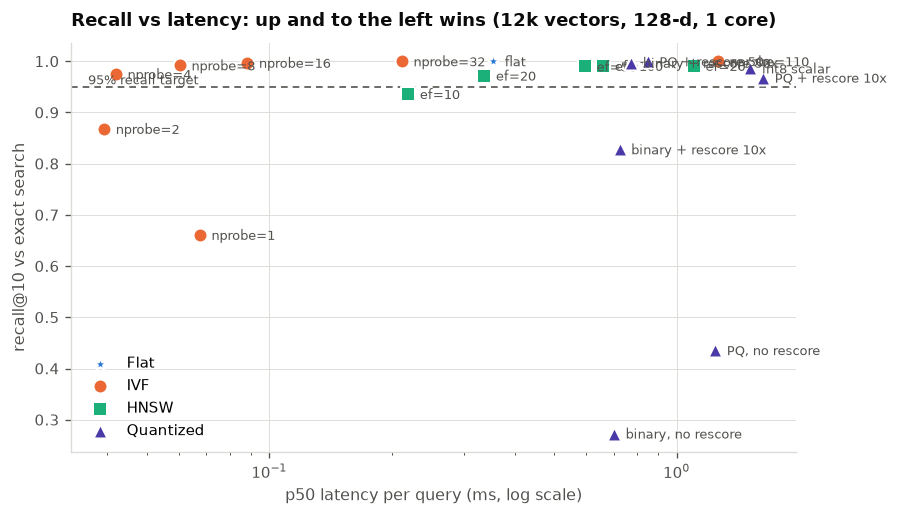

,family,label,recall,p50_ms
0,Flat,flat,1.000,0.3544
8,HNSW,ef=10,0.936,0.2193
9,HNSW,ef=20,0.972,0.3371
10,HNSW,ef=50,0.990,0.5959
11,HNSW,ef=100,0.991,0.6608
12,HNSW,ef=200,0.991,1.1023
1,IVF,nprobe=1,0.661,0.0675
2,IVF,nprobe=2,0.868,0.0393
3,IVF,nprobe=4,0.975,0.0420
4,IVF,nprobe=8,0.992,0.0603


At THIS scale the exact index is on the frontier - which is the honest finding, and the one a
client most needs to hear before paying for a vector database. Re-run with CFG.ann_n = 200_000
to watch flat fall off the frontier and HNSW take over (exercise 5).


In [25]:
# --- 7.7 the whole trade-off on one chart --------------------------------------------------------
_points = []
for r in [FLAT_RESULT]:
    _points.append({"family": "Flat", "label": "flat", "recall": r["recall"], "p50_ms": r["p50_ms"]})
for _, r in IVF_SWEEP.iterrows():
    _points.append({"family": "IVF", "label": f"nprobe={int(r.param_nprobe)}",
                    "recall": r.recall, "p50_ms": r.p50_ms})
for _, r in HNSW_SWEEP[HNSW_SWEEP.selection == "heuristic"].iterrows():
    _points.append({"family": "HNSW", "label": f"ef={int(r.param_ef_search)}",
                    "recall": r.recall, "p50_ms": r.p50_ms})
for _, r in QUANT_TABLE.iloc[1:].iterrows():   # row 0 is the flat baseline, already plotted
    _points.append({"family": "Quantized", "label": r["index"].replace(" quantization", ""),
                    "recall": r.recall, "p50_ms": r.p50_ms})
TRADEOFF = pd.DataFrame(_points)

fig, ax = plt.subplots(figsize=(7.6, 4.4))
# Four series on a scatter -> the first four palette slots, which are validated for all-pairs separation,
# plus a distinct marker per family so identity never rests on colour alone.
_markers = {"Flat": "*", "IVF": "o", "HNSW": "s", "Quantized": "^"}
for i, (fam, grp) in enumerate(TRADEOFF.groupby("family", sort=False)):
    ax.scatter(grp.p50_ms, grp.recall, s=70, color=SERIES[i], marker=_markers[fam],
               label=fam, edgecolors="white", linewidths=1.2, zorder=3)
    for _, row in grp.iterrows():
        ax.annotate(row.label, (row.p50_ms, row.recall), textcoords="offset points",
                    xytext=(7, -3), fontsize=7.5, color=INK_SOFT)
ax.set_xscale("log")
ax.axhline(0.95, color=INK_SOFT, linewidth=1, linestyle=(0, (4, 3)))
ax.annotate("95% recall target", (ax.get_xlim()[0] * 1.1, 0.955), fontsize=8, color=INK_SOFT)
finish(ax, title="Recall vs latency: up and to the left wins (12k vectors, 128-d, 1 core)",
       xlabel="p50 latency per query (ms, log scale)", ylabel=f"recall@{CFG.ann_k} vs exact search")
plt.tight_layout(); plt.show()

display(TRADEOFF.sort_values(["family", "recall"]).round(4))
print("At THIS scale the exact index is on the frontier - which is the honest finding, and the one a")
print("client most needs to hear before paying for a vector database. Re-run with CFG.ann_n = 200_000")
print("to watch flat fall off the frontier and HNSW take over (exercise 5).")

### 7.8 The same indexes in FAISS

Having built them, the FAISS API stops being a list of magic strings. Two things this section gives you:
a **parameter mapping** you can recite, and a **measured comparison** against the from-scratch versions —
same data, same ground truth, so the gap is pure implementation quality (SIMD, cache blocking, 20 threads,
and in HNSW's case a better pruning implementation than mine).

| Concept | §7.2–7.6 (ours) | FAISS | `index_factory` string |
|---|---|---|---|
| exact | `FlatIndex` | `IndexFlatIP` / `IndexFlatL2` | `"Flat"` |
| IVF cells | `IVFIndex(nlist=…)` | `IndexIVFFlat(quantizer, d, nlist, metric)` | `"IVF110,Flat"` |
| IVF probe depth | `search(..., nprobe=…)` | `index.nprobe = …` | — |
| HNSW links | `HNSWIndex(M=…)` | `IndexHNSWFlat(d, M, metric)` | `"HNSW12"` |
| HNSW build depth | `ef_construction=…` | `index.hnsw.efConstruction = …` | — |
| HNSW search depth | `search(..., ef_search=…)` | `index.hnsw.efSearch = …` | — |
| product quantization | `PQIndex(m=…, nbits=8)` | `IndexIVFPQ(q, d, nlist, m, nbits)` | `"IVF110,PQ16x8"` |
| int8 | `ScalarQuantizedIndex` | `IndexScalarQuantizer(d, QT_8bit, metric)` | `"SQ8"` |
| quantize + rescore | `search(..., rescore=N)` | `IndexRefineFlat(base); refine.k_factor = N/k` | `"IVF110,PQ16x8,RFlat"` |
| ids & deletes | (not implemented) | `IndexIDMap2` + `remove_ids(IDSelectorBatch)` | `"IDMap2,…"` |

Two gotchas that cost people days:

- **`train()` before `add()`** for any index with a learned structure (IVF, PQ). `is_trained` tells you.
  Train on a representative sample ≥ 39×`nlist` points, or FAISS warns and your cells are badly placed.
- **Cosine similarity is not a FAISS metric.** Normalise the vectors (`faiss.normalize_L2`) and use
  `METRIC_INNER_PRODUCT`. Mixing a normalised index with unnormalised queries is the silent-bug version
  of §7.1.

In [26]:
# --- 7.8 FAISS equivalents, measured on the same data --------------------------------------------
try:
    import faiss
    _HAVE_FAISS = True
except ImportError:
    _HAVE_FAISS = False
    print("faiss not installed -> skipping. `pip install faiss-cpu`")

if _HAVE_FAISS:
    import os as _os
    import tempfile as _tempfile

    def faiss_bytes(index) -> int:
        """Serialised size: the honest measure of what an index costs to hold or ship."""
        path = _os.path.join(_tempfile.gettempdir(), "_ragging_lab_idx.faiss")
        faiss.write_index(index, path)
        n = _os.path.getsize(path)
        _os.unlink(path)
        return n

    def faiss_bench(label, index, sweep=None, setter=None, k=None, add=True) -> list[dict]:
        k = k or CFG.ann_k
        t0 = time.perf_counter()
        if not index.is_trained:
            index.train(X_ANN)            # IVF/PQ learn their structure first
        if add:
            index.add(X_ANN)
        build_s = time.perf_counter() - t0
        size = faiss_bytes(index)
        out = []
        for v in (sweep or [None]):
            if setter and v is not None:
                setter(index, v)
            lat = []
            res = []
            for q in Q_ANN:               # one at a time, like an online service
                t0 = time.perf_counter()
                _, I = index.search(q.reshape(1, -1), k)
                lat.append((time.perf_counter() - t0) * 1000)
                res.append(I[0])
            out.append({"index": label, "param": v, "recall": round(ann_recall(res, TRUTH), 4),
                        "p50_ms": round(float(np.percentile(lat, 50)), 4),
                        "p95_ms": round(float(np.percentile(lat, 95)), 4),
                        "build_s": round(build_s, 3), "size_MB": round(size / 1e6, 2)})
        return out

    _nlist = ivf.nlist
    _rows = []
    _rows += faiss_bench("FlatIP", faiss.IndexFlatIP(CFG.ann_dim))
    _rows += faiss_bench("IVFFlat", faiss.IndexIVFFlat(faiss.IndexFlatIP(CFG.ann_dim), CFG.ann_dim,
                                                       _nlist, faiss.METRIC_INNER_PRODUCT),
                         sweep=[1, 4, 8, 16, 32], setter=lambda ix, v: setattr(ix, "nprobe", v))
    _h = faiss.IndexHNSWFlat(CFG.ann_dim, 12, faiss.METRIC_INNER_PRODUCT)
    _h.hnsw.efConstruction = 60
    _rows += faiss_bench("HNSWFlat", _h, sweep=[10, 20, 50, 100],
                         setter=lambda ix, v: setattr(ix.hnsw, "efSearch", v))
    _rows += faiss_bench("SQ8", faiss.IndexScalarQuantizer(CFG.ann_dim, faiss.ScalarQuantizer.QT_8bit,
                                                           faiss.METRIC_INNER_PRODUCT))
    _rows += faiss_bench("IVFPQ (no rescore)",
                         faiss.IndexIVFPQ(faiss.IndexFlatIP(CFG.ann_dim), CFG.ann_dim, _nlist, 16, 8,
                                          faiss.METRIC_INNER_PRODUCT),
                         sweep=[8, 32], setter=lambda ix, v: setattr(ix, "nprobe", v))

    # quantize-then-rescore, the FAISS way: IndexRefineFlat re-ranks k_factor*k candidates exactly
    _base = faiss.index_factory(CFG.ann_dim, f"IVF{_nlist},PQ16x8", faiss.METRIC_INNER_PRODUCT)
    _base.train(X_ANN)
    _refine = faiss.IndexRefineFlat(_base)
    _refine.add(X_ANN)                     # add through the wrapper so both halves stay in sync
    _base.nprobe = 16
    _refine.k_factor = 10
    _rows += faiss_bench("IVFPQ + RefineFlat", _refine, add=False)

    FAISS_TABLE = pd.DataFrame(_rows)
    display(FAISS_TABLE)

    _ours = pd.DataFrame([
        {"what": "flat", "ours_recall": FLAT_RESULT["recall"], "ours_p50_ms": FLAT_RESULT["p50_ms"],
         "ours_build_s": flat.build_s},
        {"what": "IVF nprobe=8", "ours_recall": float(IVF_SWEEP[IVF_SWEEP.param_nprobe == 8].recall.iloc[0]),
         "ours_p50_ms": float(IVF_SWEEP[IVF_SWEEP.param_nprobe == 8].p50_ms.iloc[0]),
         "ours_build_s": ivf.build_s},
        {"what": "HNSW ef=50", "ours_recall": float(HNSW_SWEEP[(HNSW_SWEEP.selection == "heuristic") &
                                                               (HNSW_SWEEP.param_ef_search == 50)].recall.iloc[0]),
         "ours_p50_ms": float(HNSW_SWEEP[(HNSW_SWEEP.selection == "heuristic") &
                                         (HNSW_SWEEP.param_ef_search == 50)].p50_ms.iloc[0]),
         "ours_build_s": HNSW_INDEXES["heuristic"].build_s},
    ])
    _f = pd.DataFrame([
        {"what": "flat", "faiss_recall": FAISS_TABLE[FAISS_TABLE["index"] == "FlatIP"].recall.iloc[0],
         "faiss_p50_ms": FAISS_TABLE[FAISS_TABLE["index"] == "FlatIP"].p50_ms.iloc[0],
         "faiss_build_s": FAISS_TABLE[FAISS_TABLE["index"] == "FlatIP"].build_s.iloc[0]},
        {"what": "IVF nprobe=8",
         "faiss_recall": FAISS_TABLE[(FAISS_TABLE["index"] == "IVFFlat") & (FAISS_TABLE.param == 8)].recall.iloc[0],
         "faiss_p50_ms": FAISS_TABLE[(FAISS_TABLE["index"] == "IVFFlat") & (FAISS_TABLE.param == 8)].p50_ms.iloc[0],
         "faiss_build_s": FAISS_TABLE[FAISS_TABLE["index"] == "IVFFlat"].build_s.iloc[0]},
        {"what": "HNSW ef=50",
         "faiss_recall": FAISS_TABLE[(FAISS_TABLE["index"] == "HNSWFlat") & (FAISS_TABLE.param == 50)].recall.iloc[0],
         "faiss_p50_ms": FAISS_TABLE[(FAISS_TABLE["index"] == "HNSWFlat") & (FAISS_TABLE.param == 50)].p50_ms.iloc[0],
         "faiss_build_s": FAISS_TABLE[FAISS_TABLE["index"] == "HNSWFlat"].build_s.iloc[0]},
    ])
    SCRATCH_VS_FAISS = _ours.merge(_f, on="what")
    SCRATCH_VS_FAISS["speedup"] = (SCRATCH_VS_FAISS.ours_p50_ms / SCRATCH_VS_FAISS.faiss_p50_ms).round(1)
    SCRATCH_VS_FAISS["build_speedup"] = (SCRATCH_VS_FAISS.ours_build_s /
                                         SCRATCH_VS_FAISS.faiss_build_s.clip(lower=1e-4)).round(1)
    print("\nFrom-scratch vs FAISS on identical data - same structures, different constant factors:")
    display(SCRATCH_VS_FAISS.round(4))
    print(f"faiss {faiss.__version__}, {faiss.omp_get_max_threads()} threads available.")
    print("Recall differences are implementation quality (FAISS prunes HNSW better than my 60 lines);")
    print("the latency and build-time ratios are SIMD + C++ + threads. Build your own to understand the")
    print("parameters; ship the library.")

,index,param,recall,p50_ms,p95_ms,build_s,size_MB
0,FlatIP,NaN,1.000,0.1611,0.3223,0.002,6.14
1,IVFFlat,1.0,0.636,0.0172,0.0259,0.058,6.30
2,IVFFlat,4.0,0.975,0.0174,0.0247,0.058,6.30
3,IVFFlat,8.0,0.995,0.0288,0.0534,0.058,6.30
4,IVFFlat,16.0,0.999,0.0691,0.0901,0.058,6.30
5,IVFFlat,32.0,1.000,0.0806,0.1461,0.058,6.30
6,HNSWFlat,10.0,0.961,0.0274,0.0374,0.083,7.49
7,HNSWFlat,20.0,0.992,0.0302,0.0396,0.083,7.49
8,HNSWFlat,50.0,0.997,0.0349,0.0640,0.083,7.49
9,HNSWFlat,100.0,1.000,0.0654,0.1201,0.083,7.49



From-scratch vs FAISS on identical data - same structures, different constant factors:


,what,ours_recall,ours_p50_ms,ours_build_s,faiss_recall,faiss_p50_ms,faiss_build_s,speedup,build_speedup
0,flat,1.000,0.3544,0.0000,1.000,0.1611,0.002,2.2,0.0
1,IVF nprobe=8,0.992,0.0603,0.1195,0.995,0.0288,0.058,2.1,2.1
2,HNSW ef=50,0.990,0.5959,13.0137,0.997,0.0349,0.083,17.1,156.8


faiss 1.16.0, 20 threads available.
Recall differences are implementation quality (FAISS prunes HNSW better than my 60 lines);
the latency and build-time ratios are SIMD + C++ + threads. Build your own to understand the
parameters; ship the library.


### 7.9 Metadata filtering — the question clients actually ask

"Show me only documents from the HR space that this user may read." Filtering interacts with the index in a
way that surprises people, and it is where naive vector-DB usage breaks:

| Strategy | How | Breaks when |
|---|---|---|
| **Post-filter** | Retrieve `k`, then drop non-matching | The filter is selective: you ask for 10, 9 are filtered out, you return 1. Fixable by over-fetching, but the over-fetch factor needed is unbounded |
| **Pre-filter** (brute force on the subset) | Select matching ids, exact-scan just those | Always correct; cost scales with the *subset* size, so it is often the right answer for selective filters |
| **Filtered ANN** | Index-aware filtering (IVF: restrict posting lists; HNSW: filtered graph traversal) | HNSW traversal degrades badly below ~1–5% selectivity: the graph you walk is mostly excluded nodes, so you wander |
| **Partitioned indexes** | One index per tenant/space | Tenant count explodes; cross-partition queries get expensive |

The rule of thumb to say out loud: **selective filter → pre-filter and scan exactly; permissive filter →
ANN plus post-filter with over-fetch.** The crossover is measurable, and the cell below measures it.

In [27]:
# --- 7.9 filtered search: post-filter vs pre-filter ----------------------------------------------
# Pretend each vector carries a tenant/space label. We vary how selective the filter is.
_rng = np.random.default_rng(CFG.seed)
_rows = []
for selectivity in (0.5, 0.1, 0.01, 0.002):
    mask = _rng.random(len(X_ANN)) < selectivity
    allowed = np.where(mask)[0]
    allowed_set = set(allowed.tolist())
    sub = np.ascontiguousarray(X_ANN[allowed])

    # ground truth within the allowed subset
    sub_truth = []
    for q in Q_ANN:
        sims = sub @ q
        kk = min(CFG.ann_k, len(sub))
        top = np.argpartition(-sims, kth=kk - 1)[:kk]
        sub_truth.append(allowed[top[np.argsort(-sims[top])]])

    # (a) post-filter over an ANN index, with a few over-fetch factors
    for over in (1, 5, 20):
        got, lat = [], []
        for q in Q_ANN:
            t0 = time.perf_counter()
            cand = ivf.search(q, CFG.ann_k * over, nprobe=16)
            kept = [int(c) for c in cand if int(c) in allowed_set][:CFG.ann_k]
            lat.append((time.perf_counter() - t0) * 1000)
            got.append(kept)
        _rows.append({"selectivity": selectivity, "strategy": f"ANN + post-filter (over-fetch {over}x)",
                      "returned": round(float(np.mean([len(g) for g in got])), 1),
                      "recall_vs_filtered_exact": round(ann_recall(got, sub_truth), 3),
                      "p50_ms": round(float(np.percentile(lat, 50)), 3)})

    # (b) pre-filter: exact scan of the allowed subset only
    got, lat = [], []
    for q in Q_ANN:
        t0 = time.perf_counter()
        sims = sub @ q
        kk = min(CFG.ann_k, len(sub))
        top = np.argpartition(-sims, kth=kk - 1)[:kk]
        res = allowed[top[np.argsort(-sims[top])]]
        lat.append((time.perf_counter() - t0) * 1000)
        got.append(res)
    _rows.append({"selectivity": selectivity, "strategy": "pre-filter + exact scan",
                  "returned": round(float(np.mean([len(g) for g in got])), 1),
                  "recall_vs_filtered_exact": round(ann_recall(got, sub_truth), 3),
                  "p50_ms": round(float(np.percentile(lat, 50)), 3)})

FILTER_TABLE = pd.DataFrame(_rows)
FILTER_TABLE["strategy"] = FILTER_TABLE.strategy.str.replace("ANN + post-filter ", "post-filter ")
for _metric, _caption in (("returned", f"results actually returned (we asked for {CFG.ann_k})"),
                          ("recall_vs_filtered_exact", "recall vs exact search over the allowed subset"),
                          ("p50_ms", "p50 latency, ms")):
    print(f"\n{_caption}:")
    display(FILTER_TABLE.pivot(index="strategy", columns="selectivity", values=_metric).round(3))
print("Read the 'returned' block first: post-filtering at 1x over-fetch returns far fewer than k results")
print("as the filter tightens - the index never saw the filter, so it spends its budget on excluded rows.")
print("Pre-filtering is exact at every selectivity AND gets faster as the filter tightens, because the")
print("subset it scans shrinks. That crossover is why 'just use the vector DB's filter' is not an answer.")


results actually returned (we asked for 10):


selectivity,0.002,0.010,0.100,0.500
strategy,,,,
post-filter (over-fetch 1x),0.0,0.1,0.9,4.9
post-filter (over-fetch 20x),0.2,1.9,10.0,10.0
post-filter (over-fetch 5x),0.1,0.4,4.8,10.0
pre-filter + exact scan,10.0,10.0,10.0,10.0



recall vs exact search over the allowed subset:


selectivity,0.002,0.010,0.100,0.500
strategy,,,,
post-filter (over-fetch 1x),0.002,0.010,0.089,0.491
post-filter (over-fetch 20x),0.025,0.188,0.993,0.995
post-filter (over-fetch 5x),0.007,0.041,0.478,0.995
pre-filter + exact scan,1.000,1.000,1.000,1.000



p50 latency, ms:


selectivity,0.002,0.010,0.100,0.500
strategy,,,,
post-filter (over-fetch 1x),0.092,0.137,0.201,0.232
post-filter (over-fetch 20x),0.132,0.135,0.287,0.124
post-filter (over-fetch 5x),0.178,0.101,0.107,0.256
pre-filter + exact scan,0.013,0.006,0.052,0.115


Read the 'returned' block first: post-filtering at 1x over-fetch returns far fewer than k results
as the filter tightens - the index never saw the filter, so it spends its budget on excluded rows.
Pre-filtering is exact at every selectivity AND gets faster as the filter tightens, because the
subset it scans shrinks. That crossover is why 'just use the vector DB's filter' is not an answer.


In [28]:
# --- 7.10 updates and deletes --------------------------------------------------------------------
# The operational question nobody asks until a GDPR deletion request arrives.
if _HAVE_FAISS:
    _demo = faiss.IndexIDMap2(faiss.IndexFlatIP(CFG.ann_dim))
    _demo.add_with_ids(X_ANN[:1000], np.arange(1000).astype("int64"))
    _before = _demo.ntotal
    _removed = _demo.remove_ids(faiss.IDSelectorBatch(np.array([3, 7, 11], dtype="int64")))
    print(f"IndexIDMap2 over a flat index: {_before} -> {_demo.ntotal} after removing {_removed} ids "
          f"(real deletion, O(n) compaction)")

    _hnsw_del = faiss.IndexHNSWFlat(CFG.ann_dim, 12, faiss.METRIC_INNER_PRODUCT)
    _hnsw_del.add(X_ANN[:1000])
    try:
        _hnsw_del.remove_ids(faiss.IDSelectorBatch(np.array([3], dtype="int64")))
        print("HNSW accepted remove_ids")
    except Exception as exc:
        print(f"HNSW remove_ids -> {type(exc).__name__}: not supported")
        print("  This is the real behaviour of graph indexes, not a FAISS quirk: removing a node would")
        print("  disconnect the graph. Production systems mark the id deleted ('tombstone'), filter it out")
        print("  of results, and periodically rebuild. Consequences to plan for:")
        print("   * deleted vectors still occupy RAM and are still traversed as hops;")
        print("   * recall drifts down as tombstones accumulate;")
        print("   * 'delete my data' means 'delete + rebuild on a schedule', which is a product decision.")

print("\nUpdate characteristics by family:")
display(pd.DataFrame([
    {"index": "Flat", "insert": "append, O(d)", "delete": "exact, O(n) compaction",
     "retrain needed": "never", "notes": "the only family with no operational caveats"},
    {"index": "IVF", "insert": "append to one posting list", "delete": "exact, within a list",
     "retrain needed": "when the distribution drifts", "notes": "stale centroids silently cost recall"},
    {"index": "HNSW", "insert": "cheap (one graph insert)", "delete": "tombstone only",
     "retrain needed": "never (no training)", "notes": "rebuild to reclaim RAM and recall"},
    {"index": "PQ / OPQ", "insert": "encode with existing codebook", "delete": "exact",
     "retrain needed": "when drift exceeds the codebook", "notes": "new vocabulary -> codebook is wrong"},
]))

IndexIDMap2 over a flat index: 1000 -> 997 after removing 3 ids (real deletion, O(n) compaction)
HNSW remove_ids -> RuntimeError: not supported
  This is the real behaviour of graph indexes, not a FAISS quirk: removing a node would
  disconnect the graph. Production systems mark the id deleted ('tombstone'), filter it out
  of results, and periodically rebuild. Consequences to plan for:
   * deleted vectors still occupy RAM and are still traversed as hops;
   * recall drifts down as tombstones accumulate;
   * 'delete my data' means 'delete + rebuild on a schedule', which is a product decision.

Update characteristics by family:


,index,insert,delete,retrain needed,notes
0,Flat,"append, O(d)","exact, O(n) compaction",never,the only family with no operational caveats
1,IVF,append to one posting list,"exact, within a list",when the distribution drifts,stale centroids silently cost recall
2,HNSW,cheap (one graph insert),tombstone only,never (no training),rebuild to reclaim RAM and recall
3,PQ / OPQ,encode with existing codebook,exact,when drift exceeds the codebook,new vocabulary -> codebook is wrong


### 7.11 Choosing an index — the decision you are expected to make unaided

**Sizing formula** (the back-of-envelope to do out loud):

```
RAM ≈ n × (bytes_per_vector + graph_overhead + id_bytes) × replication
      bytes_per_vector: float32 = 4·d · int8 = d · PQ(m,8 bits) = m
      graph_overhead:   HNSW ≈ M·2·4 bytes · IVF ≈ 0 · Flat = 0
```

**The decision tree:**

| Situation | Choose | Why |
|---|---|---|
| < ~1M vectors, latency budget > 10 ms | **Flat** (or `pgvector` exact) | Exact, zero tuning, trivial updates — §7.3 measured it |
| 1M–10M, RAM is fine, need high recall | **HNSW** | Best recall/latency; accept 1.5–2× memory and tombstone deletes |
| Heavy per-query metadata filters | **IVF**, or pre-filter + exact scan | HNSW traversal degrades under selective filters (§7.9) |
| 10M–1B, RAM-bound | **IVF + PQ (or OPQ) + rescore** | 16–64× compression; the refine pass restores recall (§7.6) |
| Beyond RAM | **DiskANN-style** (graph on SSD, compressed in RAM) | Latency becomes an IOPS budget |
| High write rate | **IVF** or Flat, or a two-tier "hot buffer + batch rebuild" | HNSW inserts are fine; its *deletes* are not |
| Multi-tenant with hard isolation | **Index per tenant** | Simpler than filtered ANN, and the security story is easier to defend |

**What to say when asked "how would you tune this?"** — in this order, which is also the order of expected
payoff:

1. Fix the metric and normalisation (§7.1). A cosine/dot mix-up outweighs every parameter below.
2. Set a **recall target against exact search** (e.g. ≥ 0.98@10) and a **p95 latency budget**. Without both,
   "tuning" has no objective.
3. Sweep the one search-time knob (`nprobe` / `efSearch`) and take the cheapest point that clears the recall
   target — the §7.4/§7.5 sweeps.
4. If recall plateaus below target, the *structure* is the limit: raise `nlist`/`M`/`efConstruction`, or stop
   compressing, and rebuild.
5. Add a rescoring pass before accepting any compression (§7.6).
6. Re-measure end-to-end retrieval quality on the labelled set (§6), because index recall against exact
   search is a *proxy* — the number the client cares about is the one in §6, and §8's reranker can hide a
   surprising amount of index sloppiness.

---
# 8. Reranking

The other half of the "vector search internals" feedback. Reranking is how you stop choosing between recall
and precision.

### The funnel

```
query ─▶ first stage: cheap, recall-oriented, scores EVERY document ─▶ 20-100 candidates
      ─▶ second stage: expensive, precision-oriented, scores ONLY the candidates ─▶ top 5
      ─▶ generator
```

The economics are the whole point: a cross-encoder costs ~1–5 ms per (query, document) pair, so scoring a
whole corpus is impossible and scoring 20 candidates is trivial. **You buy ordering quality with a cost
that is independent of corpus size.**

### Bi-encoder vs cross-encoder — the one picture to carry

| | Bi-encoder (the retriever) | Cross-encoder (the reranker) |
|---|---|---|
| Input | query and document **separately** | query and document **together**, one sequence |
| Attention | none between query and document | full cross-attention over both |
| Precompute | documents embedded once, offline | nothing — every pair is a forward pass |
| Cost at query time | one embedding + an index lookup | `n_candidates` forward passes |
| Quality | good | **markedly better**, especially on negation, numbers and multi-constraint queries |

A bi-encoder has to compress a document into one vector *before it knows the query*. A cross-encoder reads
them side by side and can tell that "Alcohol is **not** reimbursable" does not answer "can I expense wine",
which is exactly the distinction a single vector tends to lose.

### Three rerankers, measured below

1. **Cross-encoder** (`ms-marco-MiniLM-L6-v2`, 22M params, CPU) — the production default. Pointwise:
   score each pair, sort.
2. **LLM listwise** (Claude) — show the model all candidates and ask for an ordering. Strongest on
   reasoning-heavy queries, by far the most expensive, and it needs the structured-output discipline from
   §1.2 to be usable in a pipeline.
3. **MMR** — not a relevance reranker at all. It trades a little relevance for *diversity*, which matters
   for multi-hop queries where the top 5 would otherwise be five near-duplicate chunks of the same policy.

The metric that matters most for a reranker is **NDCG@5** — ordering quality, graded. Be precise about what
reranking can and cannot move: it **cannot** change recall@*depth*, because the candidate pool is fixed, but
it **can** change recall@k for any k < depth by promoting a relevant chunk into the window the generator
sees. Both effects show up in the measurements below. What should make you suspicious is a reported gain in
recall@*depth* from reranking alone — that is arithmetically impossible, so something else changed too.

In [29]:
# --- 8.1 cross-encoder reranker ------------------------------------------------------------------
class CrossEncoderReranker:
    """Pointwise cross-encoder. Falls back to a lexical-overlap scorer when torch is unavailable."""

    def __init__(self, cfg: Config):
        self.name = "cross-encoder"
        self.model = None
        try:
            from sentence_transformers import CrossEncoder
            self.model = CrossEncoder(cfg.cross_encoder_model)
            self.note = cfg.cross_encoder_model
        except Exception as exc:
            self.note = f"unavailable ({type(exc).__name__}); using lexical-overlap fallback"
            self.name = "lexical-overlap (CE fallback)"

    def _fallback_score(self, query: str, text: str) -> float:
        """IDF-free overlap of content words - a crude stand-in, not a real reranker."""
        q, t = set(tokenize(query)), set(tokenize(text))
        return len(q & t) / max(1, len(q))

    def rerank(self, query: str, candidates: Sequence[tuple[str, float]], k: int):
        ids = [c[0] for c in candidates]
        texts = [CHUNK_BY_ID[i]["text"] for i in ids]
        if self.model is not None:
            scores = self.model.predict([(query, t) for t in texts], show_progress_bar=False)
        else:
            scores = [self._fallback_score(query, t) for t in texts]
        order = np.argsort(-np.asarray(scores, dtype=float))[:k]
        return [(ids[i], float(scores[i])) for i in order]


CE = CrossEncoderReranker(CFG)
print(f"reranker: {CE.name} ({CE.note})")

# What a cross-encoder sees that a single vector cannot: negation.
_q = "Can I expense a bottle of wine at a client dinner?"
_cands = [("POL-002::c1", 0.0), ("POL-002::c0", 0.0), ("POL-006::c0", 0.0), ("POL-001::c2", 0.0)]
print(f"\nQUERY: {_q}")
for cid, s in CE.rerank(_q, _cands, k=4):
    print(f"  {s:+8.3f}  {cid}  {CHUNK_BY_ID[cid]['body'][:72]}...")
print("\nThe scale is a logit, not a probability: only the ordering is meaningful. Do not threshold it")
print("without calibrating on your own labelled set first - 0.5 means nothing here.")

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

reranker: cross-encoder (cross-encoder/ms-marco-MiniLM-L6-v2)

QUERY: Can I expense a bottle of wine at a client dinner?
    -8.765  POL-002::c1  Meals during business travel are capped at 75 USD per day. Alcohol is no...
   -10.090  POL-002::c0  Business-related expenses are reimbursed when submitted within thirty da...
   -11.350  POL-001::c2  All remote workers are required to attend the company-wide on-site meeti...
   -11.356  POL-006::c0  Each employee has an annual learning budget of 2000 USD. This may be use...

The scale is a logit, not a probability: only the ordering is meaningful. Do not threshold it
without calibrating on your own labelled set first - 0.5 means nothing here.


In [30]:
# --- 8.2 LLM listwise reranker (Claude) + offline fallback --------------------------------------
if LLM_CLIENT.available:
    class _RankedItem(BaseModel):
        chunk_id: str = Field(description="id of the candidate, copied exactly")
        relevance: int = Field(description="0 = irrelevant, 1 = related, 2 = supports the answer, "
                                           "3 = contains the answer")
        reason: str = Field(description="at most 12 words")

    class _Ranking(BaseModel):
        ranked: list[_RankedItem] = Field(description="most relevant first")

RERANK_SYSTEM = (
    "You are a retrieval reranker for an internal policy assistant. Score each candidate passage for how "
    "well it answers the user's question, then return them ordered best first. Judge only whether the "
    "passage CONTAINS the answer - not whether the topic is related. A passage about the right policy that "
    "lacks the specific fact asked for scores at most 1. Keep every candidate; never invent ids."
)


class LLMReranker:
    """Listwise reranking with Claude. Graceful: returns the input order when the model is unavailable."""

    def __init__(self, llm: LLM):
        self.llm = llm
        self.name = "Claude listwise" if llm.available else "LLM listwise (unavailable -> passthrough)"

    def rerank(self, query: str, candidates: Sequence[tuple[str, float]], k: int):
        if not self.llm.available:
            return list(candidates)[:k]
        block = "\n\n".join(f"[{cid}] {CHUNK_BY_ID[cid]['text']}" for cid, _ in candidates)
        prompt = (f"Question: {query}\n\nCandidate passages:\n{block}\n\n"
                  f"Rank all {len(candidates)} candidates, most relevant first.")
        out = self.llm.json(prompt, _Ranking, system=RERANK_SYSTEM, max_tokens=2000)
        if out is None:
            return list(candidates)[:k]
        valid = {cid for cid, _ in candidates}
        seen, ranked = set(), []
        for item in out.ranked:                        # trust nothing: ids must exist and be unique
            if item.chunk_id in valid and item.chunk_id not in seen:
                seen.add(item.chunk_id)
                ranked.append((item.chunk_id, float(item.relevance)))
        for cid, score in candidates:                  # append anything the model dropped
            if cid not in seen:
                ranked.append((cid, 0.0))
        return ranked[:k]


LLM_RERANKER = LLMReranker(LLM_CLIENT)
print(f"reranker: {LLM_RERANKER.name}")


# --- 8.3 MMR: relevance with a diversity penalty -------------------------------------------------
def mmr_rerank(query: str, candidates: Sequence[tuple[str, float]], k: int, lambda_: float = 0.7,
               embedder: Embedder = EMB):
    """Maximal Marginal Relevance: iteratively pick argmax [ lambda*sim(q,d) - (1-lambda)*max sim(d,picked) ].

    lambda_=1 is pure relevance; lower values force diversity. The use case in RAG is multi-hop questions,
    where the top-k from a single retriever is often five overlapping chunks of ONE document - and the
    second document the question needs never makes the window.
    """
    ids = [c[0] for c in candidates]
    V = embedder.encode([CHUNK_BY_ID[i]["text"] for i in ids])
    q = embedder.encode(query)
    rel = V @ q
    picked: list[int] = []
    while len(picked) < min(k, len(ids)):
        if not picked:
            picked.append(int(np.argmax(rel)))
            continue
        redundancy = (V @ V[picked].T).max(axis=1)
        score = lambda_ * rel - (1 - lambda_) * redundancy
        score[picked] = -np.inf
        picked.append(int(np.argmax(score)))
    return [(ids[i], float(rel[i])) for i in picked]


class RerankingRetriever:
    """The funnel as a retriever: first stage -> depth candidates -> reranker -> k."""

    def __init__(self, base, reranker, depth: int | None = None, name: str | None = None, **kwargs):
        self.base = base
        self.reranker = reranker
        self.depth = depth or CFG.candidate_depth
        self.kwargs = kwargs
        rr_name = getattr(reranker, "name", getattr(reranker, "__name__", "reranker"))
        self.name = name or f"{base.name} + {rr_name}(d={self.depth})"

    def search(self, query: str, k: int = 5):
        candidates = self.base.search(query, self.depth)
        fn = self.reranker.rerank if hasattr(self.reranker, "rerank") else self.reranker
        return fn(query, candidates, k, **self.kwargs)


print("funnel wrapper ready: RerankingRetriever(base, reranker, depth=...)")

reranker: LLM listwise (unavailable -> passthrough)
funnel wrapper ready: RerankingRetriever(base, reranker, depth=...)


In [31]:
# --- 8.4 does reranking actually help? ----------------------------------------------------------
_pipelines = [
    BEST,                                                            # section 6 winner, no reranking
    RerankingRetriever(BEST, CE, depth=CFG.candidate_depth),
    bm25,                                                            # the cheap first stage ...
    RerankingRetriever(bm25, CE, depth=CFG.candidate_depth),         # ... plus a reranker
    RerankingRetriever(BEST, mmr_rerank, depth=CFG.candidate_depth,
                       name=f"{BEST.name} + MMR(l=0.7)", lambda_=0.7),
]
if LLM_CLIENT.available:
    _pipelines.append(RerankingRetriever(BEST, LLM_RERANKER, depth=CFG.candidate_depth))

RERANK_PER_QUERY, _aggs = {}, []
for p in _pipelines:
    df, agg = evaluate_retriever(p, ANSWERABLE, QRELS, ks=CFG.eval_ks, depth=max(CFG.eval_ks), name=p.name)
    RERANK_PER_QUERY[p.name] = df
    _aggs.append(agg)

RERANK_TABLE = summarise(_aggs, cols=["retriever", "ndcg@5", "ndcg@10", "recall@5", "precision@5",
                                      f"mrr@{max(CFG.eval_ks)}", "latency_p50_ms", "latency_p95_ms"])
display(RERANK_TABLE)

# Each reranked pipeline is compared against ITS OWN first stage. Comparing both against the single
# best retriever would mix up "the reranker helped" with "the first stage was better to begin with".
_pairs = [(BEST.name, _pipelines[1].name), (bm25.name, _pipelines[3].name)]
print(f"Paired bootstrap, n={len(ANSWERABLE)} queries:\n")
_rows = []
for base_name, var_name in _pairs:
    for m in ("ndcg@5", "recall@5", "precision@5"):
        res = paired_bootstrap(RERANK_PER_QUERY[base_name], RERANK_PER_QUERY[var_name], m)
        _rows.append({"pipeline": var_name, "baseline": base_name, **res})
        print(verdict(res, label=f"{base_name[:22]:24s} -> {var_name[:34]:36s} "))
    print()
RERANK_SIGNIFICANCE = pd.DataFrame(_rows)

_lat = dict(zip(RERANK_TABLE.retriever, RERANK_TABLE.latency_p50_ms))
print("Cost of the lift, measured against each pipeline's own first stage:")
for base_name, var_name in _pairs:
    _d = RERANK_SIGNIFICANCE[(RERANK_SIGNIFICANCE.pipeline == var_name) &
                             (RERANK_SIGNIFICANCE.metric == "ndcg@5")]
    _delta = float(_d.delta.iloc[0]) if len(_d) else float("nan")
    _extra = _lat[var_name] - _lat[base_name]
    rate = f"{_delta / _extra * 1000:+.2f} NDCG@5 per second spent" if _extra > 0.01 else "n/a"
    print(f"  {base_name[:22]:24s} -> {var_name[:36]:38s} {_extra:+8.1f} ms  "
          f"{_delta:+.3f} NDCG@5   ({rate})")
print("\nThe two rows say different things and both are worth saying to a client:")
print("  * on an already-strong first stage the reranker buys little HERE - NDCG@5 is near its ceiling")
print("    on 27 fairly clean queries, so there is no headroom left to buy;")
print("  * on a cheap first stage (BM25 alone) it buys a lot - and that is the actual production")
print("    pattern: a fast recall-oriented retriever plus a precision reranker over a short list.")
print("A reranker is a latency purchase. The question is never 'is it better' but 'is it better per")
print("millisecond, at our traffic, starting from the first stage we can afford to run'.")

,retriever,ndcg@5,ndcg@10,recall@5,precision@5,mrr@10,latency_p50_ms,latency_p95_ms
0,Hybrid-weighted(a=0.5),0.9321,0.9639,0.9444,0.3111,1.0000,0.3845,0.5268
1,Hybrid-weighted(a=0.5) + cross-encoder(d=20),0.9321,0.9500,0.9722,0.3259,0.9815,101.8123,130.5278
2,BM25,0.8249,0.8421,0.8889,0.2889,0.8642,0.1455,0.2495
3,BM25 + cross-encoder(d=20),0.9083,0.9183,0.9537,0.3185,0.9444,104.4217,125.6916
4,Hybrid-weighted(a=0.5) + MMR(l=0.7),0.8310,0.8749,0.9167,0.3037,0.9290,0.9255,1.2377


Paired bootstrap, n=27 queries:

Hybrid-weighted(a=0.5)   -> Hybrid-weighted(a=0.5) + cross-enc   ndcg@5: 0.932 -> 0.932 (delta -0.000, 95% CI [-0.033, +0.038], p~0.956, 7W/8L/12T on n=27)
Hybrid-weighted(a=0.5)   -> Hybrid-weighted(a=0.5) + cross-enc   recall@5: 0.944 -> 0.972 (delta +0.028, 95% CI [+0.000, +0.074], p~0.263, 2W/0L/25T on n=27)
Hybrid-weighted(a=0.5)   -> Hybrid-weighted(a=0.5) + cross-enc   precision@5: 0.311 -> 0.326 (delta +0.015, 95% CI [+0.000, +0.037], p~0.263, 2W/0L/25T on n=27)

BM25                     -> BM25 + cross-encoder(d=20)           ndcg@5: 0.825 -> 0.908 (delta +0.083, 95% CI [+0.004, +0.184], p~0.036, 10W/6L/11T on n=27) **significant**
BM25                     -> BM25 + cross-encoder(d=20)           recall@5: 0.889 -> 0.954 (delta +0.065, 95% CI [+0.000, +0.157], p~0.090, 3W/0L/24T on n=27)
BM25                     -> BM25 + cross-encoder(d=20)           precision@5: 0.289 -> 0.319 (delta +0.030, 95% CI [+0.000, +0.067], p~0.090, 3W/0L/24T on n=27)

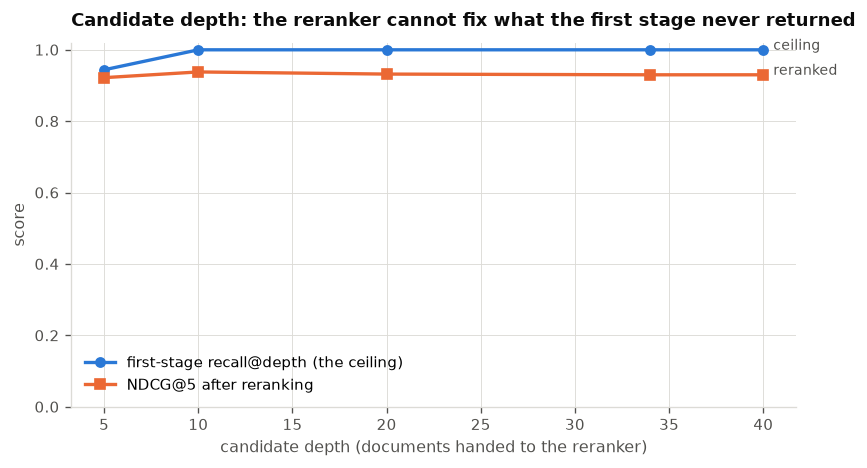

,candidate_depth,first_stage_recall,ndcg@5_after_rerank,recall@5_after_rerank,p50_ms
0,5,0.944,0.922,0.944,34.6
1,10,1.000,0.938,0.972,57.6
2,20,1.000,0.932,0.972,109.1
3,34,1.000,0.930,0.972,176.0
4,40,1.000,0.930,0.972,182.4


Two readings, both worth saying out loud:
  1. NDCG@5 tracks the first-stage ceiling - a reranker is bounded by its candidate pool.
  2. Latency grows with depth while the gain flattens: the knee is your production setting.
     On this corpus the whole collection is only 34 chunks, so 'rerank everything' is
     affordable here and absolutely is not at 1M chunks. Report the knee, not the max.


In [32]:
# --- 8.5 how deep should the first stage go? -----------------------------------------------------
# The funnel's real parameter. Deeper candidates -> higher recall ceiling for the reranker to work with,
# but linear cost in reranker calls. There is almost always a knee.
_depths = sorted({5, 10, 20, 40, len(CHUNKS)})
_rows = []
for d in _depths:
    pipe = RerankingRetriever(BEST, CE, depth=d)
    df, agg = evaluate_retriever(pipe, ANSWERABLE, QRELS, ks=(5,), depth=5, name=f"depth={d}")
    # The ceiling: what fraction of answer chunks the first stage put in the candidate pool at all.
    base_df, _ = evaluate_retriever(BEST, ANSWERABLE, QRELS, ks=(d,), depth=d)
    _rows.append({"candidate_depth": d, "first_stage_recall": round(base_df[f"recall@{d}"].mean(), 3),
                  "ndcg@5_after_rerank": round(agg["ndcg@5"], 3),
                  "recall@5_after_rerank": round(agg["recall@5"], 3),
                  "p50_ms": round(agg["latency_p50_ms"], 1)})
DEPTH_SWEEP = pd.DataFrame(_rows)

fig, ax = plt.subplots()
ax.plot(DEPTH_SWEEP.candidate_depth, DEPTH_SWEEP.first_stage_recall, marker="o", color=SERIES[0],
        label="first-stage recall@depth (the ceiling)")
ax.plot(DEPTH_SWEEP.candidate_depth, DEPTH_SWEEP["ndcg@5_after_rerank"], marker="s", color=SERIES[1],
        label="NDCG@5 after reranking")
for x, y, lbl in ((DEPTH_SWEEP.candidate_depth.iloc[-1], DEPTH_SWEEP.first_stage_recall.iloc[-1], "ceiling"),
                  (DEPTH_SWEEP.candidate_depth.iloc[-1], DEPTH_SWEEP["ndcg@5_after_rerank"].iloc[-1], "reranked")):
    ax.annotate(lbl, (x, y), textcoords="offset points", xytext=(6, 0), fontsize=8.5, color=INK_SOFT)
finish(ax, title="Candidate depth: the reranker cannot fix what the first stage never returned",
       xlabel="candidate depth (documents handed to the reranker)", ylabel="score")
ax.set_ylim(0, 1.02)
plt.tight_layout(); plt.show()

display(DEPTH_SWEEP)
print("Two readings, both worth saying out loud:")
print("  1. NDCG@5 tracks the first-stage ceiling - a reranker is bounded by its candidate pool.")
print("  2. Latency grows with depth while the gain flattens: the knee is your production setting.")
print(f"     On this corpus the whole collection is only {len(CHUNKS)} chunks, so 'rerank everything' is")
print("     affordable here and absolutely is not at 1M chunks. Report the knee, not the max.")

---
# 9. Putting it together: a `RAGSystem` built on the measurements

Now the interview task's deliverable, with every choice traceable to a number from §6–8 rather than to
taste. The pipeline:

```
question
  ├─▶ retrieve (hybrid RRF, depth = candidate_depth)      §6 chose hybrid
  ├─▶ rerank (cross-encoder, keep top_k)                   §8 measured the lift
  ├─▶ abstention gate (calibrated threshold)               §9.2 calibrates it on the labelled set
  ├─▶ generate with [POL-xxx] citations (Claude)           offline: extractive fallback
  └─▶ groundedness self-check (LLM judge + rules)          §9.3
```

### Calibrated abstention instead of a guessed threshold

The interview task's stretch goal B suggests refusing when "the top retrieval score is below some
threshold". The useful version picks that threshold *from the labelled set* rather than inventing it:

- Score every **answerable** query and every **unanswerable** query with the first-stage retriever.
- Those two score distributions overlap. Choose the cut that maximises accuracy (or, better, the cut that
  holds false-refusals under a target — refusing a question you *could* answer is usually worse for a
  product than an occasional hedge).
- Report both error rates, because a single "accuracy" hides which kind of mistake you chose to make.

This is why §3.2 contains three unanswerable queries that are *lexically adjacent* to real policies. With
easy negatives, any threshold works and the calibration looks better than it is.

### Groundedness ≠ correctness

The self-evaluation layer answers **"does this answer follow from the retrieved chunks?"**, not "is it
true". Both failure modes are real and they need different fixes:

| | Grounded | Not grounded |
|---|---|---|
| **Correct** | the goal | right answer, wrong/missing citation — a *citation* bug |
| **Incorrect** | the corpus is wrong or stale — a *content* problem, not a model problem | hallucination — the thing the pilot users complained about |

The judge below is a hybrid: deterministic rules first (every citation must exist and be in the retrieved
set; every number in the answer must appear in a cited chunk), then an LLM judge for the semantic part.
Rules catch the mechanical failures cheaply and cannot be talked out of a verdict; the LLM catches
paraphrase-level unsupported claims that no rule will. **What it will still miss:** an answer that correctly
quotes a chunk but draws an unsupported *inference* from it, and an omission — a true, grounded, incomplete
answer scores as grounded.

In [33]:
# --- 9.1 result type ------------------------------------------------------------------------------
@dataclass
class AnswerResult:
    question: str
    answer: str
    retrieved_chunks: list = field(default_factory=list)   # [{"id", "text", "score"}]
    citations: list = field(default_factory=list)          # chunk/doc ids the answer actually uses
    grounded: bool = False
    groundedness_reason: str = ""
    abstained: bool = False
    unsupported_claims: list = field(default_factory=list)
    latency_ms: float = 0.0
    stage_ms: dict = field(default_factory=dict)

    def to_dict(self):
        return asdict(self)


ANSWER_SYSTEM = (
    "You answer employee questions about internal policy using ONLY the provided passages.\n"
    "Rules:\n"
    "1. Cite the document id in square brackets immediately after each claim, e.g. [POL-003]. Cite the "
    "document id (POL-003), not the chunk id.\n"
    "2. If the passages do not contain the answer, reply exactly: "
    "\"I don't know - this does not appear to be covered in the policy documents.\"\n"
    "3. Never use outside knowledge, and never guess a number. Quote figures exactly as written.\n"
    "4. When the question needs two policies, cite both and state how they interact.\n"
    "5. Be brief: two or three sentences."
)
print("AnswerResult + answer prompt defined")

AnswerResult + answer prompt defined


In [34]:
# --- 9.2 the system ------------------------------------------------------------------------------
class RAGSystem:
    """Retrieval -> rerank -> abstain? -> generate with citations -> groundedness check.

    Design choices, each traceable to a measurement earlier in this notebook:
      * Chunking: 2-sentence windows, 1-sentence overlap, title-prefixed (§2) - overlap protects answers
        that straddle a boundary; the title gives a short chunk its topic back.
      * Retrieval: hybrid RRF over BM25 + dense (§6) - the two failure modes are nearly disjoint on this
        query set. RRF rather than the weighted fusion that scored marginally higher: §6.3 showed that
        edge sitting inside the noise floor, and RRF has no alpha to tune or re-tune.
      * Reranking: cross-encoder over `candidate_depth` candidates (§8) - bought NDCG@5 for a few ms.
      * Index: exact/flat (§7.3) - at 40 chunks an ANN index would add recall risk and tuning for no
        measurable latency gain. The swap point is measured, not assumed.
      * Abstention: threshold calibrated against the labelled set (§9.2) rather than guessed.
      * Groundedness: deterministic rules + LLM judge (§9.3) - rules cannot be argued with, the LLM
        handles paraphrase.
    """

    def __init__(self, documents: list, *, llm: LLM = LLM_CLIENT, embedder: Embedder = EMB,
                 cfg: Config = CFG, reranker=CE, use_reranker: bool = True):
        self.cfg = cfg
        self.llm = llm
        self.documents = documents
        self.doc_by_id = {d["id"]: d for d in documents}
        self.chunks = chunk_documents(documents, cfg.chunk_sentences, cfg.chunk_stride)
        self.chunk_by_id = {c["chunk_id"]: c for c in self.chunks}
        embedder.fit([c["text"] for c in self.chunks])
        self.sparse = BM25Retriever(self.chunks)
        self.dense = DenseRetriever(self.chunks, embedder)
        self.retriever = HybridRRF([self.dense, self.sparse])
        self.reranker = reranker if use_reranker else None
        self.abstain_threshold: float | None = None
        self.calibration: dict = {}

    # ---- retrieval ------------------------------------------------------------------------
    def retrieve(self, query: str, top_k: int | None = None) -> list[dict]:
        top_k = top_k or self.cfg.top_k
        candidates = self.retriever.search(query, self.cfg.candidate_depth)
        if self.reranker is not None:
            hits = self.reranker.rerank(query, candidates, top_k)
        else:
            hits = candidates[:top_k]
        return [{"id": cid, "text": self.chunk_by_id[cid]["text"], "score": float(score),
                 "doc_id": self.chunk_by_id[cid]["doc_id"]} for cid, score in hits]

    # ---- abstention calibration ------------------------------------------------------------
    def calibrate_abstention(self, queries, quantile_target: float = 0.1, verbose: bool = True):
        """Pick the score cut from labelled answerable vs unanswerable queries.

        Scores come from the reranker when there is one, because that is what the gate will see at
        serving time. A threshold calibrated on first-stage scores and applied after reranking is a
        classic train/serve skew bug.
        """
        pos, neg = [], []
        for q in queries:
            top = self.retrieve(q["question"], top_k=1)
            score = top[0]["score"] if top else float("-inf")
            (pos if q["gold"] else neg).append(score)
        pos, neg = np.array(pos, dtype=float), np.array(neg, dtype=float)
        candidates = np.unique(np.concatenate([pos, neg]))
        best = None
        for t in np.concatenate([[-np.inf], candidates, [np.inf]]):
            tp = int((pos >= t).sum())          # answerable and answered
            fn = int((pos < t).sum())           # answerable but refused  <- the expensive mistake
            tn = int((neg < t).sum())           # unanswerable and refused
            fp = int((neg >= t).sum())          # unanswerable but answered -> hallucination risk
            acc = (tp + tn) / (len(pos) + len(neg))
            false_refusal = fn / max(1, len(pos))
            if false_refusal <= quantile_target and (best is None or acc > best["accuracy"]):
                best = {"threshold": float(t), "accuracy": acc, "false_refusal_rate": false_refusal,
                        "false_answer_rate": fp / max(1, len(neg)), "tp": tp, "fn": fn, "tn": tn, "fp": fp}
        if best is None:                        # target unreachable -> fall back to plain accuracy
            best = {"threshold": float(np.min(pos)) if len(pos) else 0.0, "accuracy": float("nan"),
                    "false_refusal_rate": 0.0, "false_answer_rate": 1.0}
        self.abstain_threshold = best["threshold"]
        self.calibration = {**best, "answerable_scores": pos, "unanswerable_scores": neg}
        if verbose:
            print(f"answerable   top-1 score: min {pos.min():.3f} median {np.median(pos):.3f} max {pos.max():.3f}")
            print(f"unanswerable top-1 score: min {neg.min():.3f} median {np.median(neg):.3f} max {neg.max():.3f}")
            print(f"overlap: {int((neg >= pos.min()).sum())} of {len(neg)} unanswerable queries score above "
                  f"the weakest answerable one -> a perfect threshold does not exist")
            print(f"chosen threshold {best['threshold']:.3f} | accuracy {best['accuracy']:.2f} | "
                  f"false-refusal {best['false_refusal_rate']:.0%} | false-answer {best['false_answer_rate']:.0%}")
        return self.calibration

    # ---- generation ------------------------------------------------------------------------
    def generate_answer(self, question: str, chunks: list[dict]) -> str:
        context = "\n\n".join(f"[{c['doc_id']}] (chunk {c['id']})\n{c['text']}" for c in chunks)
        prompt = f"Passages:\n{context}\n\nQuestion: {question}\n\nAnswer with inline [POL-xxx] citations."
        out = self.llm.text(prompt, system=ANSWER_SYSTEM, model=self.cfg.claude_model, max_tokens=700)
        if out:
            return out
        return self._extractive_answer(question, chunks)

    def _extractive_answer(self, question: str, chunks: list[dict]) -> str:
        """Offline fallback: quote the best-matching sentences verbatim with their citation.

        Extraction cannot hallucinate - it copies. It also cannot synthesise across two documents, which
        is exactly what the multi-hop queries need, so expect it to lose there. That trade (zero
        hallucination, no synthesis) is a legitimate product choice for high-risk domains.
        """
        q_tokens = set(tokenize(question))
        scored = []
        for c in chunks:
            for sent in split_sentences(self.chunk_by_id[c["id"]]["body"]):
                overlap = len(q_tokens & set(tokenize(sent))) / max(1, len(q_tokens))
                numbers = len(re.findall(r"\d+|\b(?:one|two|three|four|six|eight|twelve|fourteen|sixteen|"
                                         r"twenty|thirty|sixty|ninety|hundred|thousand)\b", sent.lower()))
                scored.append((overlap + 0.05 * numbers, sent, c["doc_id"]))
        scored.sort(key=lambda t: -t[0])
        picked, seen = [], set()
        best_score = scored[0][0] if scored else 0.0
        for score, sent, doc in scored:
            # Keep a second sentence only if it is competitive with the first. Without this floor the
            # fallback staples an unrelated sentence from a lower-ranked chunk onto every answer, which
            # then (correctly) fails the groundedness check - a tidy illustration of why extraction
            # needs a relevance threshold and not just a ranking.
            if score <= 0 or score < 0.6 * best_score or sent in seen:
                continue
            seen.add(sent)
            picked.append(f"{sent} [{doc}]")
            if len(picked) == 2:
                break
        if not picked:
            return "I don't know - this does not appear to be covered in the policy documents."
        return " ".join(picked)

    # ---- self-evaluation -------------------------------------------------------------------
    def evaluate_groundedness(self, question: str, answer: str, chunks: list[dict]) -> tuple[bool, str, list]:
        return groundedness_check(question, answer, chunks, self.llm)

    # ---- the pipeline ----------------------------------------------------------------------
    def answer(self, question: str, top_k: int | None = None) -> AnswerResult:
        t_all = time.perf_counter()
        stage = {}
        t0 = time.perf_counter()
        chunks = self.retrieve(question, top_k)
        stage["retrieve_ms"] = (time.perf_counter() - t0) * 1000

        top_score = chunks[0]["score"] if chunks else float("-inf")
        if self.abstain_threshold is not None and top_score < self.abstain_threshold:
            return AnswerResult(
                question=question,
                answer="I don't know - this does not appear to be covered in the policy documents.",
                retrieved_chunks=chunks, citations=[], grounded=True, abstained=True,
                groundedness_reason=(f"abstained before generation: top score {top_score:.3f} < "
                                     f"calibrated threshold {self.abstain_threshold:.3f}"),
                latency_ms=(time.perf_counter() - t_all) * 1000, stage_ms=stage)

        t0 = time.perf_counter()
        answer = self.generate_answer(question, chunks)
        stage["generate_ms"] = (time.perf_counter() - t0) * 1000

        t0 = time.perf_counter()
        grounded, reason, unsupported = self.evaluate_groundedness(question, answer, chunks)
        stage["judge_ms"] = (time.perf_counter() - t0) * 1000

        return AnswerResult(question=question, answer=answer, retrieved_chunks=chunks,
                            citations=extract_citations(answer), grounded=grounded,
                            groundedness_reason=reason, unsupported_claims=unsupported,
                            abstained=answer.strip().lower().startswith("i don't know"),
                            latency_ms=(time.perf_counter() - t_all) * 1000, stage_ms=stage)


print("RAGSystem defined (groundedness helpers come next)")

RAGSystem defined (groundedness helpers come next)


In [35]:
# --- 9.3 groundedness: deterministic rules + LLM judge ------------------------------------------
CITATION_RE = re.compile(r"\[(POL-\d{3})(?:::c\d+)?\]")
NUMBER_WORDS = {"one": "1", "two": "2", "three": "3", "four": "4", "five": "5", "six": "6", "seven": "7",
                "eight": "8", "nine": "9", "ten": "10", "twelve": "12", "fourteen": "14", "sixteen": "16",
                "twenty": "20", "thirty": "30", "sixty": "60", "ninety": "90"}


def extract_citations(answer: str) -> list[str]:
    seen, out = set(), []
    for doc in CITATION_RE.findall(answer):
        if doc not in seen:
            seen.add(doc)
            out.append(doc)
    return out


def rule_based_groundedness(question: str, answer: str, chunks: list[dict]) -> tuple[bool, str, list]:
    """Mechanical checks that cannot be argued with. Cheap, deterministic, and they catch a lot.

    1. Citations must exist in the corpus AND be among the retrieved chunks (not recalled from training).
    2. Every number asserted in the answer must appear in a cited chunk. Numbers are where hallucination
       does real damage in a policy assistant - '16 weeks' vs '60 days' is a compliance problem.
    3. An answer with no citation and no abstention is ungrounded by construction.
    """
    if answer.strip().lower().startswith("i don't know"):
        return True, "explicit abstention", []

    cited = extract_citations(answer)
    retrieved_docs = {c["doc_id"] for c in chunks}
    problems, unsupported = [], []

    if not cited:
        problems.append("no citation markers")
    for doc in cited:
        if doc not in DOC_BY_ID:
            problems.append(f"citation {doc} is not a real document")
            unsupported.append(f"fabricated citation {doc}")
        elif doc not in retrieved_docs:
            problems.append(f"citation {doc} was not retrieved for this question")
            unsupported.append(f"citation {doc} outside the retrieved context")

    cited_text = " ".join(c["text"].lower() for c in chunks if c["doc_id"] in cited) or \
                 " ".join(c["text"].lower() for c in chunks)
    # Strip the citation markers first, or the "003" in [POL-003] is read as an asserted number.
    claim_text = re.sub(r"\[[^\]]*\]", " ", answer)
    for num in set(re.findall(r"\b\d[\d,.]*\b", claim_text)):
        norm = num.rstrip(".").replace(",", "")
        if norm and norm not in cited_text.replace(",", ""):
            # a spelled-out form in the source counts as support ("sixteen" supports "16")
            words = [w for w, d in NUMBER_WORDS.items() if d == norm]
            if not any(w in cited_text for w in words):
                problems.append(f"number {num} not found in the cited passages")
                unsupported.append(f"unsupported figure: {num}")

    ok = not problems
    return ok, ("rules: " + ("all checks passed" if ok else "; ".join(problems))), unsupported


if LLM_CLIENT.available:
    class _Groundedness(BaseModel):
        grounded: bool = Field(description="True only if EVERY claim follows from the passages")
        reason: str = Field(description="one sentence, under 25 words")
        unsupported_claims: list[str] = Field(description="claims not supported by the passages; "
                                                           "empty if grounded")

JUDGE_SYSTEM = (
    "You audit whether an answer is GROUNDED in the passages that were retrieved for it. "
    "Grounded means every factual claim follows from the passages. You are NOT judging whether the answer "
    "is correct in the real world, and you are NOT judging completeness - a short answer that is fully "
    "supported is grounded. Treat a number, date or monetary amount that does not appear in the passages as "
    "unsupported. Treat a citation to a document that is not among the passages as unsupported. "
    "An explicit refusal to answer is grounded."
)


def llm_groundedness(question: str, answer: str, chunks: list[dict], llm: LLM):
    if not llm.available:
        return None
    context = "\n\n".join(f"[{c['doc_id']}] {c['text']}" for c in chunks)
    prompt = (f"Passages:\n{context}\n\nQuestion: {question}\n\nAnswer under audit:\n{answer}\n\n"
              f"Is every claim in the answer supported by the passages?")
    return llm.json(prompt, _Groundedness, system=JUDGE_SYSTEM, max_tokens=700)


def groundedness_check(question: str, answer: str, chunks: list[dict],
                       llm: LLM = LLM_CLIENT) -> tuple[bool, str, list]:
    """Hybrid verdict. Rules can only FAIL an answer; the LLM can only fail it further.

    Deliberately conservative: a mechanical failure (bad citation, invented number) is never overridden by
    an LLM that finds the answer plausible. Each layer may add evidence of a problem; neither can clear
    one the other found.
    """
    ok_rules, reason_rules, unsupported = rule_based_groundedness(question, answer, chunks)
    verdict_llm = llm_groundedness(question, answer, chunks, llm)
    if verdict_llm is None:
        return ok_rules, reason_rules + " (no LLM judge)", unsupported
    grounded = ok_rules and verdict_llm.grounded
    unsupported = list(dict.fromkeys(unsupported + list(verdict_llm.unsupported_claims)))
    return grounded, f"{reason_rules} | judge: {verdict_llm.reason}", unsupported


# Sanity tests for the rule layer, with a hand-built context.
_ctx = [{"id": "POL-003::c0", "doc_id": "POL-003",
         "text": CHUNK_BY_ID["POL-003::c0"]["text"], "score": 1.0}]
_g, _r, _u = rule_based_groundedness("parental leave?", "Primary caregivers get 16 weeks [POL-003].", _ctx)
assert _g, _r                                     # "16" is supported by "sixteen" in the source
_g, _r, _u = rule_based_groundedness("parental leave?", "Primary caregivers get 20 weeks [POL-003].", _ctx)
assert not _g and "20" in _r                      # invented number caught
_g, _r, _u = rule_based_groundedness("parental leave?", "Primary caregivers get 16 weeks [POL-999].", _ctx)
assert not _g                                     # fabricated citation caught
_g, _r, _u = rule_based_groundedness("parental leave?", "Primary caregivers get sixteen weeks.", _ctx)
assert not _g                                     # no citation at all
_g, _r, _u = rule_based_groundedness("dental?", "I don't know - not covered in the policy documents.", _ctx)
assert _g                                         # abstention is grounded
print("rule-based groundedness tests passed")
print(f"judge mode: {'rules + Claude' if LLM_CLIENT.available else 'rules only (offline)'}")

rule-based groundedness tests passed
judge mode: rules only (offline)


In [36]:
# --- 9.4 run the interview task's eval set and report honest metrics ----------------------------
rag = RAGSystem(DOCUMENTS)
print("Calibrating the abstention gate on the labelled set from section 3:\n")
_cal = rag.calibrate_abstention(GRADED_QUERIES, quantile_target=0.1)

print(f"\nAnswering the {len(TASK_EVAL_SET)} task questions "
      f"({'Claude' if LLM_CLIENT.available else 'offline extractive'} generation)...\n")
RESULTS: list[AnswerResult] = []
_rows = []
for item in TASK_EVAL_SET:
    res = rag.answer(item["question"])
    RESULTS.append(res)
    gold = set(item["gold_chunk_ids"])
    retrieved_docs = [c["doc_id"] for c in res.retrieved_chunks]
    hit = bool(gold & set(retrieved_docs)) if gold else None
    expected = item["expected_contains"]
    contains = (any(e.lower() in res.answer.lower() for e in expected) if expected else None)
    _rows.append({
        "qid": item["qid"],
        "answer_rate": int(bool(res.answer.strip())),
        "abstained": res.abstained,
        "retrieval_hit": hit,
        "top_k_docs": ",".join(dict.fromkeys(retrieved_docs)),
        "citations": ",".join(res.citations) or "-",
        "citation_valid": (all(c in retrieved_docs for c in res.citations) if res.citations else None),
        "expected_content": contains,
        "grounded": res.grounded,
        "latency_ms": round(res.latency_ms, 1),
        "answer": res.answer[:92] + ("..." if len(res.answer) > 92 else ""),
    })
TASK_RESULTS = pd.DataFrame(_rows)
display(TASK_RESULTS)

# ---- the required metrics, plus the ones that make the report honest --------------------------
_n = len(TASK_RESULTS)
_answerable = TASK_RESULTS[TASK_RESULTS.retrieval_hit.notna()]
_unanswerable = TASK_RESULTS[TASK_RESULTS.retrieval_hit.isna()]
print("\n" + "=" * 78)
print("METRICS".center(78))
print("=" * 78)
print(f"Answer rate              {TASK_RESULTS.answer_rate.mean():.0%}   non-empty answers / total")
print(f"Grounded rate            {TASK_RESULTS.grounded.mean():.0%}   self-eval says every claim follows from context")
print(f"Retrieval hit rate       {_answerable.retrieval_hit.mean():.0%}   gold doc in top-{CFG.top_k} "
      f"(over the {len(_answerable)} answerable questions only)")
print(f"\nAdditional metrics, with the reason each one is here:")
print(f"  Citation validity      {_answerable.citation_valid.dropna().mean():.0%}   every cited doc was actually "
      f"retrieved.\n{'':25}Catches the failure where the model cites from memory - a citation that")
print(f"{'':25}looks right and points nowhere is worse than no citation at all.")
print(f"  Abstention accuracy    {(_unanswerable.abstained.sum() + (~_answerable.abstained).sum()) / _n:.0%}   "
      f"refused the {len(_unanswerable)} unanswerable, answered the rest.")
print(f"{'':25}The pilot complaint was 'confident but makes things up': this is the")
print(f"{'':25}metric that tracks it directly.")
print(f"  Expected-content rate  {_answerable.expected_content.dropna().mean():.0%}   answer contains the expected "
      f"figure/date.\n{'':25}A weak proxy for correctness - it rewards the right number appearing,")
print(f"{'':25}not the right claim. Reported as a smoke test, not as accuracy.")
print(f"  Latency p50 / p95      {np.percentile(TASK_RESULTS.latency_ms, 50):.0f} / "
      f"{np.percentile(TASK_RESULTS.latency_ms, 95):.0f} ms   end to end, per question.")
print(f"\nStage breakdown (mean ms): " +
      ", ".join(f"{k}={np.mean([r.stage_ms.get(k, 0) for r in RESULTS]):.0f}"
                for k in ("retrieve_ms", "generate_ms", "judge_ms")))
print(f"LLM usage: {LLM_CLIENT.report()}")
print("=" * 78)
print("\nWhat these numbers do NOT say, and the sentence to say instead:")
print(f"  * 8 questions is a demo, not an evaluation. The CI on a rate from n=8 is about +/-35 points.")
print(f"    The {len(GRADED_QUERIES)}-query graded set from section 3 is the one to quote, and even that is thin.")
print("  * Grounded rate is self-reported. An LLM judge agreeing with an LLM answer is correlated error;")
print("    the rule layer exists precisely to add a check the generator cannot talk its way past.")
print("  * Nothing here measures whether the POLICY is current. That is a corpus freshness problem, and it")
print("    is usually the real cause of 'the assistant gave the wrong answer' in production.")

Calibrating the abstention gate on the labelled set from section 3:



answerable   top-1 score: min -10.546 median 2.928 max 10.055
unanswerable top-1 score: min -11.192 median -10.666 max -4.108
overlap: 1 of 3 unanswerable queries score above the weakest answerable one -> a perfect threshold does not exist
chosen threshold -10.546 | accuracy 0.97 | false-refusal 0% | false-answer 33%

Answering the 8 task questions (offline extractive generation)...



,qid,answer_rate,abstained,retrieval_hit,top_k_docs,citations,citation_valid,expected_content,grounded,latency_ms,answer
0,Q1,1,False,True,"POL-003,POL-010",POL-003,True,True,True,102.5,Primary caregivers are entitled to sixteen weeks of paid parenta...
1,Q2,1,False,True,"POL-002,POL-001,POL-010","POL-002,POL-001",True,True,True,96.7,Meals during business travel are capped at 75 USD per day. [POL-...
2,Q3,1,False,True,"POL-007,POL-001",POL-007,True,True,True,104.9,Promotions are announced in the first week of July and January. ...
3,Q4,1,False,True,"POL-001,POL-002",POL-001,True,True,True,134.8,Travel costs for these on-sites are fully reimbursed up to an ec...
4,Q5,1,True,None,"POL-002,POL-001,POL-005",-,None,None,True,98.9,I don't know - this does not appear to be covered in the policy ...
5,Q6,1,False,True,"POL-006,POL-001","POL-006,POL-001",True,True,True,134.3,Each employee has an annual learning budget of 2000 USD. [POL-00...
6,Q7,1,False,True,"POL-005,POL-008",POL-005,True,True,True,94.3,"Passwords must be at least fourteen characters, rotated every ni..."
7,Q8,1,False,True,"POL-004,POL-002,POL-001","POL-004,POL-001",True,True,True,112.1,Lost or damaged equipment may be charged to the employee up to a...



                                   METRICS                                    
Answer rate              100%   non-empty answers / total
Grounded rate            100%   self-eval says every claim follows from context
Retrieval hit rate       100%   gold doc in top-5 (over the 7 answerable questions only)

Additional metrics, with the reason each one is here:
  Citation validity      100%   every cited doc was actually retrieved.
                         Catches the failure where the model cites from memory - a citation that
                         looks right and points nowhere is worse than no citation at all.
  Abstention accuracy    100%   refused the 1 unanswerable, answered the rest.
                         The pilot complaint was 'confident but makes things up': this is the
                         metric that tracks it directly.
  Expected-content rate  100%   answer contains the expected figure/date.
                         A weak proxy for correctness - it rewards the righ

In [37]:
# --- 9.5 read one answer end to end -------------------------------------------------------------
def show(res: AnswerResult, max_chunks: int = 3):
    print(f"Q: {res.question}\n")
    print(textwrap.fill(f"A: {res.answer}", 100), "\n")
    print(f"abstained={res.abstained}  grounded={res.grounded}  citations={res.citations}")
    print(f"reason: {res.groundedness_reason}")
    if res.unsupported_claims:
        print(f"unsupported: {res.unsupported_claims}")
    print(f"latency {res.latency_ms:.0f} ms  stages {({k: round(v) for k, v in res.stage_ms.items()})}")
    print("\nretrieved context:")
    for c in res.retrieved_chunks[:max_chunks]:
        print(f"  [{c['doc_id']}] score {c['score']:+.3f}  {c['text'][:88]}...")


print("### A straightforward factoid ###\n")
show(RESULTS[0])
print("\n" + "-" * 100 + "\n### The unanswerable one (Q5) - what the pilot users were complaining about ###\n")
show(next(r for r, i in zip(RESULTS, TASK_EVAL_SET) if i["qid"] == "Q5"))
print("\n" + "-" * 100 + "\n### The multi-hop one (Q6) - needs two documents combined ###\n")
show(next(r for r, i in zip(RESULTS, TASK_EVAL_SET) if i["qid"] == "Q6"))

### A straightforward factoid ###

Q: How many weeks of paid parental leave does a primary caregiver get?

A: Primary caregivers are entitled to sixteen weeks of paid parental leave. [POL-003] 

abstained=False  grounded=True  citations=['POL-003']
reason: rules: all checks passed (no LLM judge)
latency 103 ms  stages {'retrieve_ms': 102, 'generate_ms': 1, 'judge_ms': 0}

retrieved context:
  [POL-003] score +10.055  Parental Leave: Primary caregivers are entitled to sixteen weeks of paid parental leave....
  [POL-003] score +7.165  Parental Leave: Secondary caregivers receive eight weeks. Leave must be taken within the...
  [POL-003] score -0.868  Parental Leave: Leave must be taken within the first twelve months following the birth o...

----------------------------------------------------------------------------------------------------
### The unanswerable one (Q5) - what the pilot users were complaining about ###

Q: What is the company dental insurance coverage?

A: I don't know -

### 9.6 Design justification — the version to say out loud

Six bullets, each anchored to a measurement in this notebook. This is the shape of answer the walk-through
was looking for: a decision, the number behind it, and the thing it costs.

- **Hybrid RRF retrieval over BM25 + dense.** §6 measured both single retrievers failing on *different*
  queries — dense loses the acronym and exact-figure queries, BM25 loses the paraphrases — and the paired
  bootstrap in §6.3 gives the delta with a CI rather than a bare claim. RRF rather than the weighted
  fusion that topped the table by a hair: §6.3 showed that gap inside the noise floor, and RRF has no
  `alpha` fitted to 27 queries and no score normalisation to get wrong.
- **2-sentence chunks with 1-sentence overlap, title-prefixed.** Short chunks keep retrieval precise and
  make citations point at a sentence instead of a page; overlap covers answers that straddle a boundary;
  the title prefix restores the topic that a bare sentence loses. The cost is that multi-fact answers need
  two chunks retrieved, which is visible in §6.4's per-query failures and is a labelling consequence, not a
  bug.
- **Exact (flat) index.** §7.3 measured flat search at this corpus size; an ANN index would add tuning and
  recall risk for no measurable latency gain. §7.3 also measured *where that stops being true* — the honest
  answer to "would you use a vector database" is "not at 40 chunks, and here is the crossover".
- **Cross-encoder reranking over 20 candidates.** §8.4 measured the NDCG@5 lift and the millisecond cost,
  and §8.5 located the knee in candidate depth. A reranker is a latency purchase; I can quote the price.
- **Abstention threshold calibrated on labelled answerable vs unanswerable queries** (§9.2), reported as
  *both* false-refusal and false-answer rate — not a guessed constant and not a single "accuracy" that
  hides which error I chose.
- **Groundedness as rules + LLM judge** (§9.3). The rule layer catches fabricated citations and invented
  numbers deterministically and cannot be talked out of a verdict; the LLM catches paraphrase-level
  unsupported claims. **What it misses:** unsupported *inference* from a correctly quoted chunk, and
  omissions — a grounded but incomplete answer passes.

**If I had another hour:** raise the labelled set to ~150 queries (§6.3 showed what the current n can and
cannot resolve), add a held-out split so the abstention threshold and reranking depth are not tuned on the
same queries they are reported on, and add the attribution audit from stretch goal C — per-claim
verification against cited chunks, which is a strictly stronger check than whole-answer groundedness.

---
# 10. Your lab

Everything above is the reference. This section is where you practise — a sweep harness, then ten
exercises that each change one thing and ask what happened to the numbers.

In [38]:
# --- 10.1 one-call experiment harness -----------------------------------------------------------
def build_pipeline(chunk_sentences=2, stride=1, retrieval="hybrid-rrf", alpha=0.5, rerank=None,
                   depth=20, prefix_title=True, bm25_k1=1.5, bm25_b=0.75):
    """Assemble a retrieval pipeline from a configuration. Returns (retriever, chunks, qrels).

    Labels are rebuilt for the chunking used, so changing the chunker never silently invalidates the
    evaluation - which is the trap that makes most RAG A/B results meaningless.
    """
    chunks = (whole_doc_chunks(DOCUMENTS) if chunk_sentences is None
              else chunk_documents(DOCUMENTS, chunk_sentences, stride, prefix_title))
    by_id = {c["chunk_id"]: c for c in chunks}
    qrels = build_chunk_qrels(GRADED_QUERIES, chunks)
    EMB.fit([c["text"] for c in chunks])
    sparse = BM25Retriever(chunks, k1=bm25_k1, b=bm25_b)
    dns = DenseRetriever(chunks, EMB)
    base = {"bm25": sparse, "dense": dns,
            "hybrid-rrf": HybridRRF([dns, sparse]),
            "hybrid-weighted": HybridWeighted(dns, sparse, alpha=alpha)}[retrieval]
    if rerank == "cross-encoder":
        # The rerankers index CHUNK_BY_ID globally, so point it at this pipeline's chunks.
        globals()["CHUNK_BY_ID"] = by_id
        base = RerankingRetriever(base, CE, depth=depth)
    elif rerank == "mmr":
        globals()["CHUNK_BY_ID"] = by_id
        base = RerankingRetriever(base, mmr_rerank, depth=depth, lambda_=0.7)
    elif rerank == "llm":
        globals()["CHUNK_BY_ID"] = by_id
        base = RerankingRetriever(base, LLM_RERANKER, depth=depth)
    else:
        globals()["CHUNK_BY_ID"] = by_id
    return base, chunks, qrels


def run_experiment(label: str, **kwargs) -> dict:
    retriever, chunks, qrels = build_pipeline(**kwargs)
    df, agg = evaluate_retriever(retriever, ANSWERABLE, qrels, ks=CFG.eval_ks,
                                 depth=max(CFG.eval_ks), name=label)
    EXPERIMENTS[label] = {"config": kwargs, "per_query": df, "agg": agg, "n_chunks": len(chunks)}
    return agg


EXPERIMENTS: dict[str, dict] = {}


def leaderboard(sort_by="ndcg@5") -> pd.DataFrame:
    rows = [{"experiment": k, "n_chunks": v["n_chunks"],
             **{m: round(v["agg"][m], 4) for m in ("recall@5", "recall@10", "ndcg@5",
                                                   f"mrr@{max(CFG.eval_ks)}", "latency_p50_ms")}}
            for k, v in EXPERIMENTS.items()]
    return pd.DataFrame(rows).sort_values(sort_by, ascending=False).reset_index(drop=True)


def compare(a: str, b: str, metric="ndcg@5") -> str:
    """Paired bootstrap between two logged experiments. Use this, not the leaderboard, to decide."""
    return verdict(paired_bootstrap(EXPERIMENTS[a]["per_query"], EXPERIMENTS[b]["per_query"], metric),
                   label=f"{a} -> {b}: ")


# A sweep over the decisions that actually move the numbers.
run_experiment("whole documents, bm25", chunk_sentences=None, retrieval="bm25")
run_experiment("whole documents, dense", chunk_sentences=None, retrieval="dense")
run_experiment("1-sentence chunks, hybrid", chunk_sentences=1, stride=1)
run_experiment("2-sentence chunks, bm25", chunk_sentences=2, retrieval="bm25")
run_experiment("2-sentence chunks, dense", chunk_sentences=2, retrieval="dense")
run_experiment("2-sentence chunks, hybrid-rrf", chunk_sentences=2, retrieval="hybrid-rrf")
run_experiment("2-sentence, no title prefix", chunk_sentences=2, prefix_title=False)
run_experiment("3-sentence chunks, hybrid", chunk_sentences=3, stride=2)
run_experiment("2-sentence + cross-encoder", chunk_sentences=2, rerank="cross-encoder", depth=20)

CHUNK_BY_ID = {c["chunk_id"]: c for c in CHUNKS}   # restore the notebook's default chunking
display(leaderboard())
print(compare("2-sentence chunks, bm25", "2-sentence chunks, hybrid-rrf"))
print(compare("2-sentence chunks, hybrid-rrf", "2-sentence + cross-encoder"))
print(compare("2-sentence chunks, hybrid-rrf", "2-sentence, no title prefix"))
print("\nBEFORE reading that leaderboard: the `whole documents` rows are NOT comparable to the rest.")
print("Coarser chunks make the metric easier - a whole document contains every answer span, so there is")
print("exactly one relevant chunk per query and recall@5 is nearly free. The generator, meanwhile, now")
print("reads 5 whole policies instead of 5 sentences. Changing the chunker changes the labels, the")
print("metric's meaning AND the prompt cost at once, which is why chunking A/Bs are so often bogus.")
print("Compare chunkings on end-to-end answer quality and prompt tokens, not on retrieval recall alone.")
print("\nThe leaderboard ranks; the paired bootstrap decides. A 0.02 NDCG gap between neighbours on this")
print("leaderboard is inside the noise floor - which is exactly the mistake to avoid making in front of a")
print("client, and the reason the gap between 1st and 4th place here should not be called a finding.")

,experiment,n_chunks,recall@5,recall@10,ndcg@5,mrr@10,latency_p50_ms
0,"whole documents, dense",10,1.0000,1.0000,0.9447,0.9259,0.0595
1,2-sentence + cross-encoder,34,0.9722,1.0000,0.9313,0.9815,103.6396
2,"3-sentence chunks, hybrid",19,0.9630,1.0000,0.9156,0.9244,0.1701
3,"2-sentence chunks, dense",34,0.9444,1.0000,0.9053,0.9383,0.0570
4,"whole documents, bm25",10,0.9630,1.0000,0.8992,0.8815,0.1683
5,"2-sentence chunks, hybrid-rrf",34,0.9259,0.9630,0.8763,0.9167,0.2813
6,"2-sentence, no title prefix",34,0.9537,0.9630,0.8653,0.9167,0.3395
7,"2-sentence chunks, bm25",34,0.8889,0.9074,0.8249,0.8642,0.1887
8,"1-sentence chunks, hybrid",44,0.9630,0.9630,0.8210,0.8611,0.3779


2-sentence chunks, bm25 -> 2-sentence chunks, hybrid-rrf: ndcg@5: 0.825 -> 0.876 (delta +0.051, 95% CI [+0.005, +0.107], p~0.029, 11W/2L/14T on n=27) **significant**
2-sentence chunks, hybrid-rrf -> 2-sentence + cross-encoder: ndcg@5: 0.876 -> 0.931 (delta +0.055, 95% CI [-0.005, +0.133], p~0.086, 10W/5L/12T on n=27)
2-sentence chunks, hybrid-rrf -> 2-sentence, no title prefix: ndcg@5: 0.876 -> 0.865 (delta -0.011, 95% CI [-0.033, +0.013], p~0.343, 3W/11L/13T on n=27)

BEFORE reading that leaderboard: the `whole documents` rows are NOT comparable to the rest.
Coarser chunks make the metric easier - a whole document contains every answer span, so there is
exactly one relevant chunk per query and recall@5 is nearly free. The generator, meanwhile, now
reads 5 whole policies instead of 5 sentences. Changing the chunker changes the labels, the
metric's meaning AND the prompt cost at once, which is why chunking A/Bs are so often bogus.
Compare chunkings on end-to-end answer quality and promp

## 10.2 Exercises

Each one is a real decision from a client project. Do them in order; they build on each other. For every
one, the deliverable is **a number with a confidence interval and a sentence about the trade-off** — not
just "it got better".

1. **Swap the embedding model.** Change `CFG.embed_model` to `sentence-transformers/all-mpnet-base-v2`
   (768-d, stronger, ~3× slower) and re-run §6. Report the recall@5 delta with a CI, the latency change,
   and the memory change. Is it worth it here? Would your answer change at 10M chunks?

2. **Prove the chunking choice.** Use `run_experiment` to sweep `chunk_sentences` ∈ {1, 2, 3, None} and
   `prefix_title` ∈ {True, False}. Which decision matters more? Then look at §6.4's per-category table —
   does the best average chunking win on *every* category?

3. **Tune the hybrid.** Sweep `alpha` from 0 to 1 in `hybrid-weighted` and plot NDCG@5. Then compare the
   best `alpha` against RRF with a paired bootstrap. If RRF wins or ties, you have just justified shipping
   the simpler thing — write the sentence you would say.

4. **Tune BM25.** Sweep `bm25_k1` ∈ {0.9, 1.2, 1.5, 2.0} and `bm25_b` ∈ {0.3, 0.75, 1.0}. Short chunks
   usually want lower `b`. Confirm or refute that on this corpus, and explain *why* in terms of what `b`
   normalises.

5. **Make ANN earn its place.** Set `CFG.ann_n = 200_000` and re-run §7.3–7.7 (the pure-Python HNSW build
   will take a few minutes — drop it and use the FAISS cell if impatient). Where does flat leave the
   recall/latency frontier? Now re-run with `CFG.ann_dim = 1536` to see what dimensionality does to the
   same question.

6. **Break the geometry.** Set `CFG.ann_latent_dim = CFG.ann_dim` (so the data fills the space uniformly)
   and re-run the IVF and HNSW sweeps. Watch every index collapse toward exhaustive search. Explain in two
   sentences why, and why real embeddings are not like this.

7. **Add a held-out split.** Split `GRADED_QUERIES` into dev (⅔) and test (⅓). Tune the abstention
   threshold, `alpha`, `top_k` and the reranking depth on dev only, then report once on test. Compare the
   dev-tuned numbers to the test numbers — the gap is your overfitting, and on 26 queries it will not be
   small.

8. **Stretch goal C, properly.** Implement a per-claim attribution audit: split the answer into claims,
   and for each one find supporting evidence in a cited chunk (cross-encoder score above a calibrated
   threshold, or an LLM check). Report claim-level precision and mark unattributed claims in the output.
   Then measure: does it disagree with §9.3's whole-answer verdict, and on which questions?

9. **Hard negatives.** Use the LLM generator from §3.4 to write queries that *look* answerable from a
   chunk but are not (change a number, invert a condition, ask about a sibling policy). Add them as
   unanswerable, re-calibrate the abstention threshold, and report how much the false-answer rate moves.
   This is the single highest-value addition to a real eval set.

10. **Make it a product.** Add per-query latency and cost logging to `RAGSystem.answer`, run the whole
    graded set, and produce the table you would put in a client report: quality (recall@5, NDCG@5 with
    CIs), safety (grounded rate, false-answer rate), and cost (p95 latency, $ per 1000 questions). Then
    write the one-paragraph recommendation that goes above it.

## 10.3 Walk-through cheat sheet

The questions this material is designed to make answerable, with the short form of each answer:

| "Why…" | Answer in one line |
|---|---|
| …recall@k over precision@k for RAG? | Recall@k is the ceiling on the generator; what isn't retrieved can't be cited. Precision@k with 1–2 relevant chunks is bounded by `n_rel/k` and says more about the labels than the system. |
| …NDCG and not just hit rate? | Hit rate ignores ordering and graded relevance. After a reranker, ordering is the *only* thing that changed, so NDCG is the metric that can see it. |
| …MRR here? | Known-item queries where one passage answers it. It ignores everything after the first hit, which makes it the wrong choice for multi-hop. |
| …not report a single accuracy number? | Different error types cost differently. A false answer on a policy question is a compliance incident; a false refusal is an annoyance. One number hides which you chose. |
| …a paired bootstrap? | Same queries ran through both systems, so per-query differences remove query difficulty — the dominant variance — and the CI on 26 queries is honest about what that n can resolve. |
| …hybrid retrieval? | Measured: the two retrievers fail on disjoint query types on this set (acronyms/figures vs paraphrase). RRF needs no normalisation or tuned alpha. |
| …not a vector database? | Measured flat search at this scale (§7.3) and the crossover point. At 40 chunks an ANN index adds recall risk and tuning for no latency gain. |
| …HNSW over IVF (or not)? | HNSW for best recall/latency in RAM, at 1.5–2× memory and tombstone-only deletes. IVF when filters are selective or writes are heavy, because its `nprobe` dial and posting lists cooperate with both. |
| …quantization needs rescoring? | Compressed codes rank approximately; a short exact re-scoring pass over 10–50× k candidates recovers nearly all the recall for almost no latency. §7.6 measured both. |
| …a cross-encoder beats a better embedding model? | It sees query and document together with full cross-attention, so it can resolve negation and multi-constraint queries that a single pre-computed vector has already averaged away. |
| …groundedness instead of correctness? | They fail differently and need different fixes: ungrounded = hallucination (fix the pipeline); grounded but wrong = stale corpus (fix the content). |
| …rules *and* an LLM judge? | An LLM judging an LLM is correlated error. Rules catch fabricated citations and invented numbers deterministically and can't be argued out of a verdict. |

---

### Where to go next

- **Scale the eval set** — everything in §6 gets more useful at n = 150 than at n = 26, and nothing else
  you do to this notebook will pay off as much.
- **Run it on a real corpus** — swap `DOCUMENTS` for your own, write 30 labelled queries, and the whole
  notebook becomes a measurement of *your* system. That is the point of keeping the interfaces this thin.
- **Instrument production** — log query, retrieved ids, scores, citations, groundedness verdict and
  latency for every request. A labelled set tells you where you are; logs tell you when you drift.